# Conservation-Aware 3D Geometric Deep Learning for Digital Bioprospecting

**Target application:** *Lilium mackliniae* (Siroi lily) and endemic alpine-flora candidate metabolites  
**Compute target:** NVIDIA A100 80 GB on Google Colab  
**Primary endpoints:** ALOX15 inhibition, COX-2 inhibition, and NRF2/ARE activation

This notebook is a complete, reproducible computational experiment. It:

1. downloads and snapshots ChEMBL and PubChem assay records;
2. applies strict structure and assay-quality filters;
3. creates a scaffold-disjoint split shared by all models;
4. trains ECFP4 tree baselines, a 2D neural MPNN, and a multi-conformer 3D equivariant MPNN;
5. performs invariance, gradient, leakage, and data-integrity tests;
6. produces metrics, confidence intervals, plots, ablations, candidate rankings, checkpoints, and a paper-ready ZIP archive.

> **Scientific boundary:** Predictions are computational prioritizations, not evidence that a molecule occurs in *L. mackliniae*, binds a target in vivo, or is therapeutically effective. Candidate provenance must be supplied separately and retained in every result table.

### How to run

1. In Colab choose **Runtime → Change runtime type → A100 GPU**.
2. Run all cells in order.
3. The default `paper` profile performs the full experiment. For debugging, change `RUN_PROFILE` to `quick` or `smoke` in the configuration cell.
4. Upload a `candidate_metabolites.csv` when prompted, or place it in the project input directory. A template is generated automatically.

## 1. Environment setup

In [ ]:
# Install only packages not already available. Do not reinstall PyTorch: Colab's build is CUDA-matched.
import importlib.util, subprocess, sys, os

REQUIRED = {
    "rdkit": "rdkit>=2024.9.1",
    "torch_geometric": "torch-geometric>=2.6.1",
    "xgboost": "xgboost>=2.1.0",
    "tqdm": "tqdm>=4.66",
    "joblib": "joblib>=1.4",
    "tabulate": "tabulate>=0.9",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages are already installed.")

Installing: ['rdkit>=2024.9.1', 'torch-geometric>=2.6.1']


In [ ]:
import os, sys, json, math, time, random, hashlib, platform, warnings, shutil, zipfile
from dataclasses import dataclass, asdict
from pathlib import Path
from datetime import datetime, timezone
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import joblib

import sklearn
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    matthews_corrcoef, f1_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix
)
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import calibration_curve
from scipy.stats import pearsonr, spearmanr

import xgboost as xgb

from rdkit import Chem, RDLogger, rdBase, DataStructs
from rdkit.Chem import AllChem, Descriptors, Crippen, rdMolDescriptors
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem import rdFingerprintGenerator

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import global_add_pool, global_mean_pool
from torch_geometric.utils import softmax as pyg_softmax

RDLogger.DisableLog("rdApp.warning")
warnings.filterwarnings("ignore", category=FutureWarning)

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("PyG:", __import__('torch_geometric').__version__)
print("RDKit:", rdBase.rdkitVersion)
print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)

Python: 3.12.13
PyTorch: 2.11.0+cu128
PyG: 2.8.0
RDKit: 2026.03.4
scikit-learn: 1.6.1
XGBoost: 3.3.0


## 2. Configuration and reproducibility

In [ ]:
@dataclass
class Config:
    # Execution profile: paper (full), quick (bounded real data), smoke (synthetic end-to-end test)
    run_profile: str = os.getenv("BIOPROSPECT_PROFILE", "paper").lower()
    project_name: str = "sirolily_geometric_bioprospecting"
    base_seed: int = 20260717

    # Strictness
    strict_data_validation: bool = True
    require_a100_for_paper: bool = True

    # Endpoints
    chembl_targets: dict = None
    pubchem_are_aid: int = 743219
    pubchem_are_viability_aid: int = 743203

    # ChEMBL curation
    chembl_activity_type: str = "IC50"
    chembl_units: str = "nM"
    minimum_assay_confidence: int = 8
    max_replicate_range_log_units: float = 2.0

    # 3D graph generation
    initial_conformers: int = 10
    retained_conformers: int = 3
    conformer_energy_window_kcal: float = 10.0
    conformer_rms_prune_angstrom: float = 0.75
    radius_cutoff_angstrom: float = 5.0
    max_spatial_neighbors: int = 64
    graph_jobs: int = max(1, min(8, (os.cpu_count() or 2) - 1))

    # Model
    hidden_dim: int = 256
    num_layers: int = 6
    rbf_dim: int = 32
    dropout: float = 0.08
    coord_scale: float = 0.05

    # Training
    epochs: int = 80
    seeds: tuple = (13, 37, 73, 101, 151)
    max_lr: float = 1e-3
    weight_decay: float = 1e-4
    pct_start: float = 0.10
    gradient_clip: float = 1.0
    patience: int = 18
    batch_atom_budget: int = 16000  # used to derive a conservative molecule batch size
    num_workers: int = 4
    use_bfloat16: bool = True
    enable_torch_compile: bool = False  # dynamic graph shapes may make compilation slower

    # Evaluation
    bootstrap_iterations: int = 1000
    split_fractions: tuple = (0.70, 0.15, 0.15)
    split_seed_search_limit: int = 1000
    ecfp_bits: int = 2048
    ecfp_radius: int = 2
    run_ablations: bool = True
    run_multitask: bool = True

    # Optional real-data cap for quick profile
    quick_max_per_task: int = 700

    def __post_init__(self):
        if self.chembl_targets is None:
            self.chembl_targets = {
                "ALOX15": {"target_chembl_id": "CHEMBL2903", "kind": "regression"},
                "COX2": {"target_chembl_id": "CHEMBL230", "kind": "regression"},
            }
        if self.run_profile == "quick":
            self.initial_conformers = 5
            self.retained_conformers = 2
            self.hidden_dim = 128
            self.num_layers = 4
            self.epochs = 12
            self.seeds = (13,)
            self.bootstrap_iterations = 200
            self.run_ablations = False
            self.run_multitask = True
            self.num_workers = 2
        elif self.run_profile == "smoke":
            self.initial_conformers = 2
            self.retained_conformers = 1
            self.hidden_dim = 32
            self.num_layers = 1
            self.rbf_dim = 8
            self.epochs = 1
            self.seeds = (13,)
            self.bootstrap_iterations = 30
            self.run_ablations = True
            self.run_multitask = True
            self.num_workers = 0
            self.graph_jobs = 1
            self.require_a100_for_paper = False

CONFIG = Config()
assert CONFIG.run_profile in {"paper", "quick", "smoke"}

IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content" if IN_COLAB else "/mnt/data") / CONFIG.project_name
DIRS = {
    "raw": ROOT / "data" / "raw",
    "interim": ROOT / "data" / "interim",
    "processed": ROOT / "data" / "processed",
    "splits": ROOT / "data" / "splits",
    "models": ROOT / "models",
    "figures": ROOT / "figures",
    "tables": ROOT / "tables",
    "logs": ROOT / "logs",
    "input": ROOT / "input",
}
for path in DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

with open(ROOT / "config.json", "w") as f:
    json.dump(asdict(CONFIG), f, indent=2, default=list)

print(json.dumps(asdict(CONFIG), indent=2, default=list))
print("Project directory:", ROOT)

{
  "run_profile": "paper",
  "project_name": "sirolily_geometric_bioprospecting",
  "base_seed": 20260717,
  "strict_data_validation": true,
  "require_a100_for_paper": true,
  "chembl_targets": {
    "ALOX15": {
      "target_chembl_id": "CHEMBL2903",
      "kind": "regression"
    },
    "COX2": {
      "target_chembl_id": "CHEMBL230",
      "kind": "regression"
    }
  },
  "pubchem_are_aid": 743219,
  "pubchem_are_viability_aid": 743203,
  "chembl_activity_type": "IC50",
  "chembl_units": "nM",
  "minimum_assay_confidence": 8,
  "max_replicate_range_log_units": 2.0,
  "initial_conformers": 10,
  "retained_conformers": 3,
  "conformer_energy_window_kcal": 10.0,
  "conformer_rms_prune_angstrom": 0.75,
  "radius_cutoff_angstrom": 5.0,
  "max_spatial_neighbors": 64,
  "graph_jobs": 8,
  "hidden_dim": 256,
  "num_layers": 6,
  "rbf_dim": 32,
  "dropout": 0.08,
  "coord_scale": 0.05,
  "epochs": 80,
  "seeds": [
    13,
    37,
    73,
    101,
    151
  ],
  "max_lr": 0.001,
  "weight_

In [ ]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    torch.set_float32_matmul_precision("high")

seed_everything(CONFIG.base_seed)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
BF16_AVAILABLE = bool(torch.cuda.is_available() and torch.cuda.is_bf16_supported())

print("Device:", DEVICE)
print("Accelerator:", GPU_NAME)
print("BF16 available:", BF16_AVAILABLE)
if CONFIG.run_profile == "paper" and CONFIG.require_a100_for_paper:
    assert "A100" in GPU_NAME, (
        "Paper profile requires an A100. In Colab choose Runtime > Change runtime type > A100 GPU, "
        "or set require_a100_for_paper=False deliberately."
    )

Device: cuda
Accelerator: NVIDIA A100-SXM4-80GB
BF16 available: True


## 3. Source manifest and robust HTTP utilities

In [ ]:
SOURCE_MANIFEST = {
    "chembl_api": "https://www.ebi.ac.uk/chembl/api/data",
    "pubchem_pug_rest": "https://pubchem.ncbi.nlm.nih.gov/rest/pug",
    "ALOX15_target": "CHEMBL2903",
    "COX2_target": "CHEMBL230",
    "NRF2_ARE_assay_AID": CONFIG.pubchem_are_aid,
    "NRF2_ARE_viability_AID": CONFIG.pubchem_are_viability_aid,
    "retrieval_started_utc": datetime.now(timezone.utc).isoformat(),
}
with open(ROOT / "source_manifest.json", "w") as f:
    json.dump(SOURCE_MANIFEST, f, indent=2)


def make_session() -> requests.Session:
    session = requests.Session()
    retries = Retry(
        total=8, connect=8, read=8,
        backoff_factor=1.0,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=("GET", "POST"),
        respect_retry_after_header=True,
    )
    adapter = HTTPAdapter(max_retries=retries, pool_connections=20, pool_maxsize=20)
    session.mount("https://", adapter)
    session.headers.update({"User-Agent": "SiroiLilyGeometricBioprospecting/1.0 academic-research"})
    return session

SESSION = make_session()


def request_bytes(url: str, params=None, timeout=120) -> bytes:
    response = SESSION.get(url, params=params, timeout=timeout)
    response.raise_for_status()
    return response.content


def request_json(url: str, params=None, timeout=120):
    response = SESSION.get(url, params=params, timeout=timeout)
    response.raise_for_status()
    return response.json()


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def save_json(payload, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        json.dump(payload, f, indent=2)

## 4. ChEMBL acquisition and strict assay curation

In [ ]:
CHEMBL_BASE = SOURCE_MANIFEST["chembl_api"]


def chembl_paginated(resource: str, params: dict, item_key: str, raw_prefix: str):
    """Download a complete ChEMBL result set while saving every raw page."""
    rows, page = [], 0
    url = f"{CHEMBL_BASE}/{resource}.json"
    next_params = dict(params)
    next_params.setdefault("limit", 1000)
    while url:
        payload = request_json(url, params=next_params if page == 0 else None)
        save_json(payload, DIRS["raw"] / f"{raw_prefix}_page_{page:04d}.json")
        rows.extend(payload.get(item_key, []))
        next_url = payload.get("page_meta", {}).get("next")
        if next_url:
            url = next_url if next_url.startswith("http") else "https://www.ebi.ac.uk" + next_url
        else:
            url = None
        next_params = None
        page += 1
    return rows


def fetch_chembl_target_metadata(target_id: str) -> dict:
    payload = request_json(f"{CHEMBL_BASE}/target/{target_id}.json")
    save_json(payload, DIRS["raw"] / f"target_{target_id}.json")
    return payload


def fetch_chembl_molecules(molecule_ids, batch_size=100):
    result = {}
    ids = sorted(set(str(x) for x in molecule_ids if pd.notna(x)))
    for start in tqdm(range(0, len(ids), batch_size), desc="ChEMBL molecule structures"):
        batch = ids[start:start + batch_size]
        # ChEMBL supports Django-style __in filtering. Fall back to individual retrieval if a deployment rejects it.
        try:
            rows = chembl_paginated(
                "molecule", {"molecule_chembl_id__in": ",".join(batch), "limit": batch_size},
                "molecules", f"molecules_{start:06d}"
            )
        except Exception:
            rows = []
            for molecule_id in batch:
                try:
                    rows.append(request_json(f"{CHEMBL_BASE}/molecule/{molecule_id}.json"))
                except Exception as exc:
                    print("Structure retrieval failed:", molecule_id, exc)
        for row in rows:
            mid = row.get("molecule_chembl_id")
            structures = row.get("molecule_structures") or {}
            result[mid] = {
                "canonical_smiles": structures.get("canonical_smiles"),
                "standard_inchi_key": structures.get("standard_inchi_key"),
                "parent_molecule_chembl_id": (row.get("molecule_hierarchy") or {}).get("parent_chembl_id"),
            }
        time.sleep(0.05)
    return pd.DataFrame.from_dict(result, orient="index").rename_axis("molecule_chembl_id").reset_index()


def fetch_chembl_assays(assay_ids, batch_size=100):
    result = {}
    ids = sorted(set(str(x) for x in assay_ids if pd.notna(x)))
    for start in tqdm(range(0, len(ids), batch_size), desc="ChEMBL assay metadata"):
        batch = ids[start:start + batch_size]
        try:
            rows = chembl_paginated(
                "assay", {"assay_chembl_id__in": ",".join(batch), "limit": batch_size},
                "assays", f"assays_{start:06d}"
            )
        except Exception:
            rows = []
            for assay_id in batch:
                try:
                    rows.append(request_json(f"{CHEMBL_BASE}/assay/{assay_id}.json"))
                except Exception as exc:
                    print("Assay retrieval failed:", assay_id, exc)
        for row in rows:
            result[row.get("assay_chembl_id")] = row
        time.sleep(0.05)
    return pd.DataFrame(result.values())


def download_and_curate_chembl(task_name: str, target_id: str) -> pd.DataFrame:
    target = fetch_chembl_target_metadata(target_id)
    if CONFIG.strict_data_validation:
        assert target.get("target_chembl_id") == target_id
        assert target.get("target_type") == "SINGLE PROTEIN", target
        assert str(target.get("organism", "")).lower() == "homo sapiens", target

    activities = chembl_paginated(
        "activity",
        {
            "target_chembl_id": target_id,
            "standard_type": CONFIG.chembl_activity_type,
            "standard_relation": "=",
            "standard_units": CONFIG.chembl_units,
            "limit": 1000,
        },
        "activities",
        f"activity_{task_name}"
    )
    frame = pd.DataFrame(activities)
    if frame.empty:
        raise RuntimeError(f"No ChEMBL activity records returned for {task_name} ({target_id}).")
    frame.to_csv(DIRS["interim"] / f"{task_name}_chembl_download.csv", index=False)

    assay_frame = fetch_chembl_assays(frame["assay_chembl_id"].dropna().unique())
    molecule_frame = fetch_chembl_molecules(frame["molecule_chembl_id"].dropna().unique())
    assay_frame.to_csv(DIRS["interim"] / f"{task_name}_assays.csv", index=False)
    molecule_frame.to_csv(DIRS["interim"] / f"{task_name}_molecules.csv", index=False)

    selected_assay_columns = [c for c in [
        "assay_chembl_id", "confidence_score", "assay_type", "assay_organism",
        "assay_description", "bao_format", "cell_type", "tissue_chembl_id"
    ] if c in assay_frame.columns]
    frame = frame.merge(assay_frame[selected_assay_columns], on="assay_chembl_id", how="left", suffixes=("", "_assay"))
    frame = frame.merge(molecule_frame, on="molecule_chembl_id", how="left", suffixes=("", "_mol"))

    # Resolve structure columns defensively across ChEMBL API versions.
    smiles_candidates = [c for c in ["canonical_smiles", "canonical_smiles_mol"] if c in frame.columns]
    frame["raw_smiles"] = None
    for col in smiles_candidates:
        frame["raw_smiles"] = frame["raw_smiles"].fillna(frame[col])

    frame["standard_value"] = pd.to_numeric(frame.get("standard_value"), errors="coerce")
    frame["confidence_score"] = pd.to_numeric(frame.get("confidence_score"), errors="coerce")
    validity = frame.get("data_validity_comment", pd.Series(index=frame.index, dtype=object)).fillna("").astype(str).str.lower()
    potential_duplicate = frame.get("potential_duplicate", pd.Series(0, index=frame.index))
    potential_duplicate = potential_duplicate.fillna(0).astype(str).str.lower().isin({"1", "true", "yes"})

    keep = (
        frame["standard_value"].gt(0)
        & frame["raw_smiles"].notna()
        & frame["confidence_score"].ge(CONFIG.minimum_assay_confidence)
        & ~potential_duplicate
        & ~validity.str.contains("outside typical range|non standard unit|invalid", regex=True)
    )
    filtered = frame.loc[keep].copy()
    filtered["label"] = 9.0 - np.log10(filtered["standard_value"].astype(float))
    filtered["task"] = task_name
    filtered["kind"] = "regression"
    filtered["source"] = "ChEMBL"
    filtered["source_record_id"] = filtered.get("activity_id")

    audit = {
        "task": task_name,
        "target_id": target_id,
        "raw_rows": int(len(frame)),
        "filtered_rows_before_structure_standardization": int(len(filtered)),
        "confidence_threshold": CONFIG.minimum_assay_confidence,
        "activity_type": CONFIG.chembl_activity_type,
        "units": CONFIG.chembl_units,
    }
    save_json(audit, DIRS["logs"] / f"{task_name}_chembl_filter_audit.json")
    return filtered

## 5. PubChem NRF2/ARE acquisition with cytotoxicity exclusion

In [ ]:
PUBCHEM_BASE = SOURCE_MANIFEST["pubchem_pug_rest"]


def read_pubchem_assay_csv(aid: int) -> pd.DataFrame:
    """Retrieve concise assay rows; fall back to full CSV if concise is unavailable."""
    errors = []
    for suffix in ("concise/CSV", "CSV"):
        url = f"{PUBCHEM_BASE}/assay/aid/{aid}/{suffix}"
        try:
            content = request_bytes(url, timeout=240)
            raw_path = DIRS["raw"] / f"pubchem_AID_{aid}_{suffix.replace('/', '_')}.csv"
            raw_path.write_bytes(content)
            frame = pd.read_csv(raw_path, low_memory=False)
            if len(frame):
                return frame
        except Exception as exc:
            errors.append(f"{suffix}: {exc}")
    raise RuntimeError(f"Unable to retrieve PubChem AID {aid}: {errors}")


def normalize_columns(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    frame.columns = [
        str(c).strip().lower().replace(" ", "_").replace("-", "_").replace(".", "_")
        for c in frame.columns
    ]
    return frame


def find_column(frame, candidates):
    for candidate in candidates:
        if candidate in frame.columns:
            return candidate
    for col in frame.columns:
        if any(candidate in col for candidate in candidates):
            return col
    return None


def fetch_pubchem_smiles(cids, batch_size=100) -> pd.DataFrame:
    rows = []
    cids = sorted(set(int(x) for x in cids if pd.notna(x)))
    for start in tqdm(range(0, len(cids), batch_size), desc="PubChem structures"):
        batch = cids[start:start + batch_size]
        url = f"{PUBCHEM_BASE}/compound/cid/{','.join(map(str, batch))}/property/CanonicalSMILES,IsomericSMILES,InChIKey/CSV"
        try:
            content = request_bytes(url, timeout=180)
            tmp = DIRS["raw"] / f"pubchem_structures_{start:06d}.csv"
            tmp.write_bytes(content)
            rows.append(pd.read_csv(tmp))
        except Exception as exc:
            print("PubChem structure batch failed; retrying individually:", exc)
            for cid in batch:
                try:
                    one = request_bytes(
                        f"{PUBCHEM_BASE}/compound/cid/{cid}/property/CanonicalSMILES,IsomericSMILES,InChIKey/CSV",
                        timeout=60,
                    )
                    rows.append(pd.read_csv(__import__('io').BytesIO(one)))
                except Exception as inner:
                    print("CID failed:", cid, inner)
        time.sleep(0.08)
    if not rows:
        return pd.DataFrame(columns=["CID", "CanonicalSMILES", "IsomericSMILES", "InChIKey"])
    return pd.concat(rows, ignore_index=True).drop_duplicates("CID")


def curate_pubchem_are() -> pd.DataFrame:
    assay = normalize_columns(read_pubchem_assay_csv(CONFIG.pubchem_are_aid))
    viability = normalize_columns(read_pubchem_assay_csv(CONFIG.pubchem_are_viability_aid))
    if CONFIG.run_profile == "paper" and len(assay) < 5000:
        raise RuntimeError(
            f"PubChem ARE download contains only {len(assay):,} rows; this may be a truncated response. "
            "Do not proceed with the paper profile until the complete AID is retrieved."
        )

    cid_col = find_column(assay, ["cid", "pubchem_cid"])
    outcome_col = find_column(assay, ["activity_outcome", "outcome"])
    v_cid_col = find_column(viability, ["cid", "pubchem_cid"])
    v_outcome_col = find_column(viability, ["activity_outcome", "outcome"])
    if not all([cid_col, outcome_col, v_cid_col, v_outcome_col]):
        raise RuntimeError(
            f"Unexpected PubChem columns. Assay={list(assay.columns)}, viability={list(viability.columns)}"
        )

    assay = assay[[cid_col, outcome_col] + [c for c in assay.columns if c not in {cid_col, outcome_col}]].copy()
    assay[cid_col] = pd.to_numeric(assay[cid_col], errors="coerce")
    assay = assay.dropna(subset=[cid_col])
    assay[cid_col] = assay[cid_col].astype(int)
    assay["outcome_norm"] = assay[outcome_col].astype(str).str.strip().str.lower()
    assay = assay[assay["outcome_norm"].isin({"active", "inactive"})].copy()
    assay["label"] = assay["outcome_norm"].map({"inactive": 0.0, "active": 1.0})

    viability[v_cid_col] = pd.to_numeric(viability[v_cid_col], errors="coerce")
    viability = viability.dropna(subset=[v_cid_col])
    viability[v_cid_col] = viability[v_cid_col].astype(int)
    viability["viability_outcome"] = viability[v_outcome_col].astype(str).str.strip().str.lower()
    cytotoxic_cids = set(viability.loc[viability["viability_outcome"] == "active", v_cid_col].tolist())
    assay["cytotoxic_counter_screen"] = assay[cid_col].isin(cytotoxic_cids)
    assay = assay[~assay["cytotoxic_counter_screen"]].copy()

    # Drop CIDs with conflicting assay outcomes.
    conflicts = assay.groupby(cid_col)["label"].nunique()
    conflict_cids = set(conflicts[conflicts > 1].index)
    assay = assay[~assay[cid_col].isin(conflict_cids)]
    assay = assay.groupby(cid_col, as_index=False).agg(label=("label", "median"))

    structures = fetch_pubchem_smiles(assay[cid_col].tolist())
    structures = normalize_columns(structures)
    s_cid = find_column(structures, ["cid"])
    iso_col = find_column(structures, ["isomericsmiles", "isomeric_smiles"])
    can_col = find_column(structures, ["canonicalsmiles", "canonical_smiles", "connectivitysmiles"])
    structures["raw_smiles"] = structures[iso_col] if iso_col else None
    if can_col:
        structures["raw_smiles"] = structures["raw_smiles"].fillna(structures[can_col])

    curated = assay.merge(structures[[s_cid, "raw_smiles"]], left_on=cid_col, right_on=s_cid, how="left")
    curated = curated.dropna(subset=["raw_smiles"]).copy()
    curated["task"] = "ARE"
    curated["kind"] = "classification"
    curated["source"] = "PubChem"
    curated["source_record_id"] = curated[cid_col].astype(str)

    audit = {
        "task": "ARE",
        "assay_aid": CONFIG.pubchem_are_aid,
        "viability_aid": CONFIG.pubchem_are_viability_aid,
        "usable_noncytotoxic_unique_cids": int(len(curated)),
        "active": int(curated["label"].sum()),
        "inactive": int((curated["label"] == 0).sum()),
        "cytotoxic_cids_excluded": int(len(cytotoxic_cids)),
        "conflicting_cids_excluded": int(len(conflict_cids)),
    }
    save_json(audit, DIRS["logs"] / "ARE_pubchem_filter_audit.json")
    return curated

## 6. Molecular standardization, replicate resolution, and synthetic smoke data

In [ ]:
PERIODIC_TABLE = Chem.GetPeriodicTable()
UNCHARGER = rdMolStandardize.Uncharger()


def standardize_smiles(smiles: str):
    try:
        mol = Chem.MolFromSmiles(str(smiles), sanitize=True)
        if mol is None:
            return None
        mol = rdMolStandardize.Cleanup(mol)
        mol = rdMolStandardize.FragmentParent(mol)
        mol = UNCHARGER.uncharge(mol)
        Chem.SanitizeMol(mol)
        if mol.GetNumHeavyAtoms() < 3:
            return None
        # Exclude structures containing unsupported/rare elements for this benchmark.
        allowed = {1, 5, 6, 7, 8, 9, 14, 15, 16, 17, 34, 35, 53}
        if any(atom.GetAtomicNum() not in allowed for atom in mol.GetAtoms()):
            return None
        canonical = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
        inchikey = Chem.MolToInchiKey(mol)
        scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol, includeChirality=True)
        if not scaffold:  # group acyclic molecules by connectivity hash, avoiding a single giant empty-scaffold group
            scaffold = "ACYCLIC_" + inchikey.split("-")[0]
        return {
            "standard_smiles": canonical,
            "inchikey": inchikey,
            "connectivity_key": inchikey.split("-")[0],
            "scaffold": scaffold,
            "heavy_atoms": mol.GetNumHeavyAtoms(),
            "mol_wt": Descriptors.MolWt(mol),
            "logp": Crippen.MolLogP(mol),
            "tpsa": rdMolDescriptors.CalcTPSA(mol),
        }
    except Exception:
        return None


def standardize_dataframe(frame: pd.DataFrame) -> pd.DataFrame:
    records = []
    for idx, smiles in tqdm(frame["raw_smiles"].items(), total=len(frame), desc="Standardizing structures"):
        result = standardize_smiles(smiles)
        if result is not None:
            result["_index"] = idx
            records.append(result)
    standardized = pd.DataFrame(records).set_index("_index") if records else pd.DataFrame()
    merged = frame.join(standardized, how="inner")
    return merged


def resolve_replicates(frame: pd.DataFrame) -> pd.DataFrame:
    outputs = []
    for (task, smiles), group in frame.groupby(["task", "standard_smiles"], sort=False):
        kind = group["kind"].iloc[0]
        labels = group["label"].astype(float)
        if kind == "regression":
            label_range = float(labels.max() - labels.min())
            if label_range > CONFIG.max_replicate_range_log_units:
                continue
            label = float(labels.median())
        else:
            if labels.nunique() > 1:
                continue
            label_range = 0.0
            label = float(labels.iloc[0])
        row = group.iloc[0].copy()
        row["label"] = label
        row["replicate_count"] = len(group)
        row["replicate_range"] = label_range
        row["source_record_ids"] = ";".join(group["source_record_id"].astype(str).unique())
        outputs.append(row)
    return pd.DataFrame(outputs).reset_index(drop=True)


def make_smoke_dataset() -> pd.DataFrame:
    smiles = [
        "c1ccccc1", "Cc1ccccc1", "Oc1ccccc1", "Nc1ccccc1", "O=C(O)c1ccccc1",
        "n1ccccc1", "n1ccnc(n1)", "c1ccc2[nH]ccc2c1", "c1ccc2ncccc2c1",
        "c1ccc2ccccc2c1", "c1ccoc1", "c1ccsc1", "c1ncc[nH]1", "c1nccs1",
        "c1ncco1", "n1cncnc1", "C1CCCCC1", "C1CCCC1", "N1CCCCC1", "O1CCNCC1",
        "N1CCNCC1", "C1CCOC1", "O=c1ccc2ccccc2o1", "O=c1cc(-c2ccccc2)oc2ccccc12",
        "Cn1c(=O)c2c(ncn2C)n(C)c1=O", "CC(=O)Oc1ccccc1C(=O)O",
        "CC(=O)Nc1ccc(O)cc1", "CC(C)Cc1ccc(cc1)[C@@H](C)C(=O)O",
        "COc1ccc2cc(ccc2c1)[C@@H](C)C(=O)O",
        "O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12",
        "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",
        "CC1=CC(=O)C2=C(O1)C=CC=C2", "CCOC(=O)c1ccc2ccccc2c1",
        "O=C1NCCc2ccccc21", "C1CN2CCC1CC2", "O=C1OC2CCCCC2C(=O)N1",
    ]
    rows = []
    for smi in smiles:
        mol = Chem.MolFromSmiles(smi)
        mw = Descriptors.MolWt(mol)
        logp = Crippen.MolLogP(mol)
        tpsa = rdMolDescriptors.CalcTPSA(mol)
        aromatic = rdMolDescriptors.CalcNumAromaticRings(mol)
        values = {
            "ALOX15": 5.0 + 0.35 * logp + 0.018 * tpsa + 0.08 * aromatic,
            "COX2": 5.2 + 0.25 * logp + 0.006 * mw + 0.05 * aromatic,
            "ARE": float((tpsa + 12 * aromatic - 0.04 * mw) > 25),
        }
        for task, label in values.items():
            rows.append({
                "raw_smiles": smi, "label": label, "task": task,
                "kind": "classification" if task == "ARE" else "regression",
                "source": "synthetic_smoke", "source_record_id": f"{task}:{smi}",
            })
    frame = standardize_dataframe(pd.DataFrame(rows))
    return resolve_replicates(frame)

## 7. Acquire, curate, and audit all three endpoint datasets

In [ ]:
if CONFIG.run_profile == "smoke":
    curated = make_smoke_dataset()
else:
    try:
        chembl_status = request_json(f"{CHEMBL_BASE}/status.json")
        save_json(chembl_status, DIRS["raw"] / "chembl_status.json")
    except Exception as exc:
        chembl_status = {"status_retrieval_error": str(exc)}
        if CONFIG.strict_data_validation:
            print("Warning: ChEMBL status metadata could not be retrieved:", exc)
    task_frames = []
    for task_name, metadata in CONFIG.chembl_targets.items():
        task_frames.append(download_and_curate_chembl(task_name, metadata["target_chembl_id"]))
    task_frames.append(curate_pubchem_are())
    downloaded = pd.concat(task_frames, ignore_index=True, sort=False)
    standardized = standardize_dataframe(downloaded)
    curated = resolve_replicates(standardized)

    if CONFIG.run_profile == "quick":
        sampled = []
        for task, group in curated.groupby("task"):
            n = min(len(group), CONFIG.quick_max_per_task)
            if group["kind"].iloc[0] == "classification":
                # Preserve class balance as far as possible.
                sampled.append(group.groupby("label", group_keys=False).apply(
                    lambda x: x.sample(min(len(x), max(20, n // 2)), random_state=CONFIG.base_seed)
                ).head(n))
            else:
                sampled.append(group.sample(n, random_state=CONFIG.base_seed))
        curated = pd.concat(sampled, ignore_index=True)

curated = curated.reset_index(drop=True)
curated["molecule_id"] = np.arange(len(curated), dtype=int)
curated.to_csv(DIRS["processed"] / "curated_endpoints.csv", index=False)

summary_rows = []
for task, group in curated.groupby("task"):
    row = {
        "task": task,
        "kind": group["kind"].iloc[0],
        "n_molecules": len(group),
        "n_scaffolds": group["scaffold"].nunique(),
        "median_heavy_atoms": group["heavy_atoms"].median(),
        "median_mol_wt": group["mol_wt"].median(),
        "label_mean": group["label"].mean(),
        "label_std": group["label"].std(),
    }
    if row["kind"] == "classification":
        row["n_positive"] = int(group["label"].sum())
        row["positive_fraction"] = float(group["label"].mean())
    summary_rows.append(row)

dataset_summary = pd.DataFrame(summary_rows)
dataset_summary.to_csv(DIRS["tables"] / "dataset_summary.csv", index=False)
display(dataset_summary)

if CONFIG.strict_data_validation:
    assert set(curated["task"]) == {"ALOX15", "COX2", "ARE"}
    assert curated["standard_smiles"].notna().all()
    assert np.isfinite(curated["label"]).all()
    assert not curated.duplicated(["task", "standard_smiles"]).any()
    for task, group in curated.groupby("task"):
        assert len(group) >= (20 if CONFIG.run_profile == "smoke" else 100), f"Too few records for {task}"
        if group["kind"].iloc[0] == "classification":
            assert group["label"].nunique() == 2

ChEMBL assay metadata:   0%|          | 0/1 [00:00<?, ?it/s]

ChEMBL molecule structures:   0%|          | 0/4 [00:00<?, ?it/s]

ChEMBL assay metadata:   0%|          | 0/7 [00:00<?, ?it/s]

ChEMBL molecule structures:   0%|          | 0/46 [00:00<?, ?it/s]

PubChem structures:   0%|          | 0/59 [00:00<?, ?it/s]

Standardizing structures:   0%|          | 0/11413 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
[14:41:58] Running MetalDisconnector
[14:41:58] Initializing Normalizer
[14:41:58] Running Normalizer
[14:41:58] Running LargestFragmentChooser
[14:41:58] Fragment: c1cc[cH-]c1
[14:41:58] New largest fragment: c1cc[cH-]c1 (10)
[14:41:58] Fragment: c1cc[cH-]c1
[14:41:58] New largest fragment: c1cc[cH-]c1 (10)
[14:41:58] Fragment: [Ni+2]
[14:41:58] Running Uncharger
[14:41:58] Removed negative charge.
[14:41:58] Initializing MetalDisconnector
[14:41:58] Running MetalDisconnector
[14:41:58] Initializing Normalizer
[14:41:58] Running Normalizer
[14:41:58] Initializing MetalDisconnector
[14:41:58] Running MetalDisconnector
[14:41:58] Initializing Normalizer
[14:41:58] Running Normalizer
[14:41:58] Running LargestFragmentChooser
[14:41:58] Fragment: CC(C)CC1C(c2ccccc2)OC(=O)N1CCCN1CCCCCC1
[14:41:58] New largest fragment: CC(C)CC1C(c2ccccc2)OC(=O)N1CCCN1CCCCCC1 (60)
[14:41:58] Fragment: Cl
[14:41:58] Running Uncharger
[14:41:58] Initializing 

,task,kind,n_molecules,n_scaffolds,median_heavy_atoms,median_mol_wt,label_mean,label_std,n_positive,positive_fraction
0,ALOX15,regression,387,143,21.0,321.804,5.717865,0.869012,NaN,NaN
1,ARE,classification,5419,2879,14.0,212.333,0.133235,0.339860,722.0,0.133235
2,COX2,regression,4325,1225,27.0,390.892,6.206272,1.119786,NaN,NaN


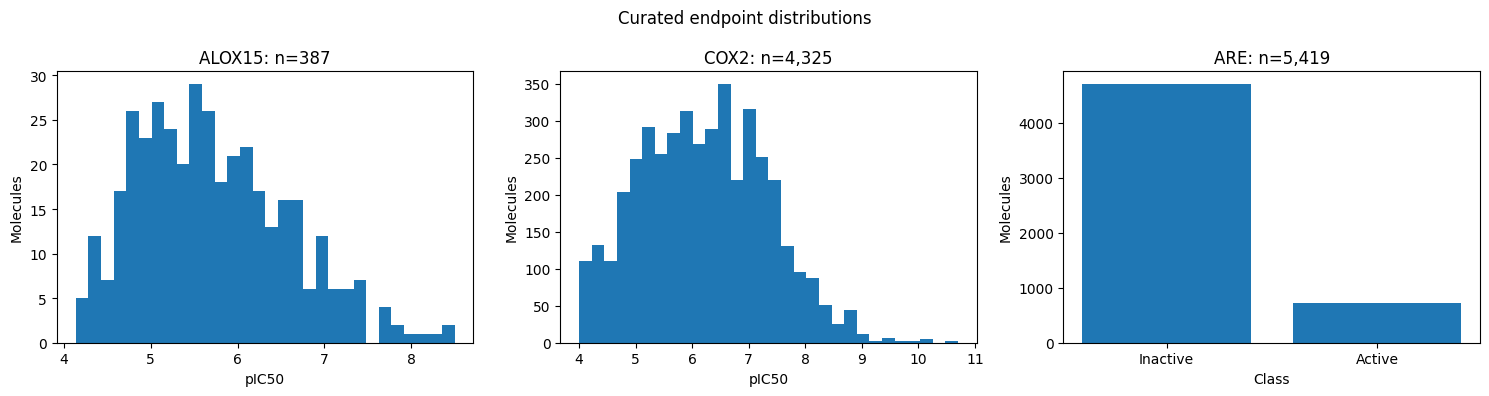

In [ ]:
# Paper Figure: dataset distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, task in zip(axes, ["ALOX15", "COX2", "ARE"]):
    group = curated[curated["task"] == task]
    if group["kind"].iloc[0] == "regression":
        ax.hist(group["label"], bins=30)
        ax.set_xlabel("pIC50")
    else:
        counts = group["label"].value_counts().sort_index()
        ax.bar(["Inactive", "Active"], [counts.get(0, 0), counts.get(1, 0)])
        ax.set_xlabel("Class")
    ax.set_title(f"{task}: n={len(group):,}")
    ax.set_ylabel("Molecules")
fig.suptitle("Curated endpoint distributions")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "figure_dataset_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. One scaffold-disjoint split shared across every model

In [ ]:
def hash_fraction(text: str, seed: int) -> float:
    digest = hashlib.sha256(f"{seed}|{text}".encode()).hexdigest()
    return int(digest[:16], 16) / float(16**16)


def assign_scaffold_split(frame: pd.DataFrame):
    train_frac, val_frac, test_frac = CONFIG.split_fractions
    assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9
    for offset in range(CONFIG.split_seed_search_limit):
        seed = CONFIG.base_seed + offset
        scaffold_to_split = {}
        for scaffold in frame["scaffold"].unique():
            u = hash_fraction(scaffold, seed)
            scaffold_to_split[scaffold] = "train" if u < train_frac else ("val" if u < train_frac + val_frac else "test")
        candidate = frame.copy()
        candidate["split"] = candidate["scaffold"].map(scaffold_to_split)

        valid = True
        for task, group in candidate.groupby("task"):
            sizes = group["split"].value_counts()
            if any(sizes.get(split, 0) < max(3, int(0.04 * len(group))) for split in ("train", "val", "test")):
                valid = False
                break
            if group["kind"].iloc[0] == "classification":
                for split in ("train", "val", "test"):
                    if group.loc[group["split"] == split, "label"].nunique() < 2:
                        valid = False
                        break
        if valid:
            return candidate, seed
    raise RuntimeError("Could not find a valid scaffold split; inspect class/scaffold diversity.")

curated, SPLIT_SEED = assign_scaffold_split(curated)
curated.to_csv(DIRS["processed"] / "curated_endpoints.csv", index=False)
curated[["task", "standard_smiles", "inchikey", "scaffold", "split"]].to_csv(
    DIRS["splits"] / "scaffold_split.csv", index=False
)

# Leakage audit: no scaffold or exact molecule may cross splits.
assert curated.groupby("scaffold")["split"].nunique().max() == 1
assert curated.groupby("standard_smiles")["split"].nunique().max() == 1
split_summary = curated.groupby(["task", "split"]).agg(
    molecules=("standard_smiles", "size"), scaffolds=("scaffold", "nunique"),
    label_mean=("label", "mean")
).reset_index()
split_summary.to_csv(DIRS["tables"] / "split_summary.csv", index=False)
print("Selected scaffold split seed:", SPLIT_SEED)
display(split_summary)

Selected scaffold split seed: 20260717


,task,split,molecules,scaffolds,label_mean
0,ALOX15,test,52,21,5.585148
1,ALOX15,train,294,100,5.753702
2,ALOX15,val,41,22,5.629209
3,ARE,test,1991,442,0.113511
4,ARE,train,2876,2026,0.144993
5,ARE,val,552,411,0.143116
6,COX2,test,772,189,6.193233
7,COX2,train,3021,859,6.227623
8,COX2,val,532,177,6.103951


## 9. ECFP4 classical baselines

In [ ]:
MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=CONFIG.ecfp_radius, fpSize=CONFIG.ecfp_bits)


def ecfp_matrix(smiles_values):
    matrix = np.zeros((len(smiles_values), CONFIG.ecfp_bits), dtype=np.float32)
    valid = np.ones(len(smiles_values), dtype=bool)
    for i, smi in enumerate(smiles_values):
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            valid[i] = False
            continue
        fp = MORGAN.GetFingerprintAsNumPy(mol)
        matrix[i] = fp
    return matrix, valid


def expected_calibration_error(y_true, probabilities, bins=10):
    y_true = np.asarray(y_true)
    probabilities = np.asarray(probabilities)
    edges = np.linspace(0, 1, bins + 1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (probabilities >= lo) & (probabilities < hi if hi < 1 else probabilities <= hi)
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - probabilities[mask].mean())
    return float(ece)


def best_mcc_threshold(y_true, probabilities):
    thresholds = np.linspace(0.05, 0.95, 91)
    scores = [matthews_corrcoef(y_true, probabilities >= t) for t in thresholds]
    return float(thresholds[int(np.argmax(scores))])


def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return {
        "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "R2": float(r2_score(y_true, y_pred)),
        "Pearson_r": float(pearsonr(y_true, y_pred).statistic) if len(y_true) > 2 else np.nan,
        "Spearman_rho": float(spearmanr(y_true, y_pred).statistic) if len(y_true) > 2 else np.nan,
    }


def classification_metrics(y_true, probabilities, threshold=0.5):
    y_true, probabilities = np.asarray(y_true).astype(int), np.asarray(probabilities)
    pred = (probabilities >= threshold).astype(int)
    return {
        "ROC_AUC": float(roc_auc_score(y_true, probabilities)),
        "PR_AUC": float(average_precision_score(y_true, probabilities)),
        "Balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "MCC": float(matthews_corrcoef(y_true, pred)),
        "F1": float(f1_score(y_true, pred)),
        "Brier": float(brier_score_loss(y_true, probabilities)),
        "ECE": expected_calibration_error(y_true, probabilities),
        "threshold": float(threshold),
    }


def bootstrap_ci(y_true, y_pred, kind, metric_name, iterations=None, seed=123):
    iterations = iterations or CONFIG.bootstrap_iterations
    rng = np.random.default_rng(seed)
    values = []
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    for _ in range(iterations):
        idx = rng.integers(0, len(y_true), len(y_true))
        yt, yp = y_true[idx], y_pred[idx]
        if kind == "classification" and len(np.unique(yt)) < 2:
            continue
        metrics = regression_metrics(yt, yp) if kind == "regression" else classification_metrics(yt, yp)
        values.append(metrics[metric_name])
    return tuple(np.percentile(values, [2.5, 97.5])) if values else (np.nan, np.nan)


def fit_classical_baselines(task_frame: pd.DataFrame):
    task = task_frame["task"].iloc[0]
    kind = task_frame["kind"].iloc[0]
    X, valid = ecfp_matrix(task_frame["standard_smiles"].tolist())
    frame = task_frame.loc[valid].reset_index(drop=True)
    X = X[valid]
    indices = {split: np.flatnonzero(frame["split"].values == split) for split in ("train", "val", "test")}
    y = frame["label"].to_numpy(dtype=float)
    results, predictions = [], {}

    if kind == "regression":
        candidates = {
            "ECFP4_RF": RandomForestRegressor(
                n_estimators=20 if CONFIG.run_profile == "smoke" else 600,
                max_features="sqrt", min_samples_leaf=1, n_jobs=CONFIG.graph_jobs, random_state=CONFIG.base_seed,
            ),
            "ECFP4_XGB": xgb.XGBRegressor(
                n_estimators=3 if CONFIG.run_profile == "smoke" else 700,
                max_depth=6, learning_rate=0.04, subsample=0.85, colsample_bytree=0.85,
                reg_lambda=1.0, objective="reg:squarederror", tree_method="hist", n_jobs=CONFIG.graph_jobs, random_state=CONFIG.base_seed,
            ),
        }
    else:
        pos = max(1, int(y[indices["train"]].sum()))
        neg = max(1, len(indices["train"]) - pos)
        candidates = {
            "ECFP4_RF": RandomForestClassifier(
                n_estimators=20 if CONFIG.run_profile == "smoke" else 700,
                max_features="sqrt", class_weight="balanced_subsample", n_jobs=CONFIG.graph_jobs,
                random_state=CONFIG.base_seed,
            ),
            "ECFP4_XGB": xgb.XGBClassifier(
                n_estimators=3 if CONFIG.run_profile == "smoke" else 700,
                max_depth=6, learning_rate=0.04, subsample=0.85, colsample_bytree=0.85,
                reg_lambda=1.0, objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                scale_pos_weight=neg / pos, n_jobs=CONFIG.graph_jobs, random_state=CONFIG.base_seed,
            ),
        }

    for name, model in candidates.items():
        model.fit(X[indices["train"]], y[indices["train"]])
        joblib.dump(model, DIRS["models"] / f"{task}_{name}.joblib")
        if kind == "regression":
            val_pred = model.predict(X[indices["val"]])
            test_pred = model.predict(X[indices["test"]])
            metrics = regression_metrics(y[indices["test"]], test_pred)
            threshold = None
        else:
            val_pred = model.predict_proba(X[indices["val"]])[:, 1]
            threshold = best_mcc_threshold(y[indices["val"]], val_pred)
            test_pred = model.predict_proba(X[indices["test"]])[:, 1]
            metrics = classification_metrics(y[indices["test"]], test_pred, threshold)
        results.append({"task": task, "model": name, "seed": CONFIG.base_seed, **metrics})
        predictions[name] = pd.DataFrame({
            "molecule_id": frame.iloc[indices["test"]]["molecule_id"].values,
            "y_true": y[indices["test"]], "y_pred": test_pred,
            "task": task, "model": name, "seed": CONFIG.base_seed,
            "threshold": np.nan if threshold is None else threshold,
        })
    return pd.DataFrame(results), predictions

baseline_results = []
all_predictions = {}
for task, task_frame in curated.groupby("task"):
    result, preds = fit_classical_baselines(task_frame.reset_index(drop=True))
    baseline_results.append(result)
    for name, pred in preds.items():
        pred.to_csv(DIRS["tables"] / f"predictions_{task}_{name}.csv", index=False)
    all_predictions.update({(task, name): pred for name, pred in preds.items()})
baseline_results = pd.concat(baseline_results, ignore_index=True)
baseline_results.to_csv(DIRS["tables"] / "baseline_metrics.csv", index=False)
display(baseline_results)

,task,model,seed,RMSE,MAE,R2,Pearson_r,Spearman_rho,ROC_AUC,PR_AUC,Balanced_accuracy,MCC,F1,Brier,ECE,threshold
0,ALOX15,ECFP4_RF,20260717,0.819618,0.671043,0.166694,0.427329,0.507461,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ALOX15,ECFP4_XGB,20260717,0.974939,0.835615,-0.179061,0.164261,0.200457,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ARE,ECFP4_RF,20260717,NaN,NaN,NaN,NaN,NaN,0.744181,0.283903,0.679301,0.251130,0.342500,0.103393,0.093970,0.27
3,ARE,ECFP4_XGB,20260717,NaN,NaN,NaN,NaN,NaN,0.718133,0.295215,0.642607,0.224967,0.326984,0.187240,0.259729,0.62
4,COX2,ECFP4_RF,20260717,0.960198,0.753173,0.216883,0.481128,0.455211,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,COX2,ECFP4_XGB,20260717,1.023215,0.819871,0.110720,0.357523,0.333179,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10. 3D conformer generation and graph construction

In [ ]:
HYBRIDIZATION_MAP = {
    Chem.rdchem.HybridizationType.SP: 1,
    Chem.rdchem.HybridizationType.SP2: 2,
    Chem.rdchem.HybridizationType.SP3: 3,
    Chem.rdchem.HybridizationType.SP3D: 4,
    Chem.rdchem.HybridizationType.SP3D2: 5,
}
CHIRALITY_MAP = {
    Chem.rdchem.ChiralType.CHI_UNSPECIFIED: 0,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CW: 1,
    Chem.rdchem.ChiralType.CHI_TETRAHEDRAL_CCW: 2,
    Chem.rdchem.ChiralType.CHI_OTHER: 3,
}
NODE_CARDINALITIES = [119, 8, 11, 7, 5, 6, 2, 2]  # atomic number, degree, charge, hybridization, chirality, H, aromatic, ring
EDGE_DIM = 12


def atom_features(mol):
    try:
        AllChem.ComputeGasteigerCharges(mol)
    except Exception:
        pass
    categorical, continuous = [], []
    for atom in mol.GetAtoms():
        z = min(atom.GetAtomicNum(), 118)
        degree = min(atom.GetTotalDegree(), 7)
        charge = int(np.clip(atom.GetFormalCharge(), -5, 5)) + 5
        hybrid = HYBRIDIZATION_MAP.get(atom.GetHybridization(), 0)
        chirality = CHIRALITY_MAP.get(atom.GetChiralTag(), 4)
        total_h = min(int(atom.GetTotalNumHs(includeNeighbors=True)), 5)
        categorical.append([z, degree, charge, hybrid, chirality, total_h, int(atom.GetIsAromatic()), int(atom.IsInRing())])
        try:
            gasteiger = float(atom.GetProp("_GasteigerCharge"))
            if not np.isfinite(gasteiger): gasteiger = 0.0
        except Exception:
            gasteiger = 0.0
        continuous.append([
            atom.GetMass() / 200.0,
            PERIODIC_TABLE.GetRcovalent(z) / 2.5,
            PERIODIC_TABLE.GetRvdw(z) / 3.0,
            float(np.clip(gasteiger, -3, 3)) / 3.0,
        ])
    return torch.tensor(categorical, dtype=torch.long), torch.tensor(continuous, dtype=torch.float32)


def bond_vector(bond):
    vector = np.zeros(EDGE_DIM, dtype=np.float32)
    bond_types = {
        Chem.rdchem.BondType.SINGLE: 0,
        Chem.rdchem.BondType.DOUBLE: 1,
        Chem.rdchem.BondType.TRIPLE: 2,
        Chem.rdchem.BondType.AROMATIC: 3,
    }
    vector[bond_types.get(bond.GetBondType(), 0)] = 1.0
    vector[4] = float(bond.GetIsConjugated())
    vector[5] = float(bond.IsInRing())
    stereo = bond.GetStereo()
    stereo_index = 6 if stereo == Chem.rdchem.BondStereo.STEREONONE else (
        7 if stereo == Chem.rdchem.BondStereo.STEREOZ else (8 if stereo == Chem.rdchem.BondStereo.STEREOE else 9)
    )
    vector[stereo_index] = 1.0
    vector[10] = 1.0  # covalent flag
    return vector


def build_edges(mol, positions, cutoff, max_neighbors):
    bond_pairs, bond_attrs = [], []
    covalent_set = set()
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        attr = bond_vector(bond)
        for src, dst in ((i, j), (j, i)):
            bond_pairs.append((src, dst)); bond_attrs.append(attr); covalent_set.add((src, dst))
    edge_index_2d = torch.tensor(bond_pairs, dtype=torch.long).t().contiguous()
    edge_attr_2d = torch.tensor(np.asarray(bond_attrs), dtype=torch.float32)

    distances = np.linalg.norm(positions[:, None, :] - positions[None, :, :], axis=-1)
    spatial_pairs, spatial_attrs = [], []
    for dst in range(len(positions)):
        candidates = [src for src in np.argsort(distances[dst]) if src != dst and distances[dst, src] <= cutoff]
        candidates = candidates[:max_neighbors]
        for src in candidates:
            if (src, dst) in covalent_set:
                continue
            attr = np.zeros(EDGE_DIM, dtype=np.float32)
            attr[11] = 1.0  # non-covalent spatial flag
            spatial_pairs.append((src, dst)); spatial_attrs.append(attr)
    all_pairs = bond_pairs + spatial_pairs
    all_attrs = bond_attrs + spatial_attrs
    edge_index_3d = torch.tensor(all_pairs, dtype=torch.long).t().contiguous()
    edge_attr_3d = torch.tensor(np.asarray(all_attrs), dtype=torch.float32)
    return edge_index_2d, edge_attr_2d, edge_index_3d, edge_attr_3d


def generate_graphs(smiles: str, seed: int):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return []
    mol = Chem.AddHs(mol)
    params = AllChem.ETKDGv3()
    params.randomSeed = int(seed % (2**31 - 1))
    params.pruneRmsThresh = CONFIG.conformer_rms_prune_angstrom
    params.useRandomCoords = False
    params.maxIterations = 1000
    try:
        conf_ids = list(AllChem.EmbedMultipleConfs(mol, numConfs=CONFIG.initial_conformers, params=params))
    except Exception:
        conf_ids = []
    if not conf_ids:
        return []

    energies = []
    mmff_props = AllChem.MMFFGetMoleculeProperties(mol, mmffVariant="MMFF94")
    for cid in conf_ids:
        try:
            if mmff_props is not None:
                ff = AllChem.MMFFGetMoleculeForceField(mol, mmff_props, confId=cid)
            else:
                ff = AllChem.UFFGetMoleculeForceField(mol, confId=cid)
            ff.Minimize(maxIts=500)
            energies.append((cid, float(ff.CalcEnergy())))
        except Exception:
            energies.append((cid, np.inf))
    finite = [(cid, energy) for cid, energy in energies if np.isfinite(energy)]
    if not finite:
        return []
    finite.sort(key=lambda x: x[1])
    minimum = finite[0][1]
    retained = [(cid, energy) for cid, energy in finite if energy <= minimum + CONFIG.conformer_energy_window_kcal]
    retained = retained[:CONFIG.retained_conformers]

    x_cat, x_cont = atom_features(mol)
    graphs = []
    for rank, (cid, energy) in enumerate(retained):
        conf = mol.GetConformer(cid)
        positions = np.asarray(conf.GetPositions(), dtype=np.float32)
        e2, a2, e3, a3 = build_edges(
            mol, positions, CONFIG.radius_cutoff_angstrom, CONFIG.max_spatial_neighbors
        )
        graph = Data(
            x_cat=x_cat.clone(), x_cont=x_cont.clone(), pos=torch.tensor(positions),
            edge_index_2d=e2, edge_attr_2d=a2,
            edge_index_3d=e3, edge_attr_3d=a3,
            conformer_rank=torch.tensor([rank]), conformer_energy=torch.tensor([energy], dtype=torch.float32),
            num_nodes=x_cat.size(0),
        )
        graphs.append(graph)
    return graphs


def build_graph_store(frame: pd.DataFrame):
    cache_path = DIRS["processed"] / f"graph_store_{CONFIG.run_profile}.pt"
    if cache_path.exists():
        print("Loading cached graph store:", cache_path)
        return torch.load(cache_path, weights_only=False)
    unique_smiles = sorted(frame["standard_smiles"].unique())
    store, failures = {}, []
    def build_one(smi):
        seed = CONFIG.base_seed + int(hashlib.sha256(smi.encode()).hexdigest()[:8], 16)
        return smi, generate_graphs(smi, seed)
    chunk_size = 256
    for start in tqdm(range(0, len(unique_smiles), chunk_size), desc="Conformer-generation chunks"):
        chunk = unique_smiles[start:start + chunk_size]
        if CONFIG.graph_jobs > 1:
            results = joblib.Parallel(n_jobs=CONFIG.graph_jobs, prefer="threads")(
                joblib.delayed(build_one)(smi) for smi in chunk
            )
        else:
            results = [build_one(smi) for smi in chunk]
        for smi, graphs in results:
            if graphs:
                store[smi] = graphs
            else:
                failures.append(smi)
    torch.save(store, cache_path)
    pd.DataFrame({"failed_standard_smiles": failures}).to_csv(DIRS["logs"] / "conformer_failures.csv", index=False)
    print(f"Graph store: {len(store):,} molecules; failures: {len(failures):,}")
    return store

graph_store = build_graph_store(curated)
curated["graph_available"] = curated["standard_smiles"].isin(graph_store)
conformer_success = curated.groupby("task")["graph_available"].mean().rename("conformer_success_fraction")
print(conformer_success)
if CONFIG.strict_data_validation:
    minimum_success = 0.85 if CONFIG.run_profile != "smoke" else 0.75
    assert conformer_success.min() >= minimum_success, "Excessive conformer-generation failures."
curated = curated[curated["graph_available"]].copy().reset_index(drop=True)
curated.to_csv(DIRS["processed"] / "curated_endpoints_with_graphs.csv", index=False)

Conformer-generation chunks:   0%|          | 0/40 [00:00<?, ?it/s]

[14:45:19] UFFTYPER: Unrecognized charge state for atom: 8
[14:47:11] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:11] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:12] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (21)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (21)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (21)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (21)
[14:47:13] UFFTYPER: Unrecognized atom type: Se2+2 (22)
[14:47:14] UFFTYPER: Unrecognized atom type: 

Graph store: 10,063 molecules; failures: 14
task
ALOX15    1.000000
ARE       0.999262
COX2      0.997688
Name: conformer_success_fraction, dtype: float64


## 11. PyTorch Geometric datasets and atom-budget batching

In [ ]:
def clone_with_labels(graph, row, multitask_vector=None):
    data = graph.clone()
    data.mol_idx = torch.tensor([int(row["molecule_id"])], dtype=torch.long)
    if multitask_vector is None:
        data.y = torch.tensor([float(row["label"])], dtype=torch.float32)
    else:
        values, mask = multitask_vector
        data.y_vec = torch.tensor([values], dtype=torch.float32)
        data.y_mask = torch.tensor([mask], dtype=torch.bool)
    return data


def task_graph_list(task_frame, architecture="3d", first_conformer_only=False):
    output = []
    for _, row in task_frame.iterrows():
        conformers = graph_store.get(row["standard_smiles"], [])
        if architecture == "2d" or first_conformer_only:
            conformers = conformers[:1]
        for graph in conformers:
            output.append(clone_with_labels(graph, row))
    return output


def multitask_graph_list(frame, first_conformer_only=False):
    task_order = ["ALOX15", "COX2", "ARE"]
    output = []
    for smiles, group in frame.groupby("standard_smiles"):
        row = group.iloc[0]
        label_map = dict(zip(group["task"], group["label"]))
        values = [float(label_map.get(task, 0.0)) for task in task_order]
        mask = [task in label_map for task in task_order]
        conformers = graph_store.get(smiles, [])[:1] if first_conformer_only else graph_store.get(smiles, [])
        for graph in conformers:
            output.append(clone_with_labels(graph, row, (values, mask)))
    return output


class AtomBudgetBatchSampler:
    """Deterministic size-bucketed batches whose total atom count does not exceed the budget."""
    def __init__(self, graphs, atom_budget, shuffle, seed):
        self.shuffle = shuffle
        self.seed = seed
        ordered = sorted(range(len(graphs)), key=lambda i: graphs[i].num_nodes)
        self.batches, current, atoms = [], [], 0
        for idx in ordered:
            count = int(graphs[idx].num_nodes)
            if current and atoms + count > atom_budget:
                self.batches.append(current); current, atoms = [], 0
            current.append(idx); atoms += count
        if current: self.batches.append(current)

    def __iter__(self):
        order = list(range(len(self.batches)))
        if self.shuffle:
            random.Random(self.seed + random.randint(0, 10**6)).shuffle(order)
        for i in order:
            yield self.batches[i]

    def __len__(self):
        return len(self.batches)


def make_graph_loader(graphs, shuffle, seed):
    sampler = AtomBudgetBatchSampler(graphs, CONFIG.batch_atom_budget, shuffle, seed)
    return DataLoader(
        graphs, batch_sampler=sampler,
        num_workers=CONFIG.num_workers, pin_memory=torch.cuda.is_available(),
        persistent_workers=CONFIG.num_workers > 0,
    )


def make_loaders(task_frame, architecture="3d", first_conformer_only=False):
    loaders = {}
    for split in ("train", "val", "test"):
        graphs = task_graph_list(task_frame[task_frame["split"] == split], architecture, first_conformer_only)
        loaders[split] = make_graph_loader(graphs, split == "train", CONFIG.base_seed)
        max_atoms = max((sum(graphs[i].num_nodes for i in batch) for batch in loaders[split].batch_sampler.batches), default=0)
        print(task_frame["task"].iloc[0], architecture, split, "graphs", len(graphs),
              "batches", len(loaders[split]), "maximum atoms/batch", max_atoms)
    return loaders

## 12. Neural architectures: 2D MPNN and E(3)-equivariant 3D MPNN

In [ ]:
class AtomEncoder(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        per_feature = max(8, hidden_dim // len(NODE_CARDINALITIES))
        self.embeddings = nn.ModuleList([nn.Embedding(cardinality, per_feature) for cardinality in NODE_CARDINALITIES])
        self.projection = nn.Sequential(
            nn.Linear(per_feature * len(NODE_CARDINALITIES) + 4, hidden_dim),
            nn.SiLU(), nn.LayerNorm(hidden_dim)
        )

    def forward(self, x_cat, x_cont):
        embedded = [emb(x_cat[:, i]) for i, emb in enumerate(self.embeddings)]
        return self.projection(torch.cat(embedded + [x_cont], dim=-1))


class GaussianRBF(nn.Module):
    def __init__(self, n_rbf, cutoff):
        super().__init__()
        centers = torch.linspace(0.0, cutoff, n_rbf)
        self.register_buffer("centers", centers)
        self.gamma = float(n_rbf / cutoff) ** 2
        self.cutoff = cutoff

    def forward(self, distances):
        expanded = torch.exp(-self.gamma * (distances - self.centers) ** 2)
        cutoff_value = 0.5 * (torch.cos(torch.clamp(distances, 0, self.cutoff) * math.pi / self.cutoff) + 1.0)
        cutoff_value = cutoff_value * (distances <= self.cutoff)
        return expanded * cutoff_value


class InvariantReadout(nn.Module):
    def __init__(self, hidden_dim, mode="sum_mean_attention"):
        super().__init__()
        self.mode = mode
        self.gate = nn.Linear(hidden_dim, 1)
        output_dim = hidden_dim if mode == "mean" else hidden_dim * 3 + 1
        self.output_dim = output_dim

    def forward(self, h, batch):
        if self.mode == "mean":
            return global_mean_pool(h, batch)
        summed = global_add_pool(h, batch)
        mean = global_mean_pool(h, batch)
        gate = self.gate(h).squeeze(-1)
        alpha = pyg_softmax(gate, batch)
        attention = global_add_pool(alpha.unsqueeze(-1) * h, batch)
        size = global_add_pool(torch.ones((h.size(0), 1), device=h.device, dtype=h.dtype), batch)
        return torch.cat([summed, mean, attention, torch.log1p(size)], dim=-1)


class MPNN2DLayer(nn.Module):
    def __init__(self, hidden_dim, edge_dim, dropout):
        super().__init__()
        self.message = nn.Sequential(
            nn.Linear(hidden_dim + edge_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU()
        )
        self.update = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, h, edge_index, edge_attr):
        src, dst = edge_index
        messages = self.message(torch.cat([h[src], edge_attr], dim=-1))
        aggregated = torch.zeros_like(h).index_add_(0, dst, messages)
        return self.norm(h + self.update(torch.cat([h, aggregated], dim=-1)))


class MPNN2D(nn.Module):
    def __init__(self, hidden_dim, layers, dropout, readout="sum_mean_attention"):
        super().__init__()
        self.atom_encoder = AtomEncoder(hidden_dim)
        self.layers = nn.ModuleList([MPNN2DLayer(hidden_dim, EDGE_DIM, dropout) for _ in range(layers)])
        self.readout = InvariantReadout(hidden_dim, readout)
        self.head = nn.Sequential(
            nn.Linear(self.readout.output_dim, hidden_dim), nn.SiLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        h = self.atom_encoder(data.x_cat, data.x_cont)
        for layer in self.layers:
            h = layer(h, data.edge_index_2d, data.edge_attr_2d)
        return self.head(self.readout(h, data.batch)).squeeze(-1)


class EGNNLayer(nn.Module):
    def __init__(self, hidden_dim, edge_dim, rbf_dim, cutoff, dropout, coord_scale, update_coords=True):
        super().__init__()
        self.rbf = GaussianRBF(rbf_dim, cutoff)
        self.update_coords = update_coords
        self.coord_scale = coord_scale
        self.message = nn.Sequential(
            nn.Linear(hidden_dim * 2 + edge_dim + rbf_dim, hidden_dim), nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.SiLU()
        )
        self.node_update = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim), nn.SiLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.coord_mlp = nn.Sequential(nn.Linear(hidden_dim, hidden_dim), nn.SiLU(), nn.Linear(hidden_dim, 1))
        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, h, pos, edge_index, edge_attr):
        src, dst = edge_index
        relative = pos[dst] - pos[src]
        distance = torch.sqrt((relative.float() ** 2).sum(dim=-1, keepdim=True) + 1e-9).to(pos.dtype)
        radial = self.rbf(distance)
        messages = self.message(torch.cat([h[dst], h[src], edge_attr, radial], dim=-1))
        aggregated = torch.zeros_like(h).index_add_(0, dst, messages)
        h = self.norm(h + self.node_update(torch.cat([h, aggregated], dim=-1)))

        if self.update_coords:
            weights = torch.tanh(self.coord_mlp(messages)) * self.coord_scale
            contribution = relative * weights / (1.0 + distance)
            delta = torch.zeros_like(pos).index_add_(0, dst, contribution)
            degree = torch.zeros((pos.size(0), 1), device=pos.device, dtype=pos.dtype)
            degree.index_add_(0, dst, torch.ones_like(distance))
            pos = pos + delta / degree.clamp_min(1.0)
        return h, pos


class GeometricEncoder(nn.Module):
    def __init__(self, hidden_dim, layers, rbf_dim, dropout, coord_scale,
                 update_coords=True, covalent_only=False, readout="sum_mean_attention"):
        super().__init__()
        self.atom_encoder = AtomEncoder(hidden_dim)
        self.covalent_only = covalent_only
        self.layers = nn.ModuleList([
            EGNNLayer(hidden_dim, EDGE_DIM, rbf_dim, CONFIG.radius_cutoff_angstrom,
                      dropout, coord_scale / max(1, layers), update_coords)
            for _ in range(layers)
        ])
        self.readout = InvariantReadout(hidden_dim, readout)

    def forward(self, data):
        h = self.atom_encoder(data.x_cat, data.x_cont)
        pos = data.pos
        if self.covalent_only:
            edge_index, edge_attr = data.edge_index_2d, data.edge_attr_2d
        else:
            edge_index, edge_attr = data.edge_index_3d, data.edge_attr_3d
        for layer in self.layers:
            h, pos = layer(h, pos, edge_index, edge_attr)
        return self.readout(h, data.batch)


class GeometricMPNN(nn.Module):
    def __init__(self, hidden_dim, layers, rbf_dim, dropout, coord_scale,
                 update_coords=True, covalent_only=False, readout="sum_mean_attention"):
        super().__init__()
        self.encoder = GeometricEncoder(hidden_dim, layers, rbf_dim, dropout, coord_scale,
                                        update_coords, covalent_only, readout)
        self.head = nn.Sequential(
            nn.Linear(self.encoder.readout.output_dim, hidden_dim), nn.SiLU(),
            nn.Dropout(dropout), nn.Linear(hidden_dim, 1)
        )

    def forward(self, data):
        return self.head(self.encoder(data)).squeeze(-1)


class MultiTaskGeometricMPNN(nn.Module):
    def __init__(self, hidden_dim, layers, rbf_dim, dropout, coord_scale):
        super().__init__()
        self.encoder = GeometricEncoder(hidden_dim, layers, rbf_dim, dropout, coord_scale)
        self.heads = nn.ModuleList([
            nn.Sequential(nn.Linear(self.encoder.readout.output_dim, hidden_dim), nn.SiLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, 1))
            for _ in range(3)
        ])

    def forward(self, data):
        graph_embedding = self.encoder(data)
        return torch.cat([head(graph_embedding) for head in self.heads], dim=1)

## 13. Architecture correctness tests before training

In [ ]:
def random_rotation_matrix(seed=0):
    rng = np.random.default_rng(seed)
    q, _ = np.linalg.qr(rng.normal(size=(3, 3)))
    if np.linalg.det(q) < 0:
        q[:, 0] *= -1
    return torch.tensor(q, dtype=torch.float32)


def architecture_self_tests():
    sample_smiles = next(iter(graph_store))
    graph = graph_store[sample_smiles][0].clone()
    graph.batch = torch.zeros(graph.num_nodes, dtype=torch.long)

    model = GeometricMPNN(
        CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.rbf_dim, CONFIG.dropout,
        CONFIG.coord_scale
    ).eval()
    with torch.no_grad():
        original = model(graph).cpu()
        rotation = random_rotation_matrix(42)
        transformed = graph.clone()
        transformed.pos = graph.pos @ rotation.T + torch.tensor([7.0, -3.0, 2.5])
        transformed.batch = graph.batch.clone()
        transformed_prediction = model(transformed).cpu()
    difference = float(torch.max(torch.abs(original - transformed_prediction)))
    print("Rotation/translation invariance max difference:", difference)
    assert difference < 2e-4, "Geometric invariance test failed."

    model.train()
    prediction = model(graph)
    loss = prediction.square().mean()
    loss.backward()
    gradients = [parameter.grad for parameter in model.parameters() if parameter.grad is not None]
    assert gradients and all(torch.isfinite(g).all() for g in gradients), "Non-finite gradients detected."

    model2d = MPNN2D(CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.dropout)
    p2 = model2d(graph)
    assert p2.shape == torch.Size([1]) and torch.isfinite(p2).all()
    print("Architecture shape and gradient tests passed.")

architecture_self_tests()

Rotation/translation invariance max difference: 0.0
Architecture shape and gradient tests passed.


## 14. Training, molecule-level conformer aggregation, and evaluation

In [ ]:
def autocast_context():
    if DEVICE.type != "cuda":
        return nullcontext()
    dtype = torch.bfloat16 if CONFIG.use_bfloat16 and BF16_AVAILABLE else torch.float16
    return torch.amp.autocast("cuda", dtype=dtype)


def make_optimizer(model):
    kwargs = dict(lr=CONFIG.max_lr / 25.0, weight_decay=CONFIG.weight_decay)
    if DEVICE.type == "cuda":
        try:
            return torch.optim.AdamW(model.parameters(), fused=True, **kwargs)
        except Exception:
            pass
    return torch.optim.AdamW(model.parameters(), **kwargs)


def aggregate_conformer_predictions(records: pd.DataFrame) -> pd.DataFrame:
    return records.groupby("mol_idx", as_index=False).agg(y_true=("y_true", "first"), y_pred=("y_pred", "mean"), conformer_sd=("y_pred", "std")).fillna({"conformer_sd": 0.0})


def predict_loader(model, loader, kind):
    model.eval()
    records = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE, non_blocking=True)
            with autocast_context():
                raw = model(batch)
            pred = torch.sigmoid(raw) if kind == "classification" else raw
            for mol_idx, y_true, y_pred in zip(batch.mol_idx.view(-1), batch.y.view(-1), pred.view(-1)):
                records.append((int(mol_idx), float(y_true), float(y_pred)))
    return aggregate_conformer_predictions(pd.DataFrame(records, columns=["mol_idx", "y_true", "y_pred"]))


def validation_score(kind, y_true, y_pred):
    if kind == "regression":
        return regression_metrics(y_true, y_pred)["RMSE"]
    return -classification_metrics(y_true, y_pred)["PR_AUC"]


def train_single_task_model(model, loaders, kind, task, model_name, seed):
    seed_everything(seed)
    model = model.to(DEVICE)
    if CONFIG.enable_torch_compile and hasattr(torch, "compile"):
        try:
            model = torch.compile(model, dynamic=True, mode="default")
        except Exception as exc:
            print("torch.compile disabled after failure:", exc)
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=CONFIG.max_lr, epochs=CONFIG.epochs,
        steps_per_epoch=max(1, len(loaders["train"])), pct_start=CONFIG.pct_start,
        anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4,
    )
    use_scaler = DEVICE.type == "cuda" and not (CONFIG.use_bfloat16 and BF16_AVAILABLE)
    scaler = torch.amp.GradScaler("cuda", enabled=use_scaler)

    if kind == "classification":
        train_labels = np.array([float(graph.y.item()) for graph in loaders["train"].dataset])
        positives = max(1.0, train_labels.sum())
        negatives = max(1.0, len(train_labels) - positives)
        pos_weight = torch.tensor([negatives / positives], device=DEVICE)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    else:
        criterion = nn.MSELoss()

    best_state, best_score, no_improvement = None, np.inf, 0
    history = []
    for epoch in range(CONFIG.epochs):
        model.train()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        epoch_start = time.perf_counter()
        running_loss, seen, seen_atoms = 0.0, 0, 0
        for batch in loaders["train"]:
            batch = batch.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                output = model(batch)
                loss = criterion(output.view(-1), batch.y.view(-1))
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss in {task}/{model_name}.")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.gradient_clip)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += float(loss.detach()) * batch.num_graphs
            seen += batch.num_graphs
            seen_atoms += int(batch.num_nodes)

        if DEVICE.type == "cuda": torch.cuda.synchronize()
        epoch_seconds = time.perf_counter() - epoch_start
        peak_memory_gb = (torch.cuda.max_memory_allocated() / 1e9) if DEVICE.type == "cuda" else 0.0
        val_records = predict_loader(model, loaders["val"], kind)
        score = validation_score(kind, val_records.y_true, val_records.y_pred)
        history.append({
            "epoch": epoch + 1, "train_loss": running_loss / max(1, seen),
            "validation_score": score, "learning_rate": optimizer.param_groups[0]["lr"],
            "epoch_seconds": epoch_seconds,
            "graphs_per_second": seen / max(epoch_seconds, 1e-9),
            "atoms_per_second": seen_atoms / max(epoch_seconds, 1e-9),
            "peak_allocated_memory_gb": peak_memory_gb,
        })
        if score < best_score - 1e-6:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            no_improvement = 0
        else:
            no_improvement += 1
        if epoch >= max(2, int(0.4 * CONFIG.epochs)) and no_improvement >= CONFIG.patience:
            break

    model.load_state_dict(best_state)
    checkpoint = DIRS["models"] / f"{task}_{model_name}_seed{seed}.pt"
    torch.save({"state_dict": best_state, "config": asdict(CONFIG), "task": task, "kind": kind}, checkpoint)
    history_frame = pd.DataFrame(history)
    history_frame.to_csv(DIRS["logs"] / f"history_{task}_{model_name}_seed{seed}.csv", index=False)

    val_records = predict_loader(model, loaders["val"], kind)
    test_records = predict_loader(model, loaders["test"], kind)
    if kind == "classification":
        threshold = best_mcc_threshold(val_records.y_true, val_records.y_pred)
        metrics = classification_metrics(test_records.y_true, test_records.y_pred, threshold)
    else:
        threshold = None
        metrics = regression_metrics(test_records.y_true, test_records.y_pred)
    test_records["task"] = task
    test_records["model"] = model_name
    test_records["seed"] = seed
    test_records["threshold"] = np.nan if threshold is None else threshold
    test_records.to_csv(DIRS["tables"] / f"predictions_{task}_{model_name}_seed{seed}.csv", index=False)
    return model, {"task": task, "model": model_name, "seed": seed, **metrics}, test_records, history_frame

In [ ]:
# ============================================================
# A100 BF16 / FP32 INDEX_ADD PATCH
# Run this once, then rerun the failed neural-training cell.
# ============================================================

import gc
import torch


def scatter_sum_fp32(
    source: torch.Tensor,
    index: torch.Tensor,
    dim_size: int,
) -> torch.Tensor:
    """
    Stable scatter sum for BF16 AMP.

    Matrix multiplications remain BF16 under autocast, while irregular
    graph aggregation is accumulated in FP32 for compatibility and
    numerical stability.
    """
    output_shape = (int(dim_size),) + tuple(source.shape[1:])

    output = torch.zeros(
        output_shape,
        device=source.device,
        dtype=torch.float32,
    )

    output.index_add_(
        0,
        index,
        source.float(),
    )

    return output


def patched_mpnn2d_forward(
    self,
    h,
    edge_index,
    edge_attr,
):
    src, dst = edge_index

    messages = self.message(
        torch.cat(
            [
                h[src],
                edge_attr,
            ],
            dim=-1,
        )
    )

    # BF16 messages are accumulated safely in FP32.
    aggregated = scatter_sum_fp32(
        messages,
        dst,
        h.size(0),
    )

    node_delta = self.update(
        torch.cat(
            [
                h.float(),
                aggregated,
            ],
            dim=-1,
        )
    )

    return self.norm(
        h.float() + node_delta.float()
    )


def patched_egnn_forward(
    self,
    h,
    pos,
    edge_index,
    edge_attr,
):
    src, dst = edge_index

    # Keep coordinate calculations and distances in FP32.
    relative = (
        pos[dst].float()
        - pos[src].float()
    )

    distance = torch.sqrt(
        (relative**2).sum(
            dim=-1,
            keepdim=True,
        )
        + 1e-9
    )

    radial = self.rbf(distance)

    message_input = torch.cat(
        [
            h[dst].float(),
            h[src].float(),
            edge_attr.float(),
            radial.float(),
        ],
        dim=-1,
    )

    # Linear layers still use BF16 Tensor Cores inside autocast.
    messages = self.message(message_input)

    aggregated = scatter_sum_fp32(
        messages,
        dst,
        h.size(0),
    )

    node_delta = self.node_update(
        torch.cat(
            [
                h.float(),
                aggregated,
            ],
            dim=-1,
        )
    )

    h = self.norm(
        h.float() + node_delta.float()
    )

    if self.update_coords:
        weights = (
            torch.tanh(
                self.coord_mlp(messages)
            ).float()
            * self.coord_scale
        )

        contribution = (
            relative
            * weights
            / (1.0 + distance)
        )

        delta = scatter_sum_fp32(
            contribution,
            dst,
            pos.size(0),
        )

        degree = torch.zeros(
            (pos.size(0), 1),
            device=pos.device,
            dtype=torch.float32,
        )

        degree.index_add_(
            0,
            dst,
            torch.ones(
                (dst.numel(), 1),
                device=pos.device,
                dtype=torch.float32,
            ),
        )

        pos = (
            pos.float()
            + delta / degree.clamp_min(1.0)
        )

    return h, pos


# Replace the affected methods in the existing runtime.
MPNN2DLayer.forward = patched_mpnn2d_forward
EGNNLayer.forward = patched_egnn_forward

# Directly test the exact BF16-to-FP32 aggregation combination.
_test_messages = torch.randn(
    6,
    CONFIG.hidden_dim,
    device=DEVICE,
    dtype=torch.bfloat16,
)

_test_indices = torch.tensor(
    [0, 1, 0, 2, 1, 2],
    device=DEVICE,
    dtype=torch.long,
)

_test_output = scatter_sum_fp32(
    _test_messages,
    _test_indices,
    3,
)

assert _test_output.dtype == torch.float32
assert torch.isfinite(_test_output).all()

# Release objects left behind by the failed training attempt.
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("✅ A100 BF16 aggregation patch applied successfully.")
print("Now rerun the failed neural-model training cell.")

✅ A100 BF16 aggregation patch applied successfully.
Now rerun the failed neural-model training cell.


## 15. Train 2D and full 3D models across all endpoints

In [ ]:
neural_metrics = []
neural_predictions = {}
trained_models = defaultdict(list)

for task, task_frame in curated.groupby("task"):
    task_frame = task_frame.reset_index(drop=True)
    kind = task_frame["kind"].iloc[0]
    for architecture in ("2d", "3d"):
        loaders = make_loaders(task_frame, architecture=architecture)
        for seed in CONFIG.seeds:
            seed_everything(seed)  # seed before parameter initialization
            if architecture == "2d":
                model = MPNN2D(CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.dropout)
                name = "MPNN_2D"
            else:
                model = GeometricMPNN(
                    CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.rbf_dim,
                    CONFIG.dropout, CONFIG.coord_scale
                )
                name = "EGNN_3D_multiconformer"
            trained, metrics, predictions, history = train_single_task_model(
                model, loaders, kind, task, name, seed
            )
            neural_metrics.append(metrics)
            neural_predictions[(task, name, seed)] = predictions
            trained_models[(task, name)].append(trained.cpu())
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

neural_metrics = pd.DataFrame(neural_metrics)
neural_metrics.to_csv(DIRS["tables"] / "neural_metrics_seed_level.csv", index=False)
display(neural_metrics)

ALOX15 2d train graphs 294 batches 1 maximum atoms/batch 11693
ALOX15 2d val graphs 41 batches 1 maximum atoms/batch 2139
ALOX15 2d test graphs 52 batches 1 maximum atoms/batch 1779
ALOX15 3d train graphs 784 batches 3 maximum atoms/batch 16000
ALOX15 3d val graphs 105 batches 1 maximum atoms/batch 5810
ALOX15 3d test graphs 130 batches 1 maximum atoms/batch 4617
ARE 2d train graphs 2873 batches 7 maximum atoms/batch 15991
ARE 2d val graphs 552 batches 2 maximum atoms/batch 16000
ARE 2d test graphs 1990 batches 4 maximum atoms/batch 15996
ARE 3d train graphs 7110 batches 17 maximum atoms/batch 16000
ARE 3d val graphs 1363 batches 4 maximum atoms/batch 15988
ARE 3d test graphs 4197 batches 9 maximum atoms/batch 15994
COX2 2d train graphs 3014 batches 9 maximum atoms/batch 15989
COX2 2d val graphs 530 batches 2 maximum atoms/batch 15975
COX2 2d test graphs 771 batches 3 maximum atoms/batch 15963
COX2 3d train graphs 8575 batches 25 maximum atoms/batch 15997
COX2 3d val graphs 1505 batche

,task,model,seed,RMSE,MAE,R2,Pearson_r,Spearman_rho,ROC_AUC,PR_AUC,Balanced_accuracy,MCC,F1,Brier,ECE,threshold
0,ALOX15,MPNN_2D,13,1.199701,0.894545,-0.785366,0.080459,-0.000706,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ALOX15,MPNN_2D,37,1.118307,0.915880,-0.551326,0.219202,0.215122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ALOX15,MPNN_2D,73,1.171478,0.837114,-0.702353,0.057537,0.005406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ALOX15,MPNN_2D,101,0.840848,0.718833,0.122966,0.402246,0.450228,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ALOX15,MPNN_2D,151,1.071736,0.737621,-0.424810,0.350718,0.396808,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,ALOX15,EGNN_3D_multiconformer,13,0.819073,0.693145,0.167802,0.450795,0.483207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,ALOX15,EGNN_3D_multiconformer,37,0.849873,0.718125,0.104038,0.363736,0.444079,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ALOX15,EGNN_3D_multiconformer,73,1.247905,1.121713,-0.931720,0.215270,0.156856,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,ALOX15,EGNN_3D_multiconformer,101,0.876263,0.750844,0.047532,0.294439,0.424027,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,ALOX15,EGNN_3D_multiconformer,151,0.888873,0.792310,0.019922,0.382727,0.334679,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 16. Multi-task shared-encoder experiment

In [ ]:
def make_multitask_loaders(frame):
    loaders = {}
    for split in ("train", "val", "test"):
        graphs = multitask_graph_list(frame[frame["split"] == split])
        loaders[split] = make_graph_loader(graphs, split == "train", CONFIG.base_seed)
    return loaders


def multitask_loss(outputs, y, mask, are_pos_weight):
    losses = []
    for task_idx in (0, 1):
        valid = mask[:, task_idx]
        if valid.any():
            losses.append(F.mse_loss(outputs[valid, task_idx], y[valid, task_idx]))
    valid = mask[:, 2]
    if valid.any():
        losses.append(F.binary_cross_entropy_with_logits(
            outputs[valid, 2], y[valid, 2], pos_weight=are_pos_weight
        ))
    if not losses:
        return outputs.sum() * 0
    return torch.stack(losses).mean()


def predict_multitask(model, loader):
    model.eval(); rows = []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(DEVICE)
            with autocast_context(): outputs = model(batch)
            outputs = outputs.float()
            outputs[:, 2] = torch.sigmoid(outputs[:, 2])
            for b in range(outputs.size(0)):
                mol = int(batch.mol_idx[b])
                for task_idx, task in enumerate(["ALOX15", "COX2", "ARE"]):
                    if bool(batch.y_mask[b, task_idx]):
                        rows.append((mol, task, float(batch.y_vec[b, task_idx]), float(outputs[b, task_idx])))
    frame = pd.DataFrame(rows, columns=["mol_idx", "task", "y_true", "y_pred"])
    return frame.groupby(["mol_idx", "task"], as_index=False).agg(
        y_true=("y_true", "first"), y_pred=("y_pred", "mean"), conformer_sd=("y_pred", "std")
    ).fillna({"conformer_sd": 0.0})


def multitask_validation_score(records):
    scores = []
    for task, group in records.groupby("task"):
        if task == "ARE":
            scores.append(1.0 - classification_metrics(group.y_true, group.y_pred)["PR_AUC"])
        else:
            scale = max(1e-6, curated.loc[curated.task == task, "label"].std())
            scores.append(regression_metrics(group.y_true, group.y_pred)["RMSE"] / scale)
    return float(np.mean(scores))


def train_multitask(seed):
    seed_everything(seed)  # seed before parameter initialization
    loaders = make_multitask_loaders(curated)
    model = MultiTaskGeometricMPNN(
        CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.rbf_dim, CONFIG.dropout, CONFIG.coord_scale
    ).to(DEVICE)
    optimizer = make_optimizer(model)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=CONFIG.max_lr, epochs=CONFIG.epochs,
        steps_per_epoch=max(1, len(loaders["train"])), pct_start=CONFIG.pct_start,
        anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4,
    )
    train_are = curated[(curated.task == "ARE") & (curated.split == "train")].label
    pos_weight = torch.tensor([(len(train_are) - train_are.sum()) / max(1, train_are.sum())], device=DEVICE)
    best_state, best_score = None, np.inf
    history = []
    for epoch in range(CONFIG.epochs):
        model.train(); total, seen = 0.0, 0
        for batch in loaders["train"]:
            batch = batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                output = model(batch)
                loss = multitask_loss(output, batch.y_vec, batch.y_mask, pos_weight)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CONFIG.gradient_clip)
            optimizer.step(); scheduler.step()
            total += float(loss.detach()) * batch.num_graphs; seen += batch.num_graphs
        val = predict_multitask(model, loaders["val"])
        score = multitask_validation_score(val)
        history.append({"epoch": epoch + 1, "train_loss": total / max(1, seen), "validation_score": score})
        if score < best_score:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    torch.save({"state_dict": best_state, "config": asdict(CONFIG)}, DIRS["models"] / f"MULTITASK_EGNN_seed{seed}.pt")
    test = predict_multitask(model, loaders["test"])
    rows = []
    for task, group in test.groupby("task"):
        if task == "ARE":
            val_group = predict_multitask(model, loaders["val"])
            val_group = val_group[val_group.task == "ARE"]
            threshold = best_mcc_threshold(val_group.y_true, val_group.y_pred)
            metrics = classification_metrics(group.y_true, group.y_pred, threshold)
        else:
            metrics = regression_metrics(group.y_true, group.y_pred)
        rows.append({"task": task, "model": "EGNN_3D_multitask", "seed": seed, **metrics})
    test["model"] = "EGNN_3D_multitask"; test["seed"] = seed
    test.to_csv(DIRS["tables"] / f"predictions_multitask_seed{seed}.csv", index=False)
    pd.DataFrame(history).to_csv(DIRS["logs"] / f"history_multitask_seed{seed}.csv", index=False)
    return model.cpu(), rows, test

multitask_models = []
if CONFIG.run_multitask:
    for seed in CONFIG.seeds:
        model, rows, test = train_multitask(seed)
        multitask_models.append(model)
        neural_metrics = pd.concat([neural_metrics, pd.DataFrame(rows)], ignore_index=True)
        if DEVICE.type == "cuda": torch.cuda.empty_cache()
neural_metrics.to_csv(DIRS["tables"] / "neural_metrics_seed_level.csv", index=False)

## 17. Key ablation experiments

In [ ]:
ABLATIONS = {
    "EGNN_distance_only": {"update_coords": False, "covalent_only": False, "readout": "sum_mean_attention", "single": False},
    "EGNN_covalent_only": {"update_coords": True, "covalent_only": True, "readout": "sum_mean_attention", "single": False},
    "EGNN_single_conformer": {"update_coords": True, "covalent_only": False, "readout": "sum_mean_attention", "single": True},
    "EGNN_mean_pool": {"update_coords": True, "covalent_only": False, "readout": "mean", "single": False},
}
if CONFIG.run_profile == "smoke":
    ABLATIONS = {"EGNN_distance_only": ABLATIONS["EGNN_distance_only"]}
ablation_rows = []
if CONFIG.run_ablations:
    # One preregistered seed per ablation limits compute while preserving a controlled comparison.
    ablation_seed = CONFIG.seeds[0]
    for task, task_frame in curated.groupby("task"):
        kind = task_frame["kind"].iloc[0]
        for name, settings in ABLATIONS.items():
            seed_everything(ablation_seed)  # controlled initialization for paired ablations
            loaders = make_loaders(task_frame, architecture="3d", first_conformer_only=settings["single"])
            model = GeometricMPNN(
                CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.rbf_dim, CONFIG.dropout, CONFIG.coord_scale,
                update_coords=settings["update_coords"], covalent_only=settings["covalent_only"],
                readout=settings["readout"],
            )
            _, metrics, _, _ = train_single_task_model(model, loaders, kind, task, name, ablation_seed)
            ablation_rows.append(metrics)
            if DEVICE.type == "cuda": torch.cuda.empty_cache()
ablation_results = pd.DataFrame(ablation_rows)
ablation_results.to_csv(DIRS["tables"] / "ablation_metrics.csv", index=False)
display(ablation_results)

ALOX15 3d train graphs 784 batches 3 maximum atoms/batch 16000
ALOX15 3d val graphs 105 batches 1 maximum atoms/batch 5810
ALOX15 3d test graphs 130 batches 1 maximum atoms/batch 4617
ALOX15 3d train graphs 784 batches 3 maximum atoms/batch 16000
ALOX15 3d val graphs 105 batches 1 maximum atoms/batch 5810
ALOX15 3d test graphs 130 batches 1 maximum atoms/batch 4617
ALOX15 3d train graphs 294 batches 1 maximum atoms/batch 11693
ALOX15 3d val graphs 41 batches 1 maximum atoms/batch 2139
ALOX15 3d test graphs 52 batches 1 maximum atoms/batch 1779
ALOX15 3d train graphs 784 batches 3 maximum atoms/batch 16000
ALOX15 3d val graphs 105 batches 1 maximum atoms/batch 5810
ALOX15 3d test graphs 130 batches 1 maximum atoms/batch 4617
ARE 3d train graphs 7110 batches 17 maximum atoms/batch 16000
ARE 3d val graphs 1363 batches 4 maximum atoms/batch 15988
ARE 3d test graphs 4197 batches 9 maximum atoms/batch 15994
ARE 3d train graphs 7110 batches 17 maximum atoms/batch 16000
ARE 3d val graphs 1363 

,task,model,seed,RMSE,MAE,R2,Pearson_r,Spearman_rho,ROC_AUC,PR_AUC,Balanced_accuracy,MCC,F1,Brier,ECE,threshold
0,ALOX15,EGNN_distance_only,13,0.877913,0.748640,0.043941,0.358633,0.207556,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ALOX15,EGNN_covalent_only,13,1.096535,0.934379,-0.491511,-0.161917,-0.069913,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ALOX15,EGNN_single_conformer,13,1.520798,1.276855,-1.868960,0.427327,0.448392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,ALOX15,EGNN_mean_pool,13,0.888835,0.738886,0.020006,0.187209,0.134054,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ARE,EGNN_distance_only,13,NaN,NaN,NaN,NaN,NaN,0.629536,0.200880,0.606461,0.195462,0.294821,0.471209,0.610511,0.82
5,ARE,EGNN_covalent_only,13,NaN,NaN,NaN,NaN,NaN,0.684854,0.234318,0.508456,0.050202,0.048193,0.330091,0.484277,0.81
6,ARE,EGNN_single_conformer,13,NaN,NaN,NaN,NaN,NaN,0.682596,0.226807,0.588975,0.193038,0.275362,0.231717,0.365900,0.52
7,ARE,EGNN_mean_pool,13,NaN,NaN,NaN,NaN,NaN,0.665148,0.192887,0.633115,0.169652,0.276106,0.255963,0.392316,0.53
8,COX2,EGNN_distance_only,13,1.057317,0.864942,0.050455,0.228054,0.203700,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,COX2,EGNN_covalent_only,13,1.047117,0.811131,0.068687,0.316338,0.327931,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 18. Aggregate seeds, bootstrap confidence intervals, and paper figures

,task,model,primary_metric,mean,std,n_seeds,minimum,maximum
0,ALOX15,ECFP4_RF,RMSE,0.819618,0.000000,1,0.819618,0.819618
3,ALOX15,EGNN_3D_multitask,RMSE,0.904672,0.013217,5,0.892188,0.920426
2,ALOX15,EGNN_3D_multiconformer,RMSE,0.936397,0.176184,5,0.819073,1.247905
1,ALOX15,ECFP4_XGB,RMSE,0.974939,0.000000,1,0.974939,0.974939
4,ALOX15,MPNN_2D,RMSE,1.080414,0.142675,5,0.840848,1.199701
8,ARE,EGNN_3D_multitask,PR_AUC,0.173463,0.057638,5,0.130865,0.242667
7,ARE,EGNN_3D_multiconformer,PR_AUC,0.233488,0.018953,5,0.203484,0.250486
9,ARE,MPNN_2D,PR_AUC,0.282703,0.047991,5,0.226432,0.352087
5,ARE,ECFP4_RF,PR_AUC,0.283903,0.000000,1,0.283903,0.283903
6,ARE,ECFP4_XGB,PR_AUC,0.295215,0.000000,1,0.295215,0.295215


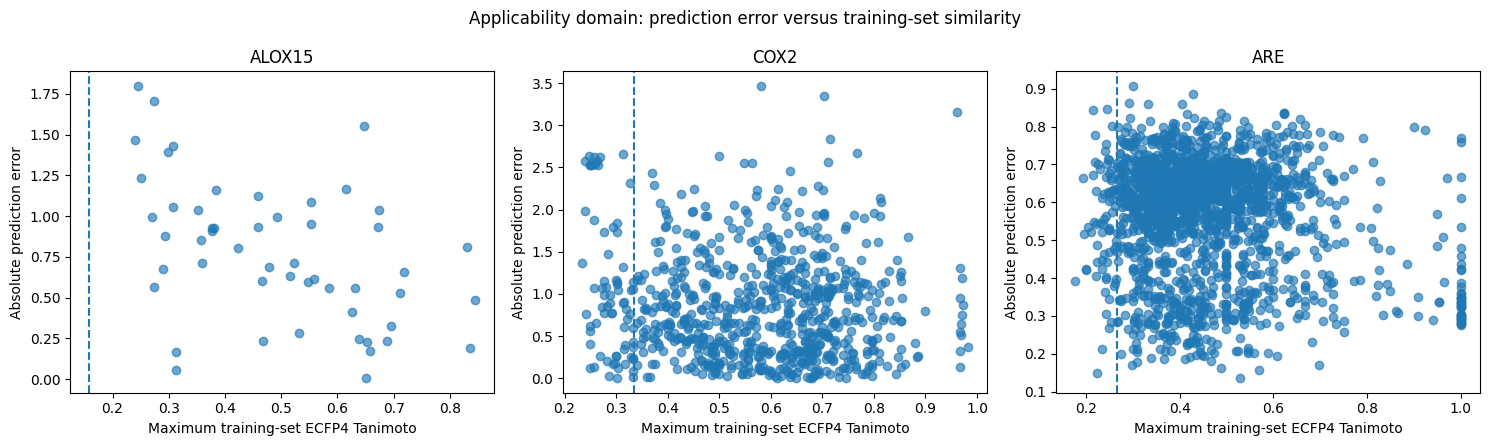

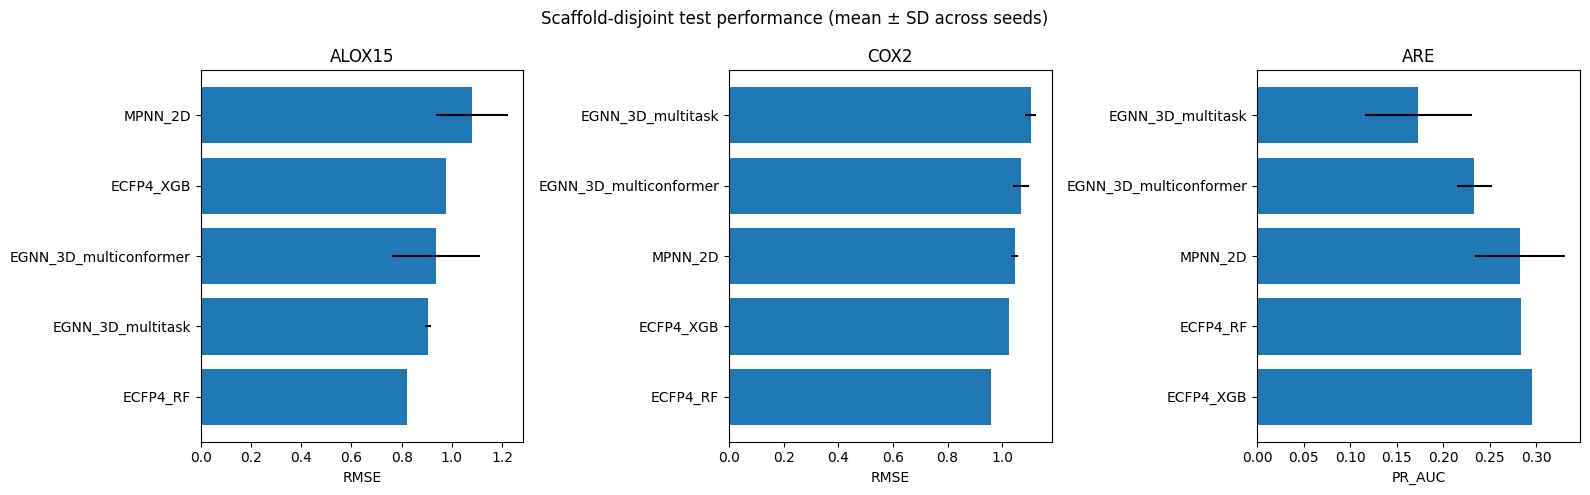

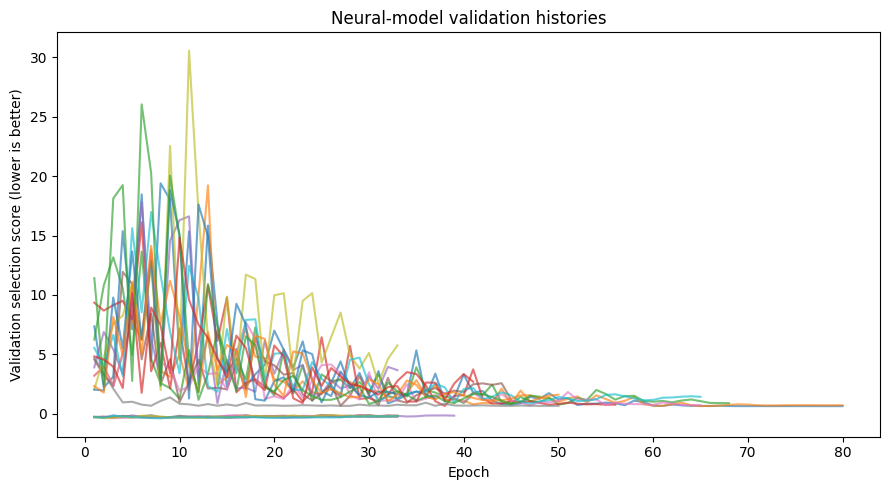

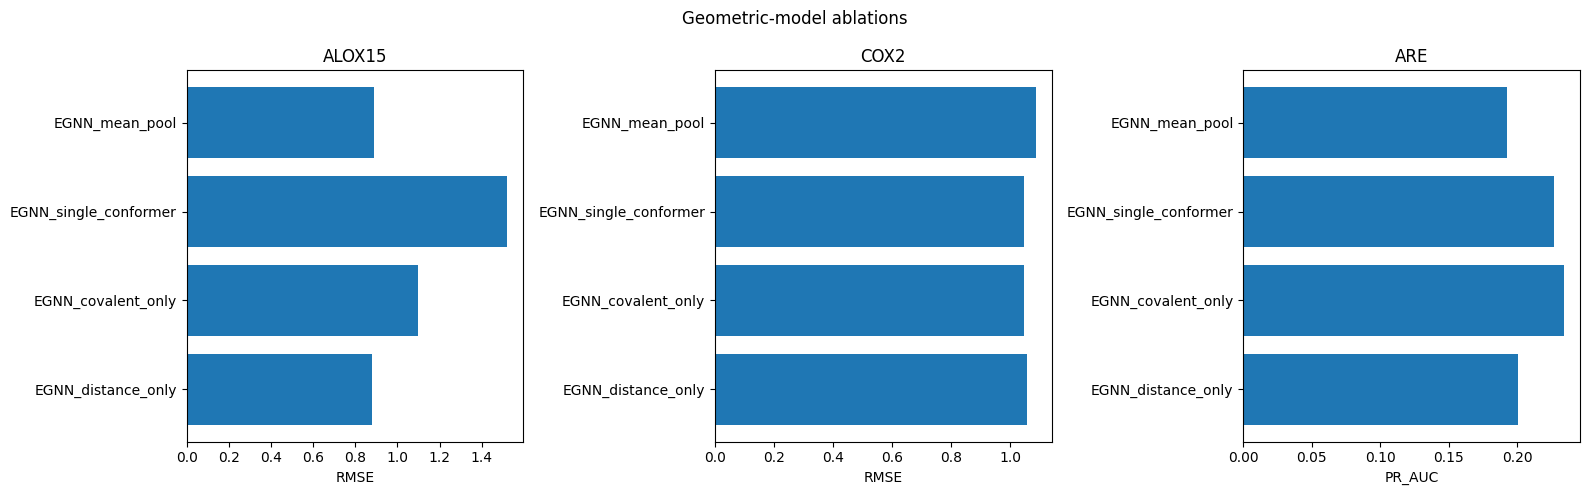

In [ ]:
all_metric_rows = pd.concat([baseline_results, neural_metrics], ignore_index=True, sort=False)
all_metric_rows.to_csv(DIRS["tables"] / "all_metrics_seed_level.csv", index=False)

metric_for_task = {"ALOX15": "RMSE", "COX2": "RMSE", "ARE": "PR_AUC"}
aggregate_rows = []
for (task, model), group in all_metric_rows.groupby(["task", "model"]):
    metric = metric_for_task[task]
    values = group[metric].dropna().to_numpy()
    aggregate_rows.append({
        "task": task, "model": model, "primary_metric": metric,
        "mean": values.mean(), "std": values.std(ddof=1) if len(values) > 1 else 0.0,
        "n_seeds": len(values), "minimum": values.min(), "maximum": values.max(),
    })
aggregate_metrics = pd.DataFrame(aggregate_rows)
aggregate_metrics.to_csv(DIRS["tables"] / "aggregate_metrics.csv", index=False)
display(aggregate_metrics.sort_values(["task", "mean"]))

# Ensemble predictions, bootstrap confidence intervals, paired model comparisons, and applicability domain.
prediction_frames = []
for (task, model_name), frame in all_predictions.items():
    temp = frame.rename(columns={"molecule_id": "mol_idx"}).copy()
    prediction_frames.append(temp[["mol_idx", "y_true", "y_pred", "task", "model", "seed"]])
for (_, _, _), frame in neural_predictions.items():
    prediction_frames.append(frame[["mol_idx", "y_true", "y_pred", "task", "model", "seed"]])
for path in DIRS["tables"].glob("predictions_multitask_seed*.csv"):
    temp = pd.read_csv(path)
    prediction_frames.append(temp[["mol_idx", "y_true", "y_pred", "task", "model", "seed"]])
prediction_pool = pd.concat(prediction_frames, ignore_index=True)
ensemble_predictions = prediction_pool.groupby(["task", "model", "mol_idx"], as_index=False).agg(
    y_true=("y_true", "first"), y_pred=("y_pred", "mean"), model_sd=("y_pred", "std")
).fillna({"model_sd": 0.0})
ensemble_predictions.to_csv(DIRS["tables"] / "ensemble_test_predictions.csv", index=False)

bootstrap_rows = []
for (task, model_name), group in ensemble_predictions.groupby(["task", "model"]):
    kind = "classification" if task == "ARE" else "regression"
    metric = metric_for_task[task]
    point = (classification_metrics(group.y_true, group.y_pred)[metric] if kind == "classification"
             else regression_metrics(group.y_true, group.y_pred)[metric])
    lo, hi = bootstrap_ci(group.y_true, group.y_pred, kind, metric)
    bootstrap_rows.append({"task": task, "model": model_name, "metric": metric,
                           "point_estimate": point, "ci_2_5": lo, "ci_97_5": hi})
bootstrap_metrics = pd.DataFrame(bootstrap_rows)
bootstrap_metrics.to_csv(DIRS["tables"] / "bootstrap_primary_metrics.csv", index=False)


def paired_bootstrap_improvement(reference, proposed, task, iterations, seed=2026):
    merged = reference.merge(proposed, on="mol_idx", suffixes=("_ref", "_prop"))
    rng = np.random.default_rng(seed); differences = []
    for _ in range(iterations):
        sample = merged.iloc[rng.integers(0, len(merged), len(merged))]
        if task == "ARE":
            if sample.y_true_ref.nunique() < 2: continue
            ref = average_precision_score(sample.y_true_ref, sample.y_pred_ref)
            prop = average_precision_score(sample.y_true_prop, sample.y_pred_prop)
            differences.append(prop - ref)  # positive favors proposed
        else:
            ref = mean_squared_error(sample.y_true_ref, sample.y_pred_ref) ** 0.5
            prop = mean_squared_error(sample.y_true_prop, sample.y_pred_prop) ** 0.5
            differences.append(ref - prop)  # positive favors proposed
    return float(np.mean(differences)), *np.percentile(differences, [2.5, 97.5])

comparison_rows = []
for task in ["ALOX15", "COX2", "ARE"]:
    ref = ensemble_predictions[(ensemble_predictions.task == task) & (ensemble_predictions.model == "ECFP4_RF")]
    prop = ensemble_predictions[(ensemble_predictions.task == task) & (ensemble_predictions.model == "EGNN_3D_multiconformer")]
    if len(ref) and len(prop):
        mean_delta, lo, hi = paired_bootstrap_improvement(ref, prop, task, CONFIG.bootstrap_iterations)
        comparison_rows.append({"task": task, "reference": "ECFP4_RF", "proposed": "EGNN_3D_multiconformer",
                                "improvement_definition": "positive favors proposed", "mean_improvement": mean_delta,
                                "ci_2_5": lo, "ci_97_5": hi})
paired_comparisons = pd.DataFrame(comparison_rows)
paired_comparisons.to_csv(DIRS["tables"] / "paired_bootstrap_comparisons.csv", index=False)

# Fingerprint-similarity applicability domain determined from the validation distribution.
def rdkit_fp(smiles):
    mol = Chem.MolFromSmiles(smiles)
    return MORGAN.GetFingerprint(mol) if mol is not None else None

ad_thresholds, nearest_similarity = {}, {}
for task in ["ALOX15", "COX2", "ARE"]:
    train_rows = curated[(curated.task == task) & (curated.split == "train")]
    val_rows = curated[(curated.task == task) & (curated.split == "val")]
    train_fps = [rdkit_fp(s) for s in train_rows.standard_smiles]
    train_fps = [fp for fp in train_fps if fp is not None]
    val_sims = []
    for smi in val_rows.standard_smiles:
        fp = rdkit_fp(smi)
        val_sims.append(max(DataStructs.BulkTanimotoSimilarity(fp, train_fps)) if fp is not None and train_fps else 0.0)
    ad_thresholds[task] = float(np.quantile(val_sims, 0.05)) if val_sims else 0.0
    task_test = curated[(curated.task == task) & (curated.split == "test")].set_index("molecule_id")
    for mol_idx, row in task_test.iterrows():
        fp = rdkit_fp(row.standard_smiles)
        nearest_similarity[(task, int(mol_idx))] = max(DataStructs.BulkTanimotoSimilarity(fp, train_fps)) if fp is not None and train_fps else 0.0
save_json(ad_thresholds, DIRS["tables"] / "applicability_domain_thresholds.json")
ensemble_predictions["nearest_train_tanimoto"] = [nearest_similarity.get((r.task, int(r.mol_idx)), np.nan) for r in ensemble_predictions.itertuples()]
ensemble_predictions["inside_similarity_domain"] = [
    bool(sim >= ad_thresholds.get(task, 0.0)) if np.isfinite(sim) else False
    for task, sim in zip(ensemble_predictions.task, ensemble_predictions.nearest_train_tanimoto)
]
ensemble_predictions.to_csv(DIRS["tables"] / "ensemble_test_predictions.csv", index=False)

uncertainty_rows = []
for (task, model_name), group in ensemble_predictions.groupby(["task", "model"]):
    if model_name not in {"EGNN_3D_multiconformer", "EGNN_3D_multitask"}: continue
    absolute_error = np.abs(group.y_true - group.y_pred)
    rho_unc = spearmanr(absolute_error, group.model_sd).statistic if group.model_sd.nunique() > 1 else np.nan
    rho_sim = spearmanr(absolute_error, group.nearest_train_tanimoto, nan_policy="omit").statistic
    uncertainty_rows.append({"task": task, "model": model_name,
                             "spearman_error_vs_model_sd": rho_unc,
                             "spearman_error_vs_similarity": rho_sim})
uncertainty_diagnostics = pd.DataFrame(uncertainty_rows)
uncertainty_diagnostics.to_csv(DIRS["tables"] / "uncertainty_diagnostics.csv", index=False)

# Applicability-domain figure for the proposed single-task 3D model.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, task in zip(axes, ["ALOX15", "COX2", "ARE"]):
    subset = ensemble_predictions[(ensemble_predictions.task == task) & (ensemble_predictions.model == "EGNN_3D_multiconformer")]
    error = np.abs(subset.y_true - subset.y_pred)
    ax.scatter(subset.nearest_train_tanimoto, error, alpha=0.65)
    ax.axvline(ad_thresholds[task], linestyle="--")
    ax.set_xlabel("Maximum training-set ECFP4 Tanimoto")
    ax.set_ylabel("Absolute prediction error")
    ax.set_title(task)
fig.suptitle("Applicability domain: prediction error versus training-set similarity")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "figure_applicability_domain.png", dpi=300, bbox_inches="tight")
plt.show()

# Main benchmark figure
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, task in zip(axes, ["ALOX15", "COX2", "ARE"]):
    subset = aggregate_metrics[aggregate_metrics.task == task].copy()
    if task != "ARE":
        subset = subset.sort_values("mean", ascending=True)
    else:
        subset = subset.sort_values("mean", ascending=False)
    ax.barh(subset.model, subset["mean"], xerr=subset["std"])
    ax.set_xlabel(subset.primary_metric.iloc[0])
    ax.set_title(task)
fig.suptitle("Scaffold-disjoint test performance (mean ± SD across seeds)")
fig.tight_layout()
fig.savefig(DIRS["figures"] / "figure_main_benchmark.png", dpi=300, bbox_inches="tight")
plt.show()

# Learning curves
history_files = sorted(DIRS["logs"].glob("history_*.csv"))
if history_files:
    fig, ax = plt.subplots(figsize=(9, 5))
    for path in history_files[:20]:
        history = pd.read_csv(path)
        ax.plot(history.epoch, history.validation_score, alpha=0.65, label=path.stem.replace("history_", ""))
    ax.set_xlabel("Epoch"); ax.set_ylabel("Validation selection score (lower is better)")
    ax.set_title("Neural-model validation histories")
    if len(history_files) <= 12: ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(DIRS["figures"] / "figure_learning_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

# Ablation figure
if not ablation_results.empty:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, task in zip(axes, ["ALOX15", "COX2", "ARE"]):
        metric = metric_for_task[task]
        subset = ablation_results[ablation_results.task == task]
        ax.barh(subset.model, subset[metric])
        ax.set_xlabel(metric); ax.set_title(task)
    fig.suptitle("Geometric-model ablations")
    fig.tight_layout()
    fig.savefig(DIRS["figures"] / "figure_ablations.png", dpi=300, bbox_inches="tight")
    plt.show()

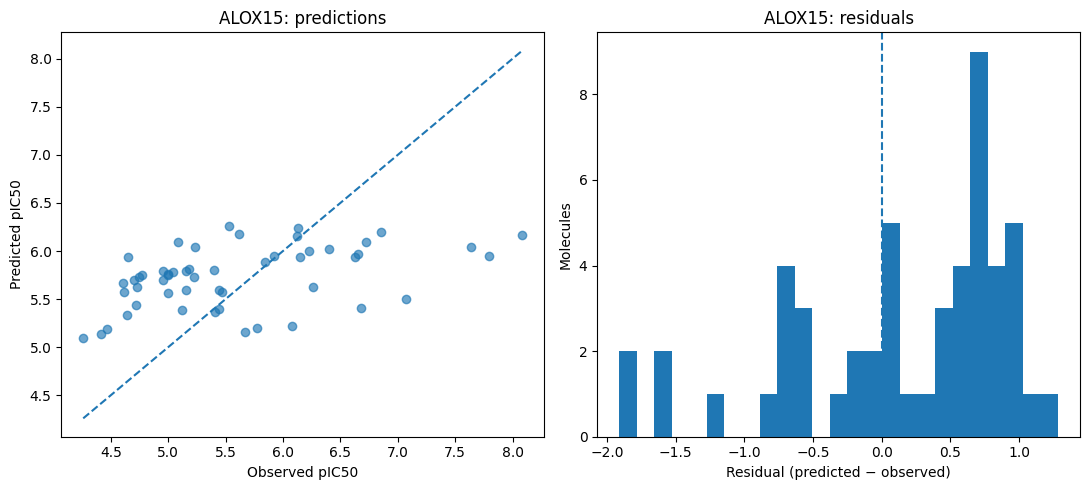

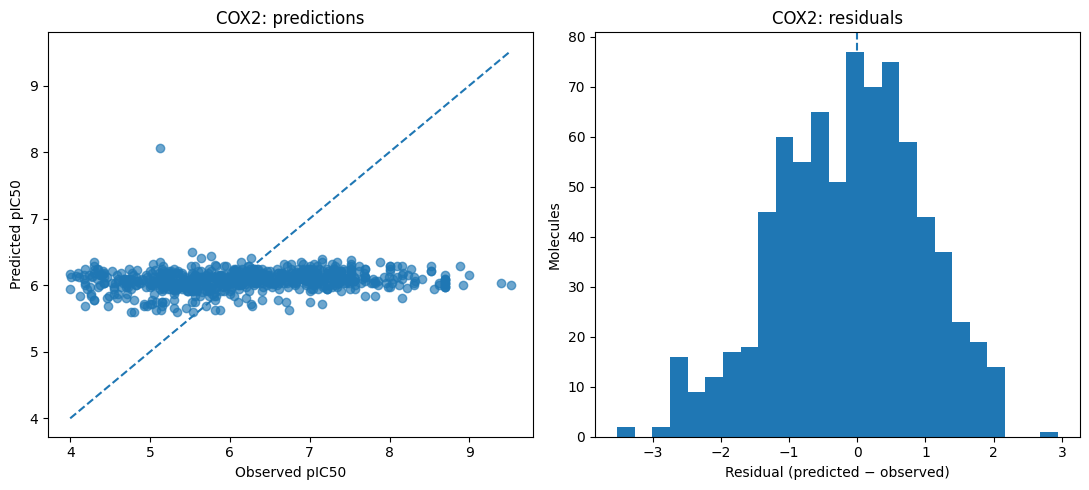

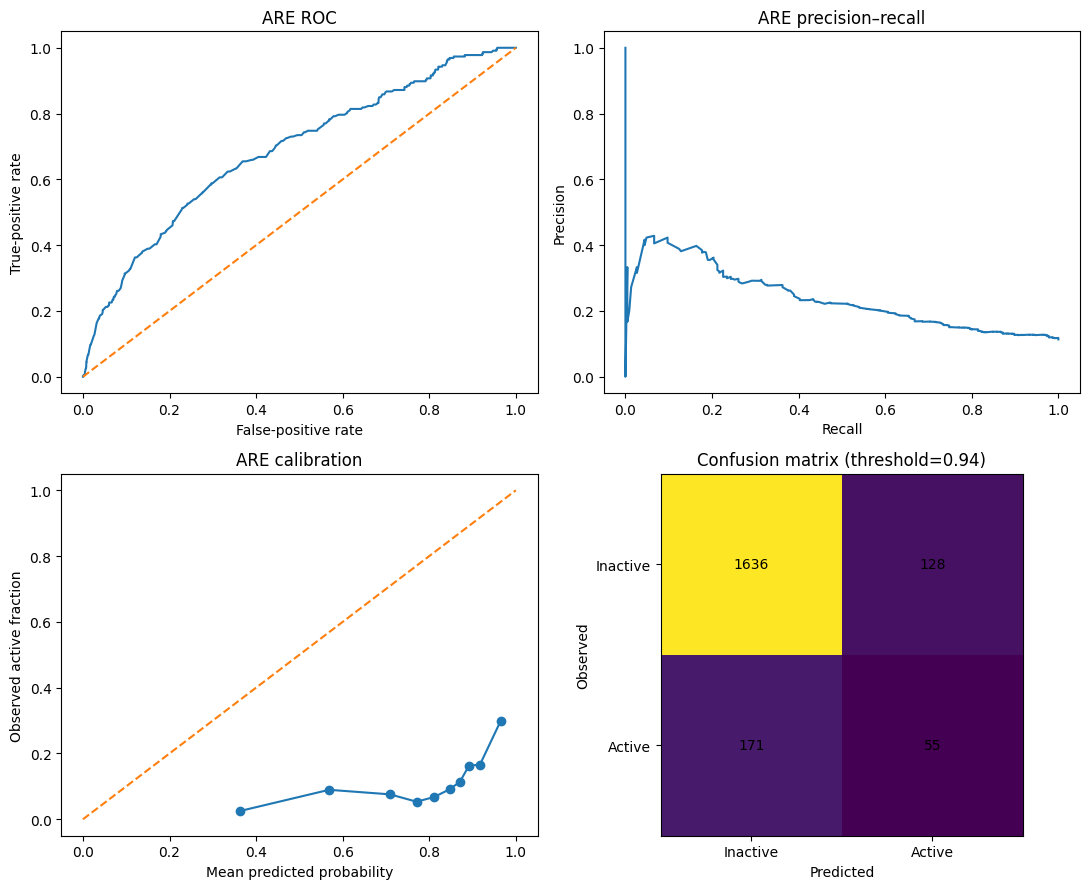

In [ ]:
# Diagnostic curves from the first available 3D seed for each endpoint.
for task in ["ALOX15", "COX2", "ARE"]:
    prediction_path = DIRS["tables"] / f"predictions_{task}_EGNN_3D_multiconformer_seed{CONFIG.seeds[0]}.csv"
    if not prediction_path.exists():
        continue
    pred = pd.read_csv(prediction_path)
    if task != "ARE":
        fig, axes = plt.subplots(1, 2, figsize=(11, 5))
        axes[0].scatter(pred.y_true, pred.y_pred, alpha=0.65)
        limits = [min(pred.y_true.min(), pred.y_pred.min()), max(pred.y_true.max(), pred.y_pred.max())]
        axes[0].plot(limits, limits, linestyle="--")
        axes[0].set_xlabel("Observed pIC50"); axes[0].set_ylabel("Predicted pIC50")
        axes[0].set_title(f"{task}: predictions")
        axes[1].hist(pred.y_pred - pred.y_true, bins=25)
        axes[1].axvline(0, linestyle="--"); axes[1].set_xlabel("Residual (predicted − observed)")
        axes[1].set_ylabel("Molecules"); axes[1].set_title(f"{task}: residuals")
        fig.tight_layout(); fig.savefig(DIRS["figures"] / f"figure_parity_{task}.png", dpi=300, bbox_inches="tight"); plt.show()
    else:
        fpr, tpr, _ = roc_curve(pred.y_true, pred.y_pred)
        precision, recall, _ = precision_recall_curve(pred.y_true, pred.y_pred)
        prob_true, prob_pred = calibration_curve(pred.y_true, pred.y_pred, n_bins=min(10, max(3, len(pred)//5)), strategy="quantile")
        threshold = float(pred.threshold.dropna().iloc[0]) if "threshold" in pred and pred.threshold.notna().any() else 0.5
        matrix = confusion_matrix(pred.y_true, pred.y_pred >= threshold)
        fig, axes = plt.subplots(2, 2, figsize=(11, 9))
        axes[0,0].plot(fpr, tpr); axes[0,0].plot([0, 1], [0, 1], linestyle="--")
        axes[0,0].set_xlabel("False-positive rate"); axes[0,0].set_ylabel("True-positive rate"); axes[0,0].set_title("ARE ROC")
        axes[0,1].plot(recall, precision); axes[0,1].set_xlabel("Recall"); axes[0,1].set_ylabel("Precision"); axes[0,1].set_title("ARE precision–recall")
        axes[1,0].plot(prob_pred, prob_true, marker="o"); axes[1,0].plot([0,1],[0,1], linestyle="--")
        axes[1,0].set_xlabel("Mean predicted probability"); axes[1,0].set_ylabel("Observed active fraction"); axes[1,0].set_title("ARE calibration")
        image = axes[1,1].imshow(matrix)
        for (i, j), value in np.ndenumerate(matrix): axes[1,1].text(j, i, str(value), ha="center", va="center")
        axes[1,1].set_xticks([0,1], ["Inactive", "Active"]); axes[1,1].set_yticks([0,1], ["Inactive", "Active"])
        axes[1,1].set_xlabel("Predicted"); axes[1,1].set_ylabel("Observed"); axes[1,1].set_title(f"Confusion matrix (threshold={threshold:.2f})")
        fig.tight_layout(); fig.savefig(DIRS["figures"] / "figure_ARE_curves.png", dpi=300, bbox_inches="tight"); plt.show()

## 19. Candidate-metabolite input and provenance controls

In [ ]:
from pathlib import Path
import pandas as pd
from rdkit import Chem

candidate_rows = [
    {
        "compound_name": "Gallic acid",
        "smiles": "O=C(O)c1cc(O)c(O)c(O)c1",
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Jin et al. (2012), Phenolic compounds and antioxidant "
            "activity of bulb extracts of six Lilium species native "
            "to China. DOI: 10.3390/molecules17089361; PMID: 22864243"
        ),
        "analytical_method": "HPLC-PDA comparison with authentic standard",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Reported in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Myricetin",
        "smiles": (
            "O=c1c(O)c(-c2cc(O)c(O)c(O)c2)"
            "oc2cc(O)cc(O)c12"
        ),
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Jin et al. (2012), DOI: 10.3390/molecules17089361; "
            "PMID: 22864243"
        ),
        "analytical_method": "HPLC-PDA comparison with authentic standard",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Reported in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "p-Coumaric acid",
        "smiles": "O=C(O)/C=C/c1ccc(O)cc1",
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Jin et al. (2012), DOI: 10.3390/molecules17089361; "
            "PMID: 22864243"
        ),
        "analytical_method": "HPLC-PDA comparison with authentic standard",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Reported in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Quercetin",
        "smiles": (
            "O=c1c(O)c(-c2ccc(O)c(O)c2)"
            "oc2cc(O)cc(O)c12"
        ),
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Jin et al. (2012), DOI: 10.3390/molecules17089361; "
            "PMID: 22864243"
        ),
        "analytical_method": "HPLC-PDA comparison with authentic standard",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Reported in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Kaempferol",
        "smiles": (
            "O=c1c(O)c(-c2ccc(O)cc2)"
            "oc2cc(O)cc(O)c12"
        ),
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Jin et al. (2012), DOI: 10.3390/molecules17089361; "
            "PMID: 22864243"
        ),
        "analytical_method": "HPLC-PDA comparison with authentic standard",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Reported in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Caffeic acid",
        "smiles": "O=C(O)/C=C/c1ccc(O)c(O)c1",
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Analysis and evaluation of eight active ingredients in "
            "Lilium lancifolium from different regions (2017). "
            "DOI: 10.19540/j.cnki.cjcmm.20161222.035; "
            "PMID: 28948737"
        ),
        "analytical_method": "UPLC-TQ-MS/MS",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Quantified in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Ferulic acid",
        "smiles": "COc1cc(/C=C/C(=O)O)ccc1O",
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Analysis and evaluation of eight active ingredients in "
            "Lilium lancifolium from different regions (2017). "
            "DOI: 10.19540/j.cnki.cjcmm.20161222.035; "
            "PMID: 28948737"
        ),
        "analytical_method": "UPLC-TQ-MS/MS",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Quantified in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
    {
        "compound_name": "Protocatechualdehyde",
        "smiles": "O=Cc1cc(O)c(O)cc1",
        "reported_species": "Lilium lancifolium",
        "plant_tissue": "Bulb",
        "source_citation": (
            "Analysis and evaluation of eight active ingredients in "
            "Lilium lancifolium from different regions (2017). "
            "DOI: 10.19540/j.cnki.cjcmm.20161222.035; "
            "PMID: 28948737"
        ),
        "analytical_method": "UPLC-TQ-MS/MS",
        "provenance_tier": "T2_OTHER_LILIUM_SPECIES_REPORTED",
        "notes": (
            "Quantified in L. lancifolium; not confirmed in "
            "Lilium mackliniae."
        ),
    },
]

candidate_df = pd.DataFrame(candidate_rows)

# Validate every molecular structure before saving.
invalid_compounds = [
    row["compound_name"]
    for row in candidate_rows
    if Chem.MolFromSmiles(row["smiles"]) is None
]

assert not invalid_compounds, (
    f"Invalid SMILES detected: {invalid_compounds}"
)

output_directory = Path(
    "/content/sirolily_geometric_bioprospecting/input"
)
output_directory.mkdir(parents=True, exist_ok=True)

output_path = output_directory / "candidate_metabolites.csv"
candidate_df.to_csv(output_path, index=False)

print(f"✅ Created: {output_path}")
print(f"✅ Number of candidates: {len(candidate_df)}")
display(candidate_df)

✅ Created: /content/sirolily_geometric_bioprospecting/input/candidate_metabolites.csv
✅ Number of candidates: 8


,compound_name,smiles,reported_species,plant_tissue,source_citation,analytical_method,provenance_tier,notes
0,Gallic acid,O=C(O)c1cc(O)c(O)c(O)c1,Lilium lancifolium,Bulb,"Jin et al. (2012), Phenolic compounds and anti...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...
1,Myricetin,O=c1c(O)c(-c2cc(O)c(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...
2,p-Coumaric acid,O=C(O)/C=C/c1ccc(O)cc1,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...
3,Quercetin,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...
4,Kaempferol,O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...
5,Caffeic acid,O=C(O)/C=C/c1ccc(O)c(O)c1,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...
6,Ferulic acid,COc1cc(/C=C/C(=O)O)ccc1O,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...
7,Protocatechualdehyde,O=Cc1cc(O)c(O)cc1,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...


In [ ]:
TEMPLATE_PATH = DIRS["input"] / "candidate_metabolites_template.csv"
if not TEMPLATE_PATH.exists():
    pd.DataFrame(columns=[
        "compound_name", "smiles", "reported_species", "plant_tissue", "source_citation",
        "analytical_method", "provenance_tier", "notes"
    ]).to_csv(TEMPLATE_PATH, index=False)
print("Candidate template:", TEMPLATE_PATH)

CANDIDATE_PATH = DIRS["input"] / "candidate_metabolites.csv"
if IN_COLAB and not CANDIDATE_PATH.exists() and CONFIG.run_profile != "smoke":
    print("Optional upload: candidate_metabolites.csv. If skipped, only a non-species-specific demonstration library is screened.")
    try:
        from google.colab import files
        uploaded = files.upload()
        if uploaded:
            uploaded_name = next(iter(uploaded))
            Path(uploaded_name).replace(CANDIDATE_PATH)
    except Exception as exc:
        print("Upload skipped:", exc)

if CANDIDATE_PATH.exists():
    candidates = pd.read_csv(CANDIDATE_PATH)
    required = {"compound_name", "smiles", "provenance_tier", "source_citation"}
    missing = required - set(candidates.columns)
    if missing:
        raise ValueError(f"Candidate file is missing required columns: {missing}")
else:
    # Demonstration only. These compounds are not asserted to occur in L. mackliniae.
    candidates = pd.DataFrame([
        ["Quercetin", "O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12"],
        ["Kaempferol", "O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12"],
        ["Caffeine", "Cn1c(=O)c2c(ncn2C)n(C)c1=O"],
        ["Aspirin", "CC(=O)Oc1ccccc1C(=O)O"],
    ], columns=["compound_name", "smiles"])
    candidates["reported_species"] = "Demonstration only"
    candidates["plant_tissue"] = "Not applicable"
    candidates["source_citation"] = "No species-occurrence claim; pipeline demonstration"
    candidates["analytical_method"] = "Not applicable"
    candidates["provenance_tier"] = "DEMO_NOT_SPECIES_CONFIRMED"
    candidates["notes"] = "Do not describe as a Siroi lily metabolite."

standardized_candidate_records = []
for _, row in candidates.iterrows():
    result = standardize_smiles(row["smiles"])
    if result:
        standardized_candidate_records.append({**row.to_dict(), **result})
candidates = pd.DataFrame(standardized_candidate_records)
candidates.to_csv(DIRS["processed"] / "candidate_metabolites_standardized.csv", index=False)
display(candidates.head())

Candidate template: /content/sirolily_geometric_bioprospecting/input/candidate_metabolites_template.csv


[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Normalizer
[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Normalizer
[18:07:30] Running LargestFragmentChooser
[18:07:30] Running Uncharger
[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Normalizer
[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Normalizer
[18:07:30] Running LargestFragmentChooser
[18:07:30] Running Uncharger
[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Normalizer
[18:07:30] Initializing MetalDisconnector
[18:07:30] Running MetalDisconnector
[18:07:30] Initializing Normalizer
[18:07:30] Running Norma

,compound_name,smiles,reported_species,plant_tissue,source_citation,analytical_method,provenance_tier,notes,standard_smiles,inchikey,connectivity_key,scaffold,heavy_atoms,mol_wt,logp,tpsa
0,Gallic acid,O=C(O)c1cc(O)c(O)c(O)c1,Lilium lancifolium,Bulb,"Jin et al. (2012), Phenolic compounds and anti...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=C(O)c1cc(O)c(O)c(O)c1,LNTHITQWFMADLM-UHFFFAOYSA-N,LNTHITQWFMADLM,c1ccccc1,12,170.120,0.5016,97.99
1,Myricetin,O=c1c(O)c(-c2cc(O)c(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2cc(O)c(O)c(O)c2)oc2cc(O)cc(O)c12,IKMDFBPHZNJCSN-UHFFFAOYSA-N,IKMDFBPHZNJCSN,O=c1cc(-c2ccccc2)oc2ccccc12,23,318.237,1.6936,151.59
2,p-Coumaric acid,O=C(O)/C=C/c1ccc(O)cc1,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=C(O)/C=C/c1ccc(O)cc1,NGSWKAQJJWESNS-ZZXKWVIFSA-N,NGSWKAQJJWESNS,c1ccccc1,12,164.160,1.4900,57.53
3,Quercetin,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,REFJWTPEDVJJIY-UHFFFAOYSA-N,REFJWTPEDVJJIY,O=c1cc(-c2ccccc2)oc2ccccc12,22,302.238,1.9880,131.36
4,Kaempferol,O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12,IYRMWMYZSQPJKC-UHFFFAOYSA-N,IYRMWMYZSQPJKC,O=c1cc(-c2ccccc2)oc2ccccc12,21,286.239,2.2824,111.13


## 20. Candidate screening with ensemble and conformer uncertainty

In [ ]:
def load_single_task_model(task, model_name, seed):
    checkpoint = torch.load(DIRS["models"] / f"{task}_{model_name}_seed{seed}.pt", map_location="cpu", weights_only=False)
    if model_name == "EGNN_3D_multiconformer":
        model = GeometricMPNN(CONFIG.hidden_dim, CONFIG.num_layers, CONFIG.rbf_dim, CONFIG.dropout, CONFIG.coord_scale)
    else:
        raise ValueError(model_name)
    model.load_state_dict(checkpoint["state_dict"])
    return model.eval().to(DEVICE)


# Reuse training fingerprints and validation-derived similarity thresholds from the applicability-domain analysis.
candidate_ad_resources = {}
for task in ["ALOX15", "COX2", "ARE"]:
    training_smiles = curated[(curated.task == task) & (curated.split == "train")].standard_smiles
    candidate_ad_resources[task] = [rdkit_fp(s) for s in training_smiles if rdkit_fp(s) is not None]

def screen_candidates(candidates):
    model_ensembles = {
        task: [load_single_task_model(task, "EGNN_3D_multiconformer", seed) for seed in CONFIG.seeds]
        for task in ["ALOX15", "COX2", "ARE"]
    }
    rows = []
    for candidate_index, row in tqdm(candidates.iterrows(), total=len(candidates), desc="Screening candidates"):
        seed = CONFIG.base_seed + int(hashlib.sha256(row.standard_smiles.encode()).hexdigest()[:8], 16)
        graphs = generate_graphs(row.standard_smiles, seed)
        if not graphs:
            continue
        for graph in graphs:
            graph.mol_idx = torch.tensor([candidate_index])
        loader = DataLoader(graphs, batch_size=len(graphs), shuffle=False)
        batch = next(iter(loader)).to(DEVICE)
        record = row.to_dict()
        candidate_fp = rdkit_fp(row.standard_smiles)
        for task in ["ALOX15", "COX2", "ARE"]:
            train_fps = candidate_ad_resources[task]
            similarity = max(DataStructs.BulkTanimotoSimilarity(candidate_fp, train_fps)) if candidate_fp is not None and train_fps else 0.0
            record[f"{task}_max_train_tanimoto"] = float(similarity)
            record[f"{task}_similarity_ad_threshold"] = float(ad_thresholds[task])
            record[f"{task}_inside_similarity_domain"] = bool(similarity >= ad_thresholds[task])
            seed_predictions = []
            for model in model_ensembles[task]:
                with torch.no_grad(), autocast_context():
                    raw = model(batch).float()
                    values = torch.sigmoid(raw) if task == "ARE" else raw
                seed_predictions.append(values.detach().cpu().numpy())
            matrix = np.vstack(seed_predictions)  # seeds x conformers
            record[f"{task}_prediction"] = float(matrix.mean())
            record[f"{task}_model_sd"] = float(matrix.mean(axis=1).std(ddof=1)) if matrix.shape[0] > 1 else 0.0
            record[f"{task}_conformer_sd"] = float(matrix.mean(axis=0).std(ddof=1)) if matrix.shape[1] > 1 else 0.0
        rows.append(record)
    output = pd.DataFrame(rows)
    if len(output):
        # Transparent heuristic ranking; retain individual predictions rather than presenting this score as a biological measurement.
        for task in ["ALOX15", "COX2", "ARE"]:
            output[f"{task}_rank_percentile"] = output[f"{task}_prediction"].rank(pct=True)
        uncertainty = output[[f"{t}_model_sd" for t in ["ALOX15", "COX2", "ARE"]]].mean(axis=1)
        output["prioritization_score"] = output[[f"{t}_rank_percentile" for t in ["ALOX15", "COX2", "ARE"]]].mean(axis=1) - 0.10 * uncertainty
        output = output.sort_values("prioritization_score", ascending=False)
    return output

candidate_predictions = screen_candidates(candidates)
candidate_predictions.to_csv(DIRS["tables"] / "candidate_predictions.csv", index=False)
display(candidate_predictions)

Screening candidates:   0%|          | 0/8 [00:00<?, ?it/s]

,compound_name,smiles,reported_species,plant_tissue,source_citation,analytical_method,provenance_tier,notes,standard_smiles,inchikey,...,ARE_max_train_tanimoto,ARE_similarity_ad_threshold,ARE_inside_similarity_domain,ARE_prediction,ARE_model_sd,ARE_conformer_sd,ALOX15_rank_percentile,COX2_rank_percentile,ARE_rank_percentile,prioritization_score
1,Myricetin,O=c1c(O)c(-c2cc(O)c(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2cc(O)c(O)c(O)c2)oc2cc(O)cc(O)c12,IKMDFBPHZNJCSN-UHFFFAOYSA-N,...,0.756757,0.266667,True,0.827277,0.157021,0.00000,1.000,0.9375,1.000,0.932482
3,Quercetin,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12,REFJWTPEDVJJIY-UHFFFAOYSA-N,...,1.000000,0.266667,True,0.822959,0.158443,0.00056,0.875,0.9375,0.875,0.854259
4,Kaempferol,O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=c1c(O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12,IYRMWMYZSQPJKC-UHFFFAOYSA-N,...,1.000000,0.266667,True,0.817893,0.159036,0.00000,0.750,0.7500,0.750,0.713229
5,Caffeic acid,O=C(O)/C=C/c1ccc(O)c(O)c1,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...,O=C(O)/C=C/c1ccc(O)c(O)c1,QAIPRVGONGVQAS-DUXPYHPUSA-N,...,0.437500,0.266667,True,0.725471,0.140316,0.00000,0.625,0.5000,0.625,0.561357
6,Ferulic acid,COc1cc(/C=C/C(=O)O)ccc1O,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...,COc1cc(/C=C/C(=O)O)ccc1O,KSEBMYQBYZTDHS-HWKANZROSA-N,...,0.431818,0.266667,True,0.711518,0.137140,0.00000,0.500,0.3750,0.375,0.397083
0,Gallic acid,O=C(O)c1cc(O)c(O)c(O)c1,Lilium lancifolium,Bulb,"Jin et al. (2012), Phenolic compounds and anti...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=C(O)c1cc(O)c(O)c(O)c1,LNTHITQWFMADLM-UHFFFAOYSA-N,...,0.416667,0.266667,True,0.709819,0.133152,0.00000,0.250,0.6250,0.250,0.346186
2,p-Coumaric acid,O=C(O)/C=C/c1ccc(O)cc1,Lilium lancifolium,Bulb,"Jin et al. (2012), DOI: 10.3390/molecules17089...",HPLC-PDA comparison with authentic standard,T2_OTHER_LILIUM_SPECIES_REPORTED,Reported in L. lancifolium; not confirmed in L...,O=C(O)/C=C/c1ccc(O)cc1,NGSWKAQJJWESNS-ZZXKWVIFSA-N,...,0.400000,0.266667,True,0.714815,0.140024,0.00000,0.375,0.1875,0.500,0.333212
7,Protocatechualdehyde,O=Cc1cc(O)c(O)cc1,Lilium lancifolium,Bulb,Analysis and evaluation of eight active ingred...,UPLC-TQ-MS/MS,T2_OTHER_LILIUM_SPECIES_REPORTED,Quantified in L. lancifolium; not confirmed in...,O=Cc1ccc(O)c(O)c1,IBGBGRVKPALMCQ-UHFFFAOYSA-N,...,0.400000,0.266667,True,0.685500,0.131153,0.00000,0.125,0.1875,0.125,0.118336


## 21. Final validation gate and paper-ready export

In [ ]:
def final_validation_gate():
    checks = []
    def check(name, condition, detail=""):
        checks.append({"check": name, "passed": bool(condition), "detail": detail})
        if CONFIG.strict_data_validation and not condition:
            raise AssertionError(f"Validation failed: {name}. {detail}")

    check("Three endpoints present", set(curated.task) == {"ALOX15", "COX2", "ARE"})
    check("No scaffold leakage", curated.groupby("scaffold").split.nunique().max() == 1)
    check("No exact-structure leakage", curated.groupby("standard_smiles").split.nunique().max() == 1)
    check("Finite labels", np.isfinite(curated.label).all())
    check("All endpoint models evaluated", all_metric_rows.task.nunique() == 3)
    check("Class test contains both labels", curated[(curated.task == "ARE") & (curated.split == "test")].label.nunique() == 2)
    check("Candidate provenance retained", {"provenance_tier", "source_citation"}.issubset(candidate_predictions.columns))
    check("Candidate applicability domain reported", any(c.endswith("inside_similarity_domain") for c in candidate_predictions.columns))
    check("Bootstrap intervals generated", (DIRS["tables"] / "bootstrap_primary_metrics.csv").exists())
    check("Figures generated", len(list(DIRS["figures"].glob("*.png"))) >= 3)
    check("Checkpoints generated", len(list(DIRS["models"].glob("*.pt"))) >= 3)
    report = pd.DataFrame(checks)
    report.to_csv(DIRS["tables"] / "validation_report.csv", index=False)
    return report

validation_report = final_validation_gate()
display(validation_report)

# Machine-readable environment and file hashes
file_manifest = []
for path in sorted(ROOT.rglob("*")):
    if path.is_file() and path.suffix != ".zip":
        file_manifest.append({
            "relative_path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        })
pd.DataFrame(file_manifest).to_csv(ROOT / "file_manifest_sha256.csv", index=False)

environment = {
    "completed_utc": datetime.now(timezone.utc).isoformat(),
    "run_profile": CONFIG.run_profile,
    "python": sys.version,
    "platform": platform.platform(),
    "gpu": GPU_NAME,
    "pytorch": torch.__version__,
    "rdkit": rdBase.rdkitVersion,
    "torch_geometric": __import__('torch_geometric').__version__,
    "sklearn": sklearn.__version__,
    "xgboost": xgb.__version__,
    "scaffold_split_seed": SPLIT_SEED,
}
save_json(environment, ROOT / "environment.json")

# Compact handoff summary for manuscript drafting.
lines = [
    "# Computational experiment handoff", "",
    f"- Completed (UTC): {environment['completed_utc']}",
    f"- Accelerator: {GPU_NAME}",
    f"- Profile: {CONFIG.run_profile}",
    f"- Scaffold split seed: {SPLIT_SEED}", "",
    "## Dataset summary", "", dataset_summary.to_markdown(index=False), "",
    "## Aggregate benchmark metrics", "", aggregate_metrics.to_markdown(index=False), "",
    "## Validation gate", "", validation_report.to_markdown(index=False), "",
    "## Interpretation boundary", "",
    "Predictions are computational prioritizations and require species-occurrence confirmation and experimental validation.",
]
(ROOT / "REPORT_FOR_PAPER.md").write_text("\n".join(lines))

ZIP_PATH = ROOT.parent / f"{CONFIG.project_name}_{CONFIG.run_profile}_results.zip"
if ZIP_PATH.exists(): ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for path in ROOT.rglob("*"):
        if path.is_file():
            archive.write(path, arcname=str(path.relative_to(ROOT.parent)))
print("Final results ZIP:", ZIP_PATH)
print("Size (MB):", ZIP_PATH.stat().st_size / 1e6)

if IN_COLAB:
    from google.colab import files
    print("Use the next line to download the archive if the browser does not prompt automatically:")
    print(f"files.download(r'{ZIP_PATH}')")

,check,passed,detail
0,Three endpoints present,True,
1,No scaffold leakage,True,
2,No exact-structure leakage,True,
3,Finite labels,True,
4,All endpoint models evaluated,True,
5,Class test contains both labels,True,
6,Candidate provenance retained,True,
7,Candidate applicability domain reported,True,
8,Bootstrap intervals generated,True,
9,Figures generated,True,


Final results ZIP: /content/sirolily_geometric_bioprospecting_paper_results.zip
Size (MB): 643.19415
Use the next line to download the archive if the browser does not prompt automatically:
files.download(r'/content/sirolily_geometric_bioprospecting_paper_results.zip')


In [32]:
from pathlib import Path
import zipfile
import json
import hashlib
from IPython.display import FileLink, display

ROOT = Path("/content/sirolily_geometric_bioprospecting")
OUTPUT_DIR = Path("/content/sirolily_handoff_parts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COMPACT_ZIP = OUTPUT_DIR / "01_Siroi_Lily_Paper_Handoff.zip"

# Files useful for paper writing and result verification.
allowed_extensions = {
    ".csv", ".json", ".txt", ".md", ".yaml", ".yml",
    ".png", ".jpg", ".jpeg", ".svg", ".pdf", ".html"
}

# Exclude very large artifacts that are not initially needed for writing.
excluded_keywords = {
    "checkpoint",
    "checkpoints",
    "graph_cache",
    "cached_graph",
    "conformer_cache",
    "model_state",
    "optimizer_state",
    "shard"
}

selected_files = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    relative_path = path.relative_to(ROOT)
    relative_text = str(relative_path).lower()

    if path.suffix.lower() == ".zip":
        continue

    if any(keyword in relative_text for keyword in excluded_keywords):
        continue

    useful_name = any(
        keyword in relative_text
        for keyword in [
            "table",
            "figure",
            "metric",
            "prediction",
            "history",
            "summary",
            "manifest",
            "config",
            "split",
            "audit",
            "candidate",
            "bootstrap",
            "ablation",
            "applicability",
            "environment",
            "validation",
            "exclusion",
            "processed",
            "raw",
        ]
    )

    if path.suffix.lower() in allowed_extensions or useful_name:
        selected_files.append(path)

assert selected_files, "No files were selected for the compact archive."

with zipfile.ZipFile(
    COMPACT_ZIP,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
) as archive:
    for path in selected_files:
        archive.write(
            path,
            arcname=str(path.relative_to(ROOT.parent)),
        )

compact_manifest = {
    "archive": COMPACT_ZIP.name,
    "number_of_files": len(selected_files),
    "size_mb": round(COMPACT_ZIP.stat().st_size / 1e6, 3),
    "sha256": hashlib.sha256(COMPACT_ZIP.read_bytes()).hexdigest(),
    "included_files": [
        str(path.relative_to(ROOT))
        for path in selected_files
    ],
}

manifest_path = OUTPUT_DIR / "01_Siroi_Lily_Paper_Handoff_manifest.json"
manifest_path.write_text(
    json.dumps(compact_manifest, indent=2),
    encoding="utf-8",
)

print("✅ Compact paper handoff created")
print("Path:", COMPACT_ZIP)
print("Files:", len(selected_files))
print("Size:", round(COMPACT_ZIP.stat().st_size / 1e6, 2), "MB")

display(FileLink(str(COMPACT_ZIP)))
display(FileLink(str(manifest_path)))

✅ Compact paper handoff created
Path: /content/sirolily_handoff_parts/01_Siroi_Lily_Paper_Handoff.zip
Files: 269
Size: 87.95 MB


/content/sirolily_handoff_parts/01_Siroi_Lily_Paper_Handoff.zip

/content/sirolily_handoff_parts/01_Siroi_Lily_Paper_Handoff_manifest.json

In [33]:
from pathlib import Path
import hashlib
import json
from IPython.display import FileLink, display

SOURCE_ZIP = Path(
    "/content/sirolily_geometric_bioprospecting_paper_results.zip"
)

PARTS_DIR = Path("/content/sirolily_handoff_parts/full_archive_parts")
PARTS_DIR.mkdir(parents=True, exist_ok=True)

# Each part will be approximately 90 MB.
CHUNK_SIZE = 90 * 1024 * 1024

assert SOURCE_ZIP.exists(), f"Archive not found: {SOURCE_ZIP}"

part_records = []

with SOURCE_ZIP.open("rb") as source:
    part_number = 1

    while True:
        data = source.read(CHUNK_SIZE)

        if not data:
            break

        part_path = PARTS_DIR / (
            f"{SOURCE_ZIP.name}.part{part_number:03d}"
        )

        part_path.write_bytes(data)

        part_records.append({
            "part_number": part_number,
            "filename": part_path.name,
            "size_mb": round(part_path.stat().st_size / 1e6, 3),
            "sha256": hashlib.sha256(data).hexdigest(),
        })

        part_number += 1

manifest = {
    "original_filename": SOURCE_ZIP.name,
    "original_size_mb": round(SOURCE_ZIP.stat().st_size / 1e6, 3),
    "original_sha256": hashlib.sha256(
        SOURCE_ZIP.read_bytes()
    ).hexdigest(),
    "chunk_size_bytes": CHUNK_SIZE,
    "number_of_parts": len(part_records),
    "parts": part_records,
}

manifest_path = PARTS_DIR / "full_archive_parts_manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8",
)

print(f"✅ Created {len(part_records)} parts")
print(f"Location: {PARTS_DIR}")
print()

for record in part_records:
    print(
        record["filename"],
        "—",
        record["size_mb"],
        "MB",
    )

print("\nDownload links:")
for record in part_records:
    display(FileLink(str(PARTS_DIR / record["filename"])))

display(FileLink(str(manifest_path)))

✅ Created 7 parts
Location: /content/sirolily_handoff_parts/full_archive_parts

sirolily_geometric_bioprospecting_paper_results.zip.part001 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part002 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part003 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part004 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part005 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part006 — 94.372 MB
sirolily_geometric_bioprospecting_paper_results.zip.part007 — 76.963 MB

Download links:


/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part001

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part002

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part003

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part004

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part005

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part006

/content/sirolily_handoff_parts/full_archive_parts/sirolily_geometric_bioprospecting_paper_results.zip.part007

/content/sirolily_handoff_parts/full_archive_parts/full_archive_parts_manifest.json

## 22. Required handoff to the co-author

After the `paper` profile finishes, send the generated ZIP archive. It contains:

- immutable raw ChEMBL/PubChem snapshots;
- curated endpoint tables and exclusion audits;
- the locked scaffold split;
- conformer failures and graph cache metadata;
- all seed-level predictions and training histories;
- baseline, neural, multitask, and ablation metrics;
- publication figures;
- candidate predictions with provenance and uncertainty;
- model checkpoints, environment versions, and SHA-256 hashes;
- `REPORT_FOR_PAPER.md` for direct manuscript integration.

Do not rename or manually edit files before submitting the ZIP, because the manifest hashes are part of the reproducibility record.

In [34]:
from pathlib import Path
import gc
import hashlib
import zipfile

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from IPython.display import display, FileLink


# ============================================================
# EXPERIMENT 2:
# HIGH-CONFIDENCE, HUMAN, BIOCHEMICAL, SINGLE-PROTEIN SUBSET
# ============================================================

# Preserve the completed broad-data experiment exactly as it is.
if "_SIROILY_BROAD_STATE" not in globals():
    _SIROILY_BROAD_STATE = {
        "ROOT": ROOT,
        "DIRS": dict(DIRS),
        "curated": curated.copy(deep=True),
        "graph_store": graph_store,
        "split_seed": int(SPLIT_SEED),
    }

BROAD_ROOT = _SIROILY_BROAD_STATE["ROOT"]
BROAD_DIRS = _SIROILY_BROAD_STATE["DIRS"]
BROAD_CURATED = _SIROILY_BROAD_STATE["curated"].copy(deep=True)
BROAD_GRAPH_STORE = _SIROILY_BROAD_STATE["graph_store"]
BROAD_SPLIT_SEED = _SIROILY_BROAD_STATE["split_seed"]

STRICT_ROOT = BROAD_ROOT / "strict_sensitivity"

STRICT_DIRS = {
    "raw": STRICT_ROOT / "data" / "raw",
    "interim": STRICT_ROOT / "data" / "interim",
    "processed": STRICT_ROOT / "data" / "processed",
    "splits": STRICT_ROOT / "data" / "splits",
    "models": STRICT_ROOT / "models",
    "figures": STRICT_ROOT / "figures",
    "tables": STRICT_ROOT / "tables",
    "logs": STRICT_ROOT / "logs",
    "input": STRICT_ROOT / "input",
}

for path in STRICT_DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

# BAO_0000357 = single-protein assay format.
STRICT_MAIN_BAO = "BAO_0000357"
STRICT_TASKS = ("ALOX15", "COX2")


def _read_required_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(
            f"Required cached file is missing: {path}. "
            "Do not restart the runtime; the completed broad experiment "
            "should contain this file."
        )

    return pd.read_csv(path, low_memory=False)


def _boolean_duplicate(series: pd.Series) -> pd.Series:
    return (
        series
        .fillna(0)
        .astype(str)
        .str.strip()
        .str.lower()
        .isin({"1", "true", "yes"})
    )


def _aggregate_compatible_assays(
    frame: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    First aggregate repeated measurements within an individual assay.
    Then aggregate across assays only when they share the same BAO format.

    Molecules with activity disagreement greater than the notebook's
    permitted log-unit range are excluded.
    """

    assay_rows = []
    assay_audit = []

    assay_group_columns = [
        "task",
        "standard_smiles",
        "meta_bao_format",
        "assay_chembl_id",
    ]

    for keys, group in frame.groupby(
        assay_group_columns,
        dropna=False,
        sort=False,
    ):
        values = group["label"].astype(float)
        value_range = float(values.max() - values.min())

        keep = (
            value_range
            <= CONFIG.max_replicate_range_log_units
        )

        assay_audit.append({
            "task": keys[0],
            "standard_smiles": keys[1],
            "bao_format": keys[2],
            "assay_chembl_id": keys[3],
            "raw_measurements": int(len(group)),
            "range_log_units": value_range,
            "kept": bool(keep),
        })

        if not keep:
            continue

        row = group.iloc[0].copy()

        row["label"] = float(values.median())
        row["within_assay_replicates"] = int(len(group))
        row["within_assay_range"] = value_range

        row["source_record_ids"] = ";".join(
            sorted(
                group["source_record_id"]
                .dropna()
                .astype(str)
                .unique()
            )
        )

        assay_rows.append(row)

    assay_level = pd.DataFrame(assay_rows)

    if assay_level.empty:
        return assay_level, pd.DataFrame(assay_audit)

    molecule_rows = []

    molecule_group_columns = [
        "task",
        "standard_smiles",
        "meta_bao_format",
    ]

    for keys, group in assay_level.groupby(
        molecule_group_columns,
        dropna=False,
        sort=False,
    ):
        values = group["label"].astype(float)
        value_range = float(values.max() - values.min())

        if (
            value_range
            > CONFIG.max_replicate_range_log_units
        ):
            continue

        row = group.iloc[0].copy()

        row["label"] = float(values.median())
        row["assay_count"] = int(
            group["assay_chembl_id"].nunique()
        )
        row["document_count"] = int(
            group["document_chembl_id"].nunique()
        )
        row["replicate_count"] = int(
            group["within_assay_replicates"].sum()
        )
        row["replicate_range"] = value_range

        row["assay_chembl_ids"] = ";".join(
            sorted(
                group["assay_chembl_id"]
                .dropna()
                .astype(str)
                .unique()
            )
        )

        row["source_record_ids"] = ";".join(
            sorted({
                item
                for text in (
                    group["source_record_ids"]
                    .dropna()
                    .astype(str)
                )
                for item in text.split(";")
                if item
            })
        )

        row["assay_format"] = keys[2]
        molecule_rows.append(row)

    molecule_level = pd.DataFrame(
        molecule_rows
    ).reset_index(drop=True)

    return molecule_level, pd.DataFrame(assay_audit)


def strict_curate_chembl(
    task: str,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:

    activities = _read_required_csv(
        BROAD_DIRS["interim"]
        / f"{task}_chembl_download.csv"
    )

    assays = _read_required_csv(
        BROAD_DIRS["interim"]
        / f"{task}_assays.csv"
    )

    molecules = _read_required_csv(
        BROAD_DIRS["interim"]
        / f"{task}_molecules.csv"
    )

    assays = assays.rename(columns={
        "assay_type": "meta_assay_type",
        "assay_organism": "meta_assay_organism",
        "assay_tax_id": "meta_assay_tax_id",
        "bao_format": "meta_bao_format",
        "bao_label": "meta_bao_label",
        "description": "meta_assay_description",
    })

    molecules = molecules.rename(columns={
        "canonical_smiles": "molecule_canonical_smiles",
        "standard_inchi_key":
            "molecule_standard_inchi_key",
        "parent_molecule_chembl_id":
            "molecule_parent_chembl_id",
    })

    assay_columns = [
        column
        for column in [
            "assay_chembl_id",
            "confidence_score",
            "meta_assay_type",
            "meta_assay_organism",
            "meta_assay_tax_id",
            "meta_bao_format",
            "meta_bao_label",
            "meta_assay_description",
            "relationship_type",
            "confidence_description",
            "document_chembl_id",
        ]
        if column in assays.columns
    ]

    molecule_columns = [
        column
        for column in [
            "molecule_chembl_id",
            "molecule_canonical_smiles",
            "molecule_standard_inchi_key",
            "molecule_parent_chembl_id",
        ]
        if column in molecules.columns
    ]

    merged = activities.merge(
        assays[assay_columns],
        on="assay_chembl_id",
        how="left",
        suffixes=("", "_meta"),
    )

    merged = merged.merge(
        molecules[molecule_columns],
        on="molecule_chembl_id",
        how="left",
    )

    standard_value = pd.to_numeric(
        merged["standard_value"],
        errors="coerce",
    )

    confidence = pd.to_numeric(
        merged["confidence_score"],
        errors="coerce",
    )

    target_tax_id = pd.to_numeric(
        merged["target_tax_id"],
        errors="coerce",
    )

    standard_flag = pd.to_numeric(
        merged["standard_flag"],
        errors="coerce",
    ).fillna(0)

    assay_organism = (
        merged["meta_assay_organism"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    target_organism = (
        merged["target_organism"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.casefold()
    )

    validity = (
        merged.get(
            "data_validity_comment",
            pd.Series("", index=merged.index),
        )
        .fillna("")
        .astype(str)
        .str.casefold()
    )

    duplicate = _boolean_duplicate(
        merged.get(
            "potential_duplicate",
            pd.Series(0, index=merged.index),
        )
    )

    masks = {
        "raw_download":
            pd.Series(True, index=merged.index),

        "exact_standardized_ic50": (
            merged["standard_type"].eq("IC50")
            & merged["standard_relation"].eq("=")
            & merged["standard_units"].eq("nM")
            & standard_value.gt(0)
            & standard_flag.eq(1)
        ),

        "exact_human_target": (
            target_organism.eq("homo sapiens")
            & target_tax_id.eq(9606)
        ),

        "confidence_9":
            confidence.eq(9),

        "biochemical_assay": (
            merged["assay_type"].eq("B")
            & merged["meta_assay_type"].eq("B")
        ),

        "explicit_human_assay_organism":
            assay_organism.eq("homo sapiens"),

        "valid_nonduplicate": (
            ~duplicate
            & ~validity.str.contains(
                (
                    "outside typical range"
                    "|non standard unit"
                    "|invalid"
                ),
                regex=True,
            )
        ),
    }

    cumulative = pd.Series(
        True,
        index=merged.index,
    )

    audit_rows = []

    for step, mask in masks.items():
        previous = cumulative.copy()
        cumulative &= mask

        audit_rows.append({
            "task": task,
            "step": step,
            "remaining_rows": int(
                cumulative.sum()
            ),
            "excluded_at_step": int(
                (previous & ~mask).sum()
            ),
        })

    filtered = merged.loc[cumulative].copy()

    filtered["raw_smiles"] = (
        filtered["canonical_smiles"]
        .fillna(
            filtered["molecule_canonical_smiles"]
        )
    )

    filtered = filtered[
        filtered["raw_smiles"].notna()
    ].copy()

    filtered["label"] = (
        9.0
        - np.log10(
            pd.to_numeric(
                filtered["standard_value"],
                errors="coerce",
            )
        )
    )

    filtered["task"] = task
    filtered["kind"] = "regression"
    filtered["source"] = "ChEMBL"
    filtered["source_record_id"] = (
        filtered["activity_id"]
    )

    filtered["strict_filter"] = (
        "confidence9_B_explicit-human_"
        "IC50_nM_exact"
    )

    standardized = standardize_dataframe(
        filtered
    )

    all_formats, assay_audit = (
        _aggregate_compatible_assays(
            standardized
        )
    )

    if all_formats.empty:
        raise RuntimeError(
            f"Strict curation produced no compatible "
            f"records for {task}."
        )

    main = all_formats[
        all_formats["meta_bao_format"].eq(
            STRICT_MAIN_BAO
        )
    ].copy()

    if main.empty:
        raise RuntimeError(
            f"No {STRICT_MAIN_BAO} records "
            f"remain for {task}."
        )

    pd.DataFrame(audit_rows).to_csv(
        STRICT_DIRS["logs"]
        / f"{task}_strict_filter_steps.csv",
        index=False,
    )

    assay_audit.to_csv(
        STRICT_DIRS["logs"]
        / f"{task}_strict_assay_replicate_audit.csv",
        index=False,
    )

    standardized.to_csv(
        STRICT_DIRS["interim"]
        / f"{task}_strict_standardized_measurements.csv",
        index=False,
    )

    all_formats.to_csv(
        STRICT_DIRS["processed"]
        / f"{task}_strict_all_bao_formats.csv",
        index=False,
    )

    main.to_csv(
        STRICT_DIRS["processed"]
        / f"{task}_strict_single_protein.csv",
        index=False,
    )

    return (
        main,
        all_formats,
        pd.DataFrame(audit_rows),
    )


strict_main_frames = []
strict_format_frames = []
strict_filter_audits = []

for task in STRICT_TASKS:
    main, all_formats, audit = (
        strict_curate_chembl(task)
    )

    strict_main_frames.append(main)
    strict_format_frames.append(
        all_formats
    )
    strict_filter_audits.append(audit)

strict_chembl = pd.concat(
    strict_main_frames,
    ignore_index=True,
    sort=False,
)

strict_all_formats = pd.concat(
    strict_format_frames,
    ignore_index=True,
    sort=False,
)

strict_filter_audit = pd.concat(
    strict_filter_audits,
    ignore_index=True,
)

strict_filter_audit.to_csv(
    STRICT_DIRS["tables"]
    / "strict_filter_audit.csv",
    index=False,
)


# ARE is unchanged because this sensitivity experiment
# targets heterogeneity in the ChEMBL regression endpoints.
strict_are = BROAD_CURATED[
    BROAD_CURATED["task"].eq("ARE")
].copy()

strict_are["strict_filter"] = (
    "unchanged_PubChem_Tox21_ARE_"
    "with_viability_counter_screen"
)

strict_are["assay_format"] = (
    "TOX21_ARE"
)

strict_curated = pd.concat(
    [
        strict_chembl,
        strict_are,
    ],
    ignore_index=True,
    sort=False,
)

strict_curated["molecule_id"] = np.arange(
    len(strict_curated),
    dtype=int,
)


def strict_hash_fraction(
    text: str,
    seed: int,
) -> float:
    digest = hashlib.sha256(
        f"{seed}|{text}".encode()
    ).hexdigest()

    return (
        int(digest[:16], 16)
        / float(16**16)
    )


def split_from_locked_seed(
    scaffold: str,
) -> str:

    train_fraction, validation_fraction, _ = (
        CONFIG.split_fractions
    )

    value = strict_hash_fraction(
        str(scaffold),
        BROAD_SPLIT_SEED,
    )

    if value < train_fraction:
        return "train"

    if (
        value
        < train_fraction
        + validation_fraction
    ):
        return "val"

    return "test"


strict_curated["split"] = (
    strict_curated["scaffold"]
    .map(split_from_locked_seed)
)

strict_all_formats["split"] = (
    strict_all_formats["scaffold"]
    .map(split_from_locked_seed)
)


# ============================================================
# HARD DATA-INTEGRITY AND LEAKAGE CHECKS
# ============================================================

assert (
    strict_curated
    .groupby("scaffold")["split"]
    .nunique()
    .max()
    == 1
)

assert (
    strict_curated
    .groupby("standard_smiles")["split"]
    .nunique()
    .max()
    == 1
)

assert np.isfinite(
    strict_curated["label"]
).all()

assert not strict_curated.duplicated(
    [
        "task",
        "standard_smiles",
    ]
).any()


for task in STRICT_TASKS:
    subset = strict_curated[
        strict_curated["task"].eq(task)
    ]

    assert len(subset) >= 100, (
        f"Strict {task} dataset "
        f"unexpectedly small: {len(subset)}"
    )

    assert (
        subset["confidence_score"]
        .astype(float)
        .eq(9)
        .all()
    )

    assert (
        subset["meta_assay_type"]
        .eq("B")
        .all()
    )

    assert (
        subset["meta_assay_organism"]
        .astype(str)
        .str.casefold()
        .eq("homo sapiens")
        .all()
    )

    assert (
        subset["meta_bao_format"]
        .eq(STRICT_MAIN_BAO)
        .all()
    )


strict_curated.to_csv(
    STRICT_DIRS["processed"]
    / "strict_curated_endpoints.csv",
    index=False,
)

strict_all_formats.to_csv(
    STRICT_DIRS["processed"]
    / "strict_all_bao_formats.csv",
    index=False,
)

strict_curated[
    [
        "task",
        "standard_smiles",
        "inchikey",
        "scaffold",
        "split",
    ]
].to_csv(
    STRICT_DIRS["splits"]
    / "strict_locked_scaffold_split.csv",
    index=False,
)


strict_dataset_summary = (
    strict_curated
    .groupby(
        [
            "task",
            "split",
        ]
    )
    .agg(
        molecules=(
            "standard_smiles",
            "size",
        ),
        scaffolds=(
            "scaffold",
            "nunique",
        ),
        label_mean=(
            "label",
            "mean",
        ),
        label_std=(
            "label",
            "std",
        ),
    )
    .reset_index()
)

strict_dataset_summary.to_csv(
    STRICT_DIRS["tables"]
    / "strict_dataset_summary.csv",
    index=False,
)


format_summary = (
    strict_all_formats
    .groupby(
        [
            "task",
            "meta_bao_format",
        ]
    )
    .agg(
        molecules=(
            "standard_smiles",
            "nunique",
        ),
        assay_measurement_groups=(
            "assay_count",
            "sum",
        ),
        document_measurement_groups=(
            "document_count",
            "sum",
        ),
        median_label=(
            "label",
            "median",
        ),
    )
    .reset_index()
)

format_summary.to_csv(
    STRICT_DIRS["tables"]
    / "strict_bao_format_summary.csv",
    index=False,
)

print(
    "✅ Strict curation complete. "
    "The broad experiment is untouched."
)

display(strict_dataset_summary)
display(format_summary)

Standardizing structures:   0%|          | 0/400 [00:00<?, ?it/s]

[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Normalizer
[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Normalizer
[18:41:30] Running LargestFragmentChooser
[18:41:30] Running Uncharger
[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Normalizer
[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Normalizer
[18:41:30] Running LargestFragmentChooser
[18:41:30] Running Uncharger
[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Normalizer
[18:41:30] Initializing MetalDisconnector
[18:41:30] Running MetalDisconnector
[18:41:30] Initializing Normalizer
[18:41:30] Running Norma

Standardizing structures:   0%|          | 0/3180 [00:00<?, ?it/s]

Streaming output truncated to the last 5000 lines.
[18:41:51] Running Normalizer
[18:41:51] Running LargestFragmentChooser
[18:41:51] Running Uncharger
[18:41:51] Initializing MetalDisconnector
[18:41:51] Running MetalDisconnector
[18:41:51] Initializing Normalizer
[18:41:51] Running Normalizer
[18:41:51] Initializing MetalDisconnector
[18:41:51] Running MetalDisconnector
[18:41:51] Initializing Normalizer
[18:41:51] Running Normalizer
[18:41:51] Running LargestFragmentChooser
[18:41:51] Running Uncharger
[18:41:51] Initializing MetalDisconnector
[18:41:51] Running MetalDisconnector
[18:41:51] Initializing Normalizer
[18:41:51] Running Normalizer
[18:41:51] Initializing MetalDisconnector
[18:41:51] Running MetalDisconnector
[18:41:51] Initializing Normalizer
[18:41:51] Running Normalizer
[18:41:51] Running LargestFragmentChooser
[18:41:51] Running Uncharger
[18:41:51] Initializing MetalDisconnector
[18:41:51] Running MetalDisconnector
[18:41:51] Initializing Normalizer
[18:41:51] Runni

✅ Strict curation complete. The broad experiment is untouched.


,task,split,molecules,scaffolds,label_mean,label_std
0,ALOX15,test,25,8,5.125049,0.473944
1,ALOX15,train,143,57,5.566376,0.796406
2,ALOX15,val,34,17,5.455639,0.588898
3,ARE,test,1990,442,0.113568,0.317365
4,ARE,train,2873,2023,0.144796,0.351957
5,ARE,val,552,411,0.143116,0.350509
6,COX2,test,408,119,5.984629,1.010209
7,COX2,train,1654,571,6.074988,1.022709
8,COX2,val,240,104,5.988495,1.076837


,task,meta_bao_format,molecules,assay_measurement_groups,document_measurement_groups,median_label
0,ALOX15,BAO_0000019,65,66,65,5.522879
1,ALOX15,BAO_0000219,68,121,68,6.611982
2,ALOX15,BAO_0000357,202,209,208,5.449815
3,COX2,BAO_0000019,27,31,28,5.376751
4,COX2,BAO_0000219,331,336,333,6.801343
5,COX2,BAO_0000221,229,236,236,6.040959
6,COX2,BAO_0000357,2302,2366,2353,6.000000


In [35]:
# ============================================================
# REUSE EXISTING 3D GRAPHS
# GENERATE ONLY STRICT MOLECULES ABSENT FROM THE BROAD CACHE
# ============================================================

strict_smiles = sorted(
    strict_curated[
        "standard_smiles"
    ].unique()
)

strict_graph_store = {
    smiles: BROAD_GRAPH_STORE[smiles]
    for smiles in strict_smiles
    if (
        smiles in BROAD_GRAPH_STORE
        and BROAD_GRAPH_STORE[smiles]
    )
}

missing_smiles = [
    smiles
    for smiles in strict_smiles
    if smiles not in strict_graph_store
]

print(
    f"Reused graphs: "
    f"{len(strict_graph_store):,}"
)

print(
    f"Missing graphs to generate: "
    f"{len(missing_smiles):,}"
)


def _generate_missing_strict_graph(
    smiles: str,
):
    seed = (
        CONFIG.base_seed
        + int(
            hashlib.sha256(
                smiles.encode()
            ).hexdigest()[:8],
            16,
        )
    )

    return (
        smiles,
        generate_graphs(
            smiles,
            seed,
        ),
    )


missing_failures = []
chunk_size = 128

for start in tqdm(
    range(
        0,
        len(missing_smiles),
        chunk_size,
    ),
    desc="Strict missing graph chunks",
):
    chunk = missing_smiles[
        start:start + chunk_size
    ]

    if CONFIG.graph_jobs > 1:
        results = joblib.Parallel(
            n_jobs=CONFIG.graph_jobs,
            prefer="threads",
        )(
            joblib.delayed(
                _generate_missing_strict_graph
            )(smiles)
            for smiles in chunk
        )
    else:
        results = [
            _generate_missing_strict_graph(
                smiles
            )
            for smiles in chunk
        ]

    for smiles, graphs in results:
        if graphs:
            strict_graph_store[
                smiles
            ] = graphs
        else:
            missing_failures.append(
                smiles
            )


strict_curated[
    "graph_available"
] = (
    strict_curated[
        "standard_smiles"
    ].isin(strict_graph_store)
)

strict_graph_success = (
    strict_curated
    .groupby("task")[
        "graph_available"
    ]
    .mean()
    .reset_index(
        name="success_fraction"
    )
)

strict_graph_success.to_csv(
    STRICT_DIRS["tables"]
    / "strict_graph_success.csv",
    index=False,
)

pd.DataFrame({
    "failed_standard_smiles":
        missing_failures
}).to_csv(
    STRICT_DIRS["logs"]
    / "strict_conformer_failures.csv",
    index=False,
)

assert (
    strict_graph_success[
        "success_fraction"
    ].min()
    >= 0.85
), strict_graph_success


strict_curated = (
    strict_curated[
        strict_curated[
            "graph_available"
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

strict_curated[
    "molecule_id"
] = np.arange(
    len(strict_curated),
    dtype=int,
)

strict_curated.to_csv(
    STRICT_DIRS["processed"]
    / (
        "strict_curated_"
        "endpoints_with_graphs.csv"
    ),
    index=False,
)

strict_curated[
    [
        "task",
        "standard_smiles",
        "inchikey",
        "scaffold",
        "split",
    ]
].to_csv(
    STRICT_DIRS["splits"]
    / (
        "strict_locked_scaffold_"
        "split_with_graphs.csv"
    ),
    index=False,
)


strict_dataset_summary = (
    strict_curated
    .groupby(
        [
            "task",
            "split",
        ]
    )
    .agg(
        molecules=(
            "standard_smiles",
            "size",
        ),
        scaffolds=(
            "scaffold",
            "nunique",
        ),
        label_mean=(
            "label",
            "mean",
        ),
        label_std=(
            "label",
            "std",
        ),
    )
    .reset_index()
)

strict_dataset_summary.to_csv(
    STRICT_DIRS["tables"]
    / "strict_dataset_summary.csv",
    index=False,
)


# Save metadata only rather than duplicating
# the very large graph cache in the handoff.
graph_manifest_rows = []

for smiles, graphs in (
    strict_graph_store.items()
):
    graph_manifest_rows.append({
        "standard_smiles":
            smiles,

        "n_conformers":
            len(graphs),

        "n_atoms":
            int(graphs[0].num_nodes)
            if graphs
            else 0,

        "reused_from_broad_cache":
            smiles in BROAD_GRAPH_STORE,
    })

pd.DataFrame(
    graph_manifest_rows
).to_csv(
    STRICT_DIRS["tables"]
    / "strict_graph_manifest.csv",
    index=False,
)


# Switch only the global variables used by
# the notebook's existing training functions.
DIRS = STRICT_DIRS
curated = strict_curated
graph_store = strict_graph_store

print(
    "✅ Strict graph preparation complete."
)

display(strict_graph_success)
display(strict_dataset_summary)

Reused graphs: 7,862
Missing graphs to generate: 12


Strict missing graph chunks:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Strict graph preparation complete.


,task,success_fraction
0,ALOX15,1.000000
1,ARE,1.000000
2,COX2,0.999566


,task,split,molecules,scaffolds,label_mean,label_std
0,ALOX15,test,25,8,5.125049,0.473944
1,ALOX15,train,143,57,5.566376,0.796406
2,ALOX15,val,34,17,5.455639,0.588898
3,ARE,test,1990,442,0.113568,0.317365
4,ARE,train,2873,2023,0.144796,0.351957
5,ARE,val,552,411,0.143116,0.350509
6,COX2,test,408,119,5.984629,1.010209
7,COX2,train,1653,570,6.075637,1.022677
8,COX2,val,240,104,5.988495,1.076837


In [36]:
# ============================================================
# STRICT BENCHMARK TRAINING
#
# Models:
#   1. ECFP4 + Random Forest
#   2. ECFP4 + XGBoost
#   3. 2D MPNN
#   4. Multi-conformer 3D EGNN
#
# Neural models run with five seeds.
# ============================================================

strict_baseline_frames = []
strict_baseline_predictions = {}


# ------------------------------
# Classical fingerprint baselines
# ------------------------------

for task in STRICT_TASKS:
    task_frame = (
        strict_curated[
            strict_curated[
                "task"
            ].eq(task)
        ]
        .reset_index(drop=True)
    )

    result, predictions = (
        fit_classical_baselines(
            task_frame
        )
    )

    strict_baseline_frames.append(
        result
    )

    for model_name, frame in (
        predictions.items()
    ):
        strict_baseline_predictions[
            (
                task,
                model_name,
            )
        ] = frame

        frame.to_csv(
            STRICT_DIRS["tables"]
            / (
                f"strict_predictions_"
                f"{task}_{model_name}.csv"
            ),
            index=False,
        )


strict_baseline_metrics = pd.concat(
    strict_baseline_frames,
    ignore_index=True,
)

strict_baseline_metrics.to_csv(
    STRICT_DIRS["tables"]
    / "strict_baseline_metrics.csv",
    index=False,
)

print(
    "✅ Strict classical baselines completed."
)

display(strict_baseline_metrics)


# ------------------------------
# Neural models
# ------------------------------

strict_neural_metric_rows = []
strict_neural_predictions = {}


for task in STRICT_TASKS:
    task_frame = (
        strict_curated[
            strict_curated[
                "task"
            ].eq(task)
        ]
        .reset_index(drop=True)
    )

    kind = "regression"

    for architecture in (
        "2d",
        "3d",
    ):
        loaders = make_loaders(
            task_frame,
            architecture=architecture,
        )

        for seed in CONFIG.seeds:
            # Seed before model initialization.
            seed_everything(seed)

            if architecture == "2d":
                model = MPNN2D(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.dropout,
                )

                model_name = "MPNN_2D"

            else:
                model = GeometricMPNN(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.rbf_dim,
                    CONFIG.dropout,
                    CONFIG.coord_scale,
                )

                model_name = (
                    "EGNN_3D_multiconformer"
                )

            (
                trained_model,
                metrics,
                predictions,
                history,
            ) = train_single_task_model(
                model,
                loaders,
                kind,
                task,
                model_name,
                seed,
            )

            strict_neural_metric_rows.append(
                metrics
            )

            strict_neural_predictions[
                (
                    task,
                    model_name,
                    seed,
                )
            ] = predictions

            del (
                trained_model,
                model,
                predictions,
                history,
            )

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        del loaders
        gc.collect()


strict_neural_metrics = pd.DataFrame(
    strict_neural_metric_rows
)

strict_neural_metrics.to_csv(
    STRICT_DIRS["tables"]
    / (
        "strict_neural_metrics_"
        "seed_level.csv"
    ),
    index=False,
)

print(
    "✅ Strict model training completed."
)

display(strict_neural_metrics)

✅ Strict classical baselines completed.


,task,model,seed,RMSE,MAE,R2,Pearson_r,Spearman_rho
0,ALOX15,ECFP4_RF,20260717,0.563176,0.497864,-0.470836,-0.030231,0.123989
1,ALOX15,ECFP4_XGB,20260717,0.552580,0.447603,-0.416006,0.076642,0.070466
2,COX2,ECFP4_RF,20260717,0.940178,0.708446,0.131714,0.363283,0.359908
3,COX2,ECFP4_XGB,20260717,0.970776,0.708546,0.074277,0.310787,0.347845


ALOX15 2d train graphs 143 batches 1 maximum atoms/batch 6222
ALOX15 2d val graphs 34 batches 1 maximum atoms/batch 1831
ALOX15 2d test graphs 25 batches 1 maximum atoms/batch 851
ALOX15 3d train graphs 397 batches 2 maximum atoms/batch 15970
ALOX15 3d val graphs 89 batches 1 maximum atoms/batch 5076
ALOX15 3d test graphs 61 batches 1 maximum atoms/batch 2114
COX2 2d train graphs 1653 batches 5 maximum atoms/batch 15991
COX2 2d val graphs 240 batches 1 maximum atoms/batch 11488
COX2 2d test graphs 408 batches 2 maximum atoms/batch 15999
COX2 3d train graphs 4695 batches 14 maximum atoms/batch 15994
COX2 3d val graphs 697 batches 3 maximum atoms/batch 15995
COX2 3d test graphs 1165 batches 4 maximum atoms/batch 15994
✅ Strict model training completed.


,task,model,seed,RMSE,MAE,R2,Pearson_r,Spearman_rho
0,ALOX15,MPNN_2D,13,1.653331,1.226846,-11.676368,-0.207291,-0.128017
1,ALOX15,MPNN_2D,37,1.530503,1.423633,-9.862848,-0.059930,-0.070118
2,ALOX15,MPNN_2D,73,0.528033,0.356361,-0.292998,0.338074,0.140707
3,ALOX15,MPNN_2D,101,0.868187,0.701285,-2.495442,0.284868,0.048375
4,ALOX15,MPNN_2D,151,1.153737,0.793034,-5.172900,0.030298,-0.084749
5,ALOX15,EGNN_3D_multiconformer,13,0.454624,0.394922,0.041527,0.384636,0.089321
6,ALOX15,EGNN_3D_multiconformer,37,1.590090,1.461445,-10.725155,-0.141550,-0.070686
7,ALOX15,EGNN_3D_multiconformer,73,1.244585,1.143799,-6.183304,0.255179,-0.048536
8,ALOX15,EGNN_3D_multiconformer,101,0.585510,0.460756,-0.589807,-0.080871,0.061055
9,ALOX15,EGNN_3D_multiconformer,151,1.140728,1.051220,-5.034471,0.495819,0.367874


In [37]:
# ============================================================
# EXPERIMENT 3:
# STABILIZED REGRESSION TRAINING
#
# Improvements:
#   1. Train-only z-score normalization of pIC50 labels
#   2. Robust Huber loss
#   3. Lower OneCycle maximum learning rate
#   4. Equal total loss weight per molecule
#   5. FP32 loss and graph aggregation under BF16 AMP
#   6. Validation-only checkpoint selection
# ============================================================

from collections import Counter
from dataclasses import asdict
import copy
import gc
import json
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display


STABILIZED_PROTOCOL = {
    "name": "zscore_huber_equal_molecule_weight",
    "epochs": 120,
    "minimum_epochs": 40,
    "patience": 20,
    "max_lr": 3e-4,
    "weight_decay": 1e-4,
    "pct_start": 0.20,
    "gradient_clip": 1.0,
    "huber_beta": 1.0,
}

with open(
    STRICT_DIRS["logs"] / "stabilized_protocol.json",
    "w",
    encoding="utf-8",
) as handle:
    json.dump(
        STABILIZED_PROTOCOL,
        handle,
        indent=2,
    )


def make_fused_adamw(
    model,
    learning_rate,
    weight_decay,
):
    kwargs = {
        "lr": learning_rate,
        "weight_decay": weight_decay,
    }

    if DEVICE.type == "cuda":
        try:
            return torch.optim.AdamW(
                model.parameters(),
                fused=True,
                **kwargs,
            )
        except Exception:
            pass

    return torch.optim.AdamW(
        model.parameters(),
        **kwargs,
    )


def molecule_inverse_count_lookup(
    loader,
):
    """
    Each molecule contributes equal total weight even when it has
    several conformers in the graph dataset.
    """

    molecule_ids = [
        int(
            graph.mol_idx
            .view(-1)[0]
            .item()
        )
        for graph in loader.dataset
    ]

    counts = Counter(molecule_ids)

    maximum_id = max(counts)

    lookup = torch.ones(
        maximum_id + 1,
        dtype=torch.float32,
        device=DEVICE,
    )

    for molecule_id, count in counts.items():
        lookup[molecule_id] = 1.0 / float(count)

    return lookup, counts


def predict_loader_denormalized(
    model,
    loader,
    target_mean,
    target_std,
):
    """
    Model output is in normalized target space.
    Predictions are converted back to pIC50 before metrics.
    """

    model.eval()
    records = []

    with torch.no_grad():
        for batch in loader:
            batch = batch.to(
                DEVICE,
                non_blocking=True,
            )

            with autocast_context():
                normalized_prediction = (
                    model(batch)
                    .view(-1)
                )

            prediction = (
                normalized_prediction.float()
                * float(target_std)
                + float(target_mean)
            )

            true_value = (
                batch.y
                .view(-1)
                .float()
            )

            molecule_ids = (
                batch.mol_idx
                .view(-1)
                .long()
            )

            for molecule_id, observed, predicted in zip(
                molecule_ids,
                true_value,
                prediction,
            ):
                records.append({
                    "mol_idx": int(
                        molecule_id.item()
                    ),
                    "y_true": float(
                        observed.item()
                    ),
                    "y_pred": float(
                        predicted.item()
                    ),
                })

    frame = pd.DataFrame(records)

    return aggregate_conformer_predictions(
        frame
    )


def train_stabilized_regression_model(
    model,
    loaders,
    task,
    model_name,
    seed,
    target_mean,
    target_std,
):
    """
    Trains one normalized regression model.

    Checkpoint selection uses validation RMSE only.
    The test set is evaluated once after the best validation
    checkpoint has been restored.
    """

    seed_everything(seed)

    model = model.to(DEVICE)

    initial_lr = (
        STABILIZED_PROTOCOL["max_lr"]
        / 25.0
    )

    optimizer = make_fused_adamw(
        model,
        learning_rate=initial_lr,
        weight_decay=(
            STABILIZED_PROTOCOL[
                "weight_decay"
            ]
        ),
    )

    scheduler = (
        torch.optim.lr_scheduler.OneCycleLR(
            optimizer,
            max_lr=(
                STABILIZED_PROTOCOL[
                    "max_lr"
                ]
            ),
            epochs=(
                STABILIZED_PROTOCOL[
                    "epochs"
                ]
            ),
            steps_per_epoch=max(
                1,
                len(loaders["train"]),
            ),
            pct_start=(
                STABILIZED_PROTOCOL[
                    "pct_start"
                ]
            ),
            anneal_strategy="cos",
            div_factor=25.0,
            final_div_factor=1e4,
        )
    )

    use_scaler = (
        DEVICE.type == "cuda"
        and not (
            CONFIG.use_bfloat16
            and BF16_AVAILABLE
        )
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=use_scaler,
    )

    inverse_count_lookup, conformer_counts = (
        molecule_inverse_count_lookup(
            loaders["train"]
        )
    )

    best_state = None
    best_validation_rmse = np.inf
    best_epoch = None
    epochs_without_improvement = 0
    history_rows = []

    for epoch in range(
        STABILIZED_PROTOCOL["epochs"]
    ):
        model.train()

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        epoch_start = time.perf_counter()

        weighted_loss_sum = 0.0
        total_weight = 0.0
        graphs_seen = 0
        atoms_seen = 0

        for batch in loaders["train"]:
            batch = batch.to(
                DEVICE,
                non_blocking=True,
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            target_normalized = (
                (
                    batch.y
                    .view(-1)
                    .float()
                    - float(target_mean)
                )
                / float(target_std)
            )

            molecule_weights = (
                inverse_count_lookup[
                    batch.mol_idx
                    .view(-1)
                    .long()
                ]
            )

            with autocast_context():
                output_normalized = (
                    model(batch)
                    .view(-1)
                )

            # Compute robust loss in FP32.
            per_graph_loss = (
                F.smooth_l1_loss(
                    output_normalized.float(),
                    target_normalized,
                    reduction="none",
                    beta=(
                        STABILIZED_PROTOCOL[
                            "huber_beta"
                        ]
                    ),
                )
            )

            loss = (
                (
                    per_graph_loss
                    * molecule_weights
                ).sum()
                / molecule_weights.sum().clamp_min(
                    1e-8
                )
            )

            if not torch.isfinite(loss):
                raise FloatingPointError(
                    "Non-finite stabilized loss in "
                    f"{task}/{model_name}/seed{seed}"
                )

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                STABILIZED_PROTOCOL[
                    "gradient_clip"
                ],
            )

            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            batch_weight = float(
                molecule_weights.sum().item()
            )

            weighted_loss_sum += (
                float(loss.detach().item())
                * batch_weight
            )

            total_weight += batch_weight
            graphs_seen += int(
                batch.num_graphs
            )
            atoms_seen += int(
                batch.num_nodes
            )

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        epoch_seconds = (
            time.perf_counter()
            - epoch_start
        )

        validation_predictions = (
            predict_loader_denormalized(
                model,
                loaders["val"],
                target_mean,
                target_std,
            )
        )

        validation_metrics = (
            regression_metrics(
                validation_predictions[
                    "y_true"
                ],
                validation_predictions[
                    "y_pred"
                ],
            )
        )

        validation_rmse = (
            validation_metrics["RMSE"]
        )

        history_rows.append({
            "epoch": epoch + 1,
            "train_huber_loss": (
                weighted_loss_sum
                / max(total_weight, 1e-8)
            ),
            "validation_RMSE":
                validation_rmse,
            "validation_MAE":
                validation_metrics["MAE"],
            "validation_R2":
                validation_metrics["R2"],
            "learning_rate":
                optimizer.param_groups[0]["lr"],
            "epoch_seconds":
                epoch_seconds,
            "graphs_per_second": (
                graphs_seen
                / max(epoch_seconds, 1e-9)
            ),
            "atoms_per_second": (
                atoms_seen
                / max(epoch_seconds, 1e-9)
            ),
            "peak_memory_gb": (
                torch.cuda
                .max_memory_allocated()
                / 1e9
                if DEVICE.type == "cuda"
                else 0.0
            ),
        })

        if (
            validation_rmse
            < best_validation_rmse - 1e-6
        ):
            best_validation_rmse = (
                validation_rmse
            )

            best_epoch = epoch + 1

            best_state = {
                key: value
                .detach()
                .cpu()
                .clone()
                for key, value
                in model.state_dict().items()
            }

            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        enough_epochs = (
            epoch + 1
            >= STABILIZED_PROTOCOL[
                "minimum_epochs"
            ]
        )

        patience_exceeded = (
            epochs_without_improvement
            >= STABILIZED_PROTOCOL[
                "patience"
            ]
        )

        if (
            enough_epochs
            and patience_exceeded
        ):
            break

    if best_state is None:
        raise RuntimeError(
            "No valid checkpoint was generated for "
            f"{task}/{model_name}/seed{seed}."
        )

    model.load_state_dict(best_state)

    validation_predictions = (
        predict_loader_denormalized(
            model,
            loaders["val"],
            target_mean,
            target_std,
        )
    )

    test_predictions = (
        predict_loader_denormalized(
            model,
            loaders["test"],
            target_mean,
            target_std,
        )
    )

    test_metrics = regression_metrics(
        test_predictions["y_true"],
        test_predictions["y_pred"],
    )

    test_predictions["task"] = task
    test_predictions["model"] = model_name
    test_predictions["seed"] = seed
    test_predictions["protocol"] = (
        STABILIZED_PROTOCOL["name"]
    )

    checkpoint_path = (
        STRICT_DIRS["models"]
        / (
            f"{task}_{model_name}_"
            f"seed{seed}.pt"
        )
    )

    torch.save(
        {
            "state_dict": best_state,
            "task": task,
            "kind": "regression",
            "seed": seed,
            "target_mean": float(
                target_mean
            ),
            "target_std": float(
                target_std
            ),
            "best_epoch": int(
                best_epoch
            ),
            "best_validation_RMSE": float(
                best_validation_rmse
            ),
            "model_config": asdict(CONFIG),
            "training_protocol":
                STABILIZED_PROTOCOL,
        },
        checkpoint_path,
    )

    history_frame = pd.DataFrame(
        history_rows
    )

    history_path = (
        STRICT_DIRS["logs"]
        / (
            f"history_{task}_"
            f"{model_name}_seed{seed}.csv"
        )
    )

    history_frame.to_csv(
        history_path,
        index=False,
    )

    prediction_path = (
        STRICT_DIRS["tables"]
        / (
            f"predictions_{task}_"
            f"{model_name}_seed{seed}.csv"
        )
    )

    test_predictions.to_csv(
        prediction_path,
        index=False,
    )

    metric_record = {
        "task": task,
        "model": model_name,
        "seed": seed,
        "protocol":
            STABILIZED_PROTOCOL["name"],
        "target_mean": float(
            target_mean
        ),
        "target_std": float(
            target_std
        ),
        "best_epoch": int(
            best_epoch
        ),
        "best_validation_RMSE": float(
            best_validation_rmse
        ),
        "epochs_completed": int(
            len(history_frame)
        ),
        **test_metrics,
    }

    return (
        model,
        metric_record,
        test_predictions,
        history_frame,
    )


print(
    "✅ Stabilized regression trainer defined."
)
print(
    json.dumps(
        STABILIZED_PROTOCOL,
        indent=2,
    )
)

✅ Stabilized regression trainer defined.
{
  "name": "zscore_huber_equal_molecule_weight",
  "epochs": 120,
  "minimum_epochs": 40,
  "patience": 20,
  "max_lr": 0.0003,
  "weight_decay": 0.0001,
  "pct_start": 0.2,
  "gradient_clip": 1.0,
  "huber_beta": 1.0
}


In [38]:
# ============================================================
# RUN STABILIZED MODELS
#
# 2 endpoints × 2 architectures × 5 seeds = 20 runs
# ============================================================

stabilized_metric_rows = []
stabilized_predictions = {}

for task in STRICT_TASKS:
    task_frame = (
        strict_curated[
            strict_curated["task"].eq(
                task
            )
        ]
        .copy()
        .reset_index(drop=True)
    )

    training_labels = (
        task_frame.loc[
            task_frame["split"].eq(
                "train"
            ),
            "label",
        ]
        .astype(float)
        .to_numpy()
    )

    target_mean = float(
        training_labels.mean()
    )

    target_std = float(
        training_labels.std(ddof=0)
    )

    if (
        not np.isfinite(target_std)
        or target_std < 1e-6
    ):
        raise ValueError(
            f"Invalid training target scale "
            f"for {task}: {target_std}"
        )

    print()
    print("=" * 70)
    print(
        f"{task}: train target mean "
        f"{target_mean:.4f}, "
        f"standard deviation "
        f"{target_std:.4f}"
    )
    print("=" * 70)

    for architecture in ("2d", "3d"):
        loaders = make_loaders(
            task_frame,
            architecture=architecture,
        )

        for seed in CONFIG.seeds:
            seed_everything(seed)

            if architecture == "2d":
                model = MPNN2D(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.dropout,
                )

                model_name = (
                    "MPNN_2D_zHuber"
                )

            else:
                model = GeometricMPNN(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.rbf_dim,
                    CONFIG.dropout,
                    CONFIG.coord_scale,
                )

                model_name = (
                    "EGNN_3D_zHuber_"
                    "multiconformer"
                )

            (
                trained_model,
                metric_record,
                prediction_frame,
                history_frame,
            ) = train_stabilized_regression_model(
                model=model,
                loaders=loaders,
                task=task,
                model_name=model_name,
                seed=seed,
                target_mean=target_mean,
                target_std=target_std,
            )

            stabilized_metric_rows.append(
                metric_record
            )

            stabilized_predictions[
                (
                    task,
                    model_name,
                    seed,
                )
            ] = prediction_frame.copy()

            print(
                f"{task:7s} | "
                f"{model_name:36s} | "
                f"seed {seed:3d} | "
                f"val RMSE "
                f"{metric_record['best_validation_RMSE']:.4f} | "
                f"test RMSE "
                f"{metric_record['RMSE']:.4f} | "
                f"R² "
                f"{metric_record['R2']:.4f}"
            )

            del (
                trained_model,
                model,
                prediction_frame,
                history_frame,
            )

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        del loaders
        gc.collect()


stabilized_neural_metrics = (
    pd.DataFrame(
        stabilized_metric_rows
    )
)

stabilized_neural_metrics.to_csv(
    STRICT_DIRS["tables"]
    / (
        "stabilized_neural_metrics_"
        "seed_level.csv"
    ),
    index=False,
)

assert len(
    stabilized_neural_metrics
) == (
    len(STRICT_TASKS)
    * 2
    * len(CONFIG.seeds)
)

assert np.isfinite(
    stabilized_neural_metrics[
        [
            "RMSE",
            "MAE",
            "R2",
            "best_validation_RMSE",
        ]
    ].to_numpy()
).all()

print()
print(
    "✅ Stabilized neural benchmark completed."
)

display(
    stabilized_neural_metrics.sort_values(
        [
            "task",
            "model",
            "seed",
        ]
    )
)


ALOX15: train target mean 5.5664, standard deviation 0.7936
ALOX15 2d train graphs 143 batches 1 maximum atoms/batch 6222
ALOX15 2d val graphs 34 batches 1 maximum atoms/batch 1831
ALOX15 2d test graphs 25 batches 1 maximum atoms/batch 851
ALOX15  | MPNN_2D_zHuber                       | seed  13 | val RMSE 0.5903 | test RMSE 0.8091 | R² -2.0357
ALOX15  | MPNN_2D_zHuber                       | seed  37 | val RMSE 0.5362 | test RMSE 0.5179 | R² -0.2437
ALOX15  | MPNN_2D_zHuber                       | seed  73 | val RMSE 0.6046 | test RMSE 0.5108 | R² -0.2100
ALOX15  | MPNN_2D_zHuber                       | seed 101 | val RMSE 0.7133 | test RMSE 0.4682 | R² -0.0167
ALOX15  | MPNN_2D_zHuber                       | seed 151 | val RMSE 0.5428 | test RMSE 0.4903 | R² -0.1148
ALOX15 3d train graphs 397 batches 2 maximum atoms/batch 15970
ALOX15 3d val graphs 89 batches 1 maximum atoms/batch 5076
ALOX15 3d test graphs 61 batches 1 maximum atoms/batch 2114
ALOX15  | EGNN_3D_zHuber_multiconform

,task,model,seed,protocol,target_mean,target_std,best_epoch,best_validation_RMSE,epochs_completed,RMSE,MAE,R2,Pearson_r,Spearman_rho
5,ALOX15,EGNN_3D_zHuber_multiconformer,13,zscore_huber_equal_molecule_weight,5.566376,0.793616,29,0.560580,49,0.516115,0.432971,-0.235289,0.577152,0.496727
6,ALOX15,EGNN_3D_zHuber_multiconformer,37,zscore_huber_equal_molecule_weight,5.566376,0.793616,37,0.560014,57,0.548010,0.469987,-0.392684,0.557987,0.328071
7,ALOX15,EGNN_3D_zHuber_multiconformer,73,zscore_huber_equal_molecule_weight,5.566376,0.793616,44,0.589973,64,0.496434,0.419996,-0.142872,0.570232,0.455228
8,ALOX15,EGNN_3D_zHuber_multiconformer,101,zscore_huber_equal_molecule_weight,5.566376,0.793616,50,0.589533,70,0.616038,0.542875,-0.759908,-0.490299,-0.222565
9,ALOX15,EGNN_3D_zHuber_multiconformer,151,zscore_huber_equal_molecule_weight,5.566376,0.793616,56,0.567644,76,0.538817,0.458349,-0.346349,0.118183,0.049297
0,ALOX15,MPNN_2D_zHuber,13,zscore_huber_equal_molecule_weight,5.566376,0.793616,20,0.590345,40,0.809081,0.761329,-2.035701,-0.181886,-0.070287
1,ALOX15,MPNN_2D_zHuber,37,zscore_huber_equal_molecule_weight,5.566376,0.793616,16,0.536248,40,0.517862,0.379401,-0.243664,0.059730,-0.144783
2,ALOX15,MPNN_2D_zHuber,73,zscore_huber_equal_molecule_weight,5.566376,0.793616,36,0.604591,56,0.510808,0.393570,-0.210014,-0.318559,-0.450569
3,ALOX15,MPNN_2D_zHuber,101,zscore_huber_equal_molecule_weight,5.566376,0.793616,21,0.713262,41,0.468219,0.390083,-0.016656,0.612786,0.533796
4,ALOX15,MPNN_2D_zHuber,151,zscore_huber_equal_molecule_weight,5.566376,0.793616,21,0.542751,41,0.490295,0.397753,-0.114782,0.469498,0.392142


In [39]:
# ============================================================
# FIXED-SPLIT STABILIZED ENSEMBLE ANALYSIS
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error
from IPython.display import display


# ------------------------------------------------------------
# Recover tables if variables are not currently in memory
# ------------------------------------------------------------

if "stabilized_neural_metrics" not in globals():
    stabilized_neural_metrics = pd.read_csv(
        STRICT_DIRS["tables"]
        / "stabilized_neural_metrics_seed_level.csv"
    )

if "strict_baseline_metrics" not in globals():
    strict_baseline_metrics = pd.read_csv(
        STRICT_DIRS["tables"]
        / "strict_baseline_metrics.csv"
    )


# ------------------------------------------------------------
# Recover prediction tables
# ------------------------------------------------------------

fixed_prediction_frames = []


# Classical models
for task in STRICT_TASKS:
    for model_name in (
        "ECFP4_RF",
        "ECFP4_XGB",
    ):
        if (
            "strict_baseline_predictions"
            in globals()
            and (
                task,
                model_name,
            )
            in strict_baseline_predictions
        ):
            frame = strict_baseline_predictions[
                (
                    task,
                    model_name,
                )
            ].copy()

        else:
            prediction_path = (
                STRICT_DIRS["tables"]
                / (
                    f"strict_predictions_"
                    f"{task}_{model_name}.csv"
                )
            )

            frame = pd.read_csv(
                prediction_path
            )

        frame = frame.rename(
            columns={
                "molecule_id": "mol_idx",
            }
        )

        frame["protocol"] = (
            "ECFP4_classical"
        )

        fixed_prediction_frames.append(
            frame[
                [
                    "mol_idx",
                    "y_true",
                    "y_pred",
                    "task",
                    "model",
                    "seed",
                    "protocol",
                ]
            ]
        )


# Stabilized neural models
stabilized_model_names = (
    "MPNN_2D_zHuber",
    "EGNN_3D_zHuber_multiconformer",
)

for task in STRICT_TASKS:
    for model_name in stabilized_model_names:
        for seed in CONFIG.seeds:
            key = (
                task,
                model_name,
                seed,
            )

            if (
                "stabilized_predictions"
                in globals()
                and key
                in stabilized_predictions
            ):
                frame = (
                    stabilized_predictions[
                        key
                    ].copy()
                )

            else:
                prediction_path = (
                    STRICT_DIRS["tables"]
                    / (
                        f"predictions_{task}_"
                        f"{model_name}_"
                        f"seed{seed}.csv"
                    )
                )

                frame = pd.read_csv(
                    prediction_path
                )

            fixed_prediction_frames.append(
                frame[
                    [
                        "mol_idx",
                        "y_true",
                        "y_pred",
                        "task",
                        "model",
                        "seed",
                        "protocol",
                    ]
                ]
            )


fixed_prediction_pool = pd.concat(
    fixed_prediction_frames,
    ignore_index=True,
)

fixed_prediction_pool.to_csv(
    STRICT_DIRS["tables"]
    / "fixed_split_prediction_pool.csv",
    index=False,
)


# ------------------------------------------------------------
# Seed stability table
# ------------------------------------------------------------

seed_stability_summary = (
    stabilized_neural_metrics
    .groupby(
        [
            "task",
            "model",
        ],
        as_index=False,
    )
    .agg(
        mean_RMSE=("RMSE", "mean"),
        std_RMSE=("RMSE", "std"),
        median_RMSE=("RMSE", "median"),
        minimum_RMSE=("RMSE", "min"),
        maximum_RMSE=("RMSE", "max"),
        mean_MAE=("MAE", "mean"),
        mean_R2=("R2", "mean"),
        mean_Pearson_r=(
            "Pearson_r",
            "mean",
        ),
        mean_Spearman_rho=(
            "Spearman_rho",
            "mean",
        ),
        seeds=("seed", "nunique"),
    )
)

seed_stability_summary[
    "RMSE_range"
] = (
    seed_stability_summary[
        "maximum_RMSE"
    ]
    - seed_stability_summary[
        "minimum_RMSE"
    ]
)

seed_stability_summary.to_csv(
    STRICT_DIRS["tables"]
    / "stabilized_seed_stability.csv",
    index=False,
)


# ------------------------------------------------------------
# Ensemble predictions
# ------------------------------------------------------------

fixed_ensemble_predictions = (
    fixed_prediction_pool
    .groupby(
        [
            "task",
            "model",
            "protocol",
            "mol_idx",
        ],
        as_index=False,
    )
    .agg(
        y_true=("y_true", "first"),
        y_pred=("y_pred", "mean"),
        model_sd=("y_pred", "std"),
        number_of_models=(
            "seed",
            "nunique",
        ),
    )
)

fixed_ensemble_predictions[
    "model_sd"
] = (
    fixed_ensemble_predictions[
        "model_sd"
    ]
    .fillna(0.0)
)

fixed_ensemble_predictions.to_csv(
    STRICT_DIRS["tables"]
    / (
        "fixed_split_ensemble_"
        "predictions.csv"
    ),
    index=False,
)


# ------------------------------------------------------------
# Bootstrap confidence intervals
# ------------------------------------------------------------

def fixed_split_bootstrap(
    frame,
    iterations=3000,
    seed=20260718,
):
    rng = np.random.default_rng(seed)

    metric_rows = []

    for _ in range(iterations):
        sampled_indices = rng.integers(
            0,
            len(frame),
            len(frame),
        )

        sampled = frame.iloc[
            sampled_indices
        ]

        metrics = regression_metrics(
            sampled["y_true"],
            sampled["y_pred"],
        )

        metric_rows.append(metrics)

    bootstrap_frame = pd.DataFrame(
        metric_rows
    )

    return {
        "RMSE_ci_2_5": float(
            bootstrap_frame[
                "RMSE"
            ].quantile(0.025)
        ),
        "RMSE_ci_97_5": float(
            bootstrap_frame[
                "RMSE"
            ].quantile(0.975)
        ),
        "MAE_ci_2_5": float(
            bootstrap_frame[
                "MAE"
            ].quantile(0.025)
        ),
        "MAE_ci_97_5": float(
            bootstrap_frame[
                "MAE"
            ].quantile(0.975)
        ),
    }


ensemble_metric_rows = []

for (
    task,
    model_name,
    protocol,
), frame in fixed_ensemble_predictions.groupby(
    [
        "task",
        "model",
        "protocol",
    ]
):
    point_metrics = regression_metrics(
        frame["y_true"],
        frame["y_pred"],
    )

    interval_metrics = (
        fixed_split_bootstrap(
            frame,
            iterations=3000,
            seed=(
                20260718
                + len(
                    ensemble_metric_rows
                )
            ),
        )
    )

    ensemble_metric_rows.append({
        "task": task,
        "model": model_name,
        "protocol": protocol,
        "test_molecules": int(
            len(frame)
        ),
        **point_metrics,
        **interval_metrics,
    })


fixed_ensemble_metrics = pd.DataFrame(
    ensemble_metric_rows
)

fixed_ensemble_metrics.to_csv(
    STRICT_DIRS["tables"]
    / (
        "fixed_split_ensemble_"
        "metrics.csv"
    ),
    index=False,
)


# ------------------------------------------------------------
# Paired bootstrap model comparisons
# ------------------------------------------------------------

def paired_bootstrap_comparison(
    reference_frame,
    proposed_frame,
    iterations=5000,
    seed=20260718,
):
    merged = reference_frame.merge(
        proposed_frame,
        on="mol_idx",
        suffixes=(
            "_reference",
            "_proposed",
        ),
    )

    assert len(merged) > 0

    assert np.allclose(
        merged["y_true_reference"],
        merged["y_true_proposed"],
    )

    rng = np.random.default_rng(seed)

    improvements = []

    for _ in range(iterations):
        sampled_indices = rng.integers(
            0,
            len(merged),
            len(merged),
        )

        sample = merged.iloc[
            sampled_indices
        ]

        reference_rmse = (
            mean_squared_error(
                sample[
                    "y_true_reference"
                ],
                sample[
                    "y_pred_reference"
                ],
            )
            ** 0.5
        )

        proposed_rmse = (
            mean_squared_error(
                sample[
                    "y_true_proposed"
                ],
                sample[
                    "y_pred_proposed"
                ],
            )
            ** 0.5
        )

        # Positive values favour the proposed model.
        improvements.append(
            reference_rmse
            - proposed_rmse
        )

    improvements = np.asarray(
        improvements
    )

    return {
        "mean_RMSE_improvement": float(
            improvements.mean()
        ),
        "improvement_ci_2_5": float(
            np.quantile(
                improvements,
                0.025,
            )
        ),
        "improvement_ci_97_5": float(
            np.quantile(
                improvements,
                0.975,
            )
        ),
        "probability_proposed_better": float(
            np.mean(
                improvements > 0
            )
        ),
        "paired_test_molecules": int(
            len(merged)
        ),
    }


comparison_pairs = [
    (
        "ECFP4_RF",
        "MPNN_2D_zHuber",
    ),
    (
        "ECFP4_RF",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
    (
        "ECFP4_XGB",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
    (
        "MPNN_2D_zHuber",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
]

paired_rows = []

for task in STRICT_TASKS:
    for (
        reference_name,
        proposed_name,
    ) in comparison_pairs:

        reference = (
            fixed_ensemble_predictions[
                (
                    fixed_ensemble_predictions[
                        "task"
                    ].eq(task)
                )
                & (
                    fixed_ensemble_predictions[
                        "model"
                    ].eq(reference_name)
                )
            ]
        )

        proposed = (
            fixed_ensemble_predictions[
                (
                    fixed_ensemble_predictions[
                        "task"
                    ].eq(task)
                )
                & (
                    fixed_ensemble_predictions[
                        "model"
                    ].eq(proposed_name)
                )
            ]
        )

        if (
            reference.empty
            or proposed.empty
        ):
            continue

        result = (
            paired_bootstrap_comparison(
                reference,
                proposed,
                iterations=5000,
                seed=(
                    20260718
                    + len(paired_rows)
                ),
            )
        )

        paired_rows.append({
            "task": task,
            "reference": reference_name,
            "proposed": proposed_name,
            "improvement_definition": (
                "positive favours proposed"
            ),
            **result,
        })


fixed_paired_comparisons = (
    pd.DataFrame(paired_rows)
)

fixed_paired_comparisons.to_csv(
    STRICT_DIRS["tables"]
    / (
        "fixed_split_paired_"
        "comparisons.csv"
    ),
    index=False,
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert (
    stabilized_neural_metrics
    .groupby(
        [
            "task",
            "model",
        ]
    )["seed"]
    .nunique()
    .eq(
        len(CONFIG.seeds)
    )
    .all()
)

assert np.isfinite(
    fixed_ensemble_metrics[
        [
            "RMSE",
            "MAE",
            "R2",
        ]
    ].to_numpy()
).all()

assert (
    fixed_ensemble_metrics[
        "RMSE_ci_2_5"
    ]
    <= fixed_ensemble_metrics[
        "RMSE"
    ]
).all()

assert (
    fixed_ensemble_metrics[
        "RMSE"
    ]
    <= fixed_ensemble_metrics[
        "RMSE_ci_97_5"
    ]
).all()


print(
    "✅ Fixed-split stabilized analysis completed."
)

print("\nSeed stability:")
display(
    seed_stability_summary.sort_values(
        [
            "task",
            "mean_RMSE",
        ]
    )
)

print("\nEnsemble results:")
display(
    fixed_ensemble_metrics.sort_values(
        [
            "task",
            "RMSE",
        ]
    )
)

print("\nPaired model comparisons:")
display(
    fixed_paired_comparisons
)

✅ Fixed-split stabilized analysis completed.

Seed stability:


,task,model,mean_RMSE,std_RMSE,median_RMSE,minimum_RMSE,maximum_RMSE,mean_MAE,mean_R2,mean_Pearson_r,mean_Spearman_rho,seeds,RMSE_range
0,ALOX15,EGNN_3D_zHuber_multiconformer,0.543083,0.045465,0.538817,0.496434,0.616038,0.464835,-0.375420,0.266651,0.221352,5,0.119604
1,ALOX15,MPNN_2D_zHuber,0.559253,0.140993,0.510808,0.468219,0.809081,0.464427,-0.524163,0.128314,0.052060,5,0.340861
2,COX2,EGNN_3D_zHuber_multiconformer,0.986475,0.030799,1.004150,0.938890,1.009897,0.760629,0.043348,0.255203,0.281180,5,0.071007
3,COX2,MPNN_2D_zHuber,1.025785,0.020385,1.036475,1.002711,1.044300,0.804221,-0.033935,0.147597,0.155295,5,0.041589



Ensemble results:


,task,model,protocol,test_molecules,RMSE,MAE,R2,Pearson_r,Spearman_rho,RMSE_ci_2_5,RMSE_ci_97_5,MAE_ci_2_5,MAE_ci_97_5
3,ALOX15,MPNN_2D_zHuber,zscore_huber_equal_molecule_weight,25,0.519476,0.434461,-0.251430,0.191916,0.216253,0.397558,0.631957,0.323534,0.551431
2,ALOX15,EGNN_3D_zHuber_multiconformer,zscore_huber_equal_molecule_weight,25,0.539460,0.461378,-0.349565,0.578257,0.447825,0.426026,0.648262,0.351386,0.573708
1,ALOX15,ECFP4_XGB,ECFP4_classical,25,0.552580,0.447603,-0.416006,0.076642,0.070466,0.412761,0.675930,0.323024,0.581616
0,ALOX15,ECFP4_RF,ECFP4_classical,25,0.563176,0.497864,-0.470836,-0.030231,0.123989,0.459131,0.665063,0.395966,0.604038
4,COX2,ECFP4_RF,ECFP4_classical,408,0.940178,0.708446,0.131714,0.363283,0.359908,0.862790,1.020523,0.650022,0.767765
6,COX2,EGNN_3D_zHuber_multiconformer,zscore_huber_equal_molecule_weight,408,0.951548,0.723563,0.110585,0.332853,0.375067,0.871463,1.033670,0.664950,0.786978
5,COX2,ECFP4_XGB,ECFP4_classical,408,0.970776,0.708546,0.074277,0.310787,0.347845,0.880100,1.060301,0.645023,0.773170
7,COX2,MPNN_2D_zHuber,zscore_huber_equal_molecule_weight,408,1.016065,0.794740,-0.014111,0.153504,0.163138,0.938994,1.094296,0.732163,0.857795



Paired model comparisons:


,task,reference,proposed,improvement_definition,mean_RMSE_improvement,improvement_ci_2_5,improvement_ci_97_5,probability_proposed_better,paired_test_molecules
0,ALOX15,ECFP4_RF,MPNN_2D_zHuber,positive favours proposed,0.044164,-0.020086,0.110894,0.9074,25
1,ALOX15,ECFP4_RF,EGNN_3D_zHuber_multiconformer,positive favours proposed,0.024000,-0.035295,0.088694,0.7672,25
2,ALOX15,ECFP4_XGB,EGNN_3D_zHuber_multiconformer,positive favours proposed,0.013939,-0.109546,0.139635,0.5828,25
3,ALOX15,MPNN_2D_zHuber,EGNN_3D_zHuber_multiconformer,positive favours proposed,-0.020330,-0.042204,0.004739,0.0510,25
4,COX2,ECFP4_RF,MPNN_2D_zHuber,positive favours proposed,-0.075820,-0.108749,-0.044016,0.0000,408
5,COX2,ECFP4_RF,EGNN_3D_zHuber_multiconformer,positive favours proposed,-0.011422,-0.040703,0.017612,0.2154,408
6,COX2,ECFP4_XGB,EGNN_3D_zHuber_multiconformer,positive favours proposed,0.019443,-0.019559,0.057250,0.8454,408
7,COX2,MPNN_2D_zHuber,EGNN_3D_zHuber_multiconformer,positive favours proposed,0.064711,0.039615,0.089644,1.0000,408


In [40]:
# ============================================================
# FIVE-FOLD SCAFFOLD CROSS-VALIDATION:
# ALOX15 CLASSICAL BASELINES
# ============================================================

from sklearn.model_selection import (
    StratifiedGroupKFold,
)
from sklearn.ensemble import (
    RandomForestRegressor,
)

import joblib
import xgboost as xgb


CV_ROOT = (
    STRICT_ROOT
    / "alox15_scaffold_cross_validation"
)

CV_DIRS = {
    "models": CV_ROOT / "models",
    "tables": CV_ROOT / "tables",
    "logs": CV_ROOT / "logs",
    "figures": CV_ROOT / "figures",
    "splits": CV_ROOT / "splits",
}

for path in CV_DIRS.values():
    path.mkdir(
        parents=True,
        exist_ok=True,
    )


alo_cv_frame = (
    strict_curated[
        strict_curated["task"].eq(
            "ALOX15"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(
    alo_cv_frame
) >= 190

assert not alo_cv_frame[
    "scaffold"
].isna().any()

assert not alo_cv_frame[
    "standard_smiles"
].duplicated().any()


# Rank before qcut so tied labels do not remove bins.
label_bins = pd.qcut(
    alo_cv_frame[
        "label"
    ].rank(
        method="first"
    ),
    q=5,
    labels=False,
)

groups = (
    alo_cv_frame[
        "scaffold"
    ]
    .astype(str)
    .to_numpy()
)

outer_splitter = (
    StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=20260718,
    )
)

outer_splits = list(
    outer_splitter.split(
        X=np.zeros(
            len(alo_cv_frame)
        ),
        y=label_bins,
        groups=groups,
    )
)

fold_plans = []
fold_assignment_rows = []


for fold_number, (
    development_indices,
    test_indices,
) in enumerate(
    outer_splits,
    start=1,
):
    development_indices = np.asarray(
        development_indices
    )

    test_indices = np.asarray(
        test_indices
    )

    development_bins = (
        np.asarray(label_bins)[
            development_indices
        ]
    )

    development_groups = groups[
        development_indices
    ]

    inner_splitter = (
        StratifiedGroupKFold(
            n_splits=5,
            shuffle=True,
            random_state=(
                20260718
                + fold_number
            ),
        )
    )

    inner_train_relative, (
        validation_relative
    ) = next(
        inner_splitter.split(
            X=np.zeros(
                len(
                    development_indices
                )
            ),
            y=development_bins,
            groups=development_groups,
        )
    )

    train_indices = (
        development_indices[
            inner_train_relative
        ]
    )

    validation_indices = (
        development_indices[
            validation_relative
        ]
    )

    train_scaffolds = set(
        groups[
            train_indices
        ]
    )

    validation_scaffolds = set(
        groups[
            validation_indices
        ]
    )

    test_scaffolds = set(
        groups[
            test_indices
        ]
    )

    assert train_scaffolds.isdisjoint(
        validation_scaffolds
    )

    assert train_scaffolds.isdisjoint(
        test_scaffolds
    )

    assert validation_scaffolds.isdisjoint(
        test_scaffolds
    )

    fold_plans.append({
        "fold": fold_number,
        "train_indices": train_indices,
        "validation_indices":
            validation_indices,
        "test_indices": test_indices,
    })

    for role, indices in (
        (
            "train",
            train_indices,
        ),
        (
            "val",
            validation_indices,
        ),
        (
            "test",
            test_indices,
        ),
    ):
        for index in indices:
            row = alo_cv_frame.iloc[
                index
            ]

            fold_assignment_rows.append({
                "fold": fold_number,
                "role": role,
                "molecule_id": int(
                    row["molecule_id"]
                ),
                "standard_smiles":
                    row[
                        "standard_smiles"
                    ],
                "scaffold":
                    row["scaffold"],
                "label": float(
                    row["label"]
                ),
            })


cv_split_table = pd.DataFrame(
    fold_assignment_rows
)

cv_split_table.to_csv(
    CV_DIRS["splits"]
    / "ALOX15_five_fold_scaffold_split.csv",
    index=False,
)


outer_test_assignments = (
    cv_split_table[
        cv_split_table[
            "role"
        ].eq("test")
    ]
)

assert (
    outer_test_assignments[
        "molecule_id"
    ].nunique()
    == len(alo_cv_frame)
)

assert (
    outer_test_assignments
    .groupby(
        "molecule_id"
    )
    .size()
    .eq(1)
    .all()
)

assert (
    outer_test_assignments
    .groupby(
        "scaffold"
    )["fold"]
    .nunique()
    .max()
    == 1
)


fold_size_summary = (
    cv_split_table
    .groupby(
        [
            "fold",
            "role",
        ],
        as_index=False,
    )
    .agg(
        molecules=(
            "molecule_id",
            "nunique",
        ),
        scaffolds=(
            "scaffold",
            "nunique",
        ),
        label_mean=(
            "label",
            "mean",
        ),
        label_std=(
            "label",
            "std",
        ),
    )
)

fold_size_summary.to_csv(
    CV_DIRS["tables"]
    / "fold_size_summary.csv",
    index=False,
)

display(fold_size_summary)


# ------------------------------------------------------------
# ECFP matrix
# ------------------------------------------------------------

X_ecfp, valid_ecfp = ecfp_matrix(
    alo_cv_frame[
        "standard_smiles"
    ].tolist()
)

assert valid_ecfp.all()

y_all = (
    alo_cv_frame[
        "label"
    ]
    .astype(float)
    .to_numpy()
)


# ------------------------------------------------------------
# Train classical models for each outer fold
# ------------------------------------------------------------

cv_baseline_metric_rows = []
cv_baseline_prediction_rows = []


for plan in fold_plans:
    fold_number = plan["fold"]

    train_indices = (
        plan["train_indices"]
    )

    test_indices = (
        plan["test_indices"]
    )

    model_definitions = {
        "ECFP4_RF": (
            RandomForestRegressor(
                n_estimators=800,
                max_features="sqrt",
                min_samples_leaf=1,
                n_jobs=CONFIG.graph_jobs,
                random_state=(
                    20260718
                    + fold_number
                ),
            )
        ),

        "ECFP4_XGB": (
            xgb.XGBRegressor(
                n_estimators=800,
                max_depth=6,
                learning_rate=0.04,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_lambda=1.0,
                objective=(
                    "reg:squarederror"
                ),
                tree_method="hist",
                n_jobs=CONFIG.graph_jobs,
                random_state=(
                    20260718
                    + fold_number
                ),
            )
        ),
    }

    for (
        model_name,
        model,
    ) in model_definitions.items():
        model.fit(
            X_ecfp[
                train_indices
            ],
            y_all[
                train_indices
            ],
        )

        predictions = model.predict(
            X_ecfp[
                test_indices
            ]
        )

        metrics = regression_metrics(
            y_all[
                test_indices
            ],
            predictions,
        )

        cv_baseline_metric_rows.append({
            "fold": fold_number,
            "model": model_name,
            "seed": (
                20260718
                + fold_number
            ),
            "test_molecules": int(
                len(test_indices)
            ),
            **metrics,
        })

        for (
            index,
            prediction,
        ) in zip(
            test_indices,
            predictions,
        ):
            row = alo_cv_frame.iloc[
                index
            ]

            cv_baseline_prediction_rows.append({
                "fold": fold_number,
                "model": model_name,
                "seed": (
                    20260718
                    + fold_number
                ),
                "molecule_id": int(
                    row["molecule_id"]
                ),
                "scaffold":
                    row["scaffold"],
                "y_true": float(
                    row["label"]
                ),
                "y_pred": float(
                    prediction
                ),
            })

        joblib.dump(
            model,
            CV_DIRS["models"]
            / (
                f"ALOX15_{model_name}_"
                f"fold{fold_number}.joblib"
            ),
        )


cv_baseline_metrics = pd.DataFrame(
    cv_baseline_metric_rows
)

cv_baseline_predictions = (
    pd.DataFrame(
        cv_baseline_prediction_rows
    )
)

cv_baseline_metrics.to_csv(
    CV_DIRS["tables"]
    / "classical_fold_metrics.csv",
    index=False,
)

cv_baseline_predictions.to_csv(
    CV_DIRS["tables"]
    / "classical_oof_predictions.csv",
    index=False,
)

print(
    "✅ Five-fold scaffold splits and "
    "classical baselines completed."
)

display(cv_baseline_metrics)

,fold,role,molecules,scaffolds,label_mean,label_std
0,1,test,44,19,5.619206,0.996231
1,1,train,130,48,5.461555,0.556517
2,1,val,28,15,5.441522,1.010499
3,2,test,28,13,5.424193,0.599556
4,2,train,143,57,5.491968,0.677431
5,2,val,31,12,5.560678,1.094786
6,3,test,40,16,5.865265,0.797746
7,3,train,141,54,5.415280,0.720414
8,3,val,21,12,5.306893,0.570147
9,4,test,36,14,5.223142,0.484070


✅ Five-fold scaffold splits and classical baselines completed.


,fold,model,seed,test_molecules,RMSE,MAE,R2,Pearson_r,Spearman_rho
0,1,ECFP4_RF,20260719,44,0.993626,0.813959,-0.017912,0.383229,0.444037
1,1,ECFP4_XGB,20260719,44,0.942972,0.716293,0.083227,0.576021,0.563786
2,2,ECFP4_RF,20260720,28,0.526282,0.408487,0.200953,0.553983,0.529919
3,2,ECFP4_XGB,20260720,28,0.553132,0.394168,0.117343,0.438255,0.448583
4,3,ECFP4_RF,20260721,40,0.711437,0.500081,0.184283,0.671972,0.646196
5,3,ECFP4_XGB,20260721,40,0.604243,0.447515,0.411578,0.661786,0.593155
6,4,ECFP4_RF,20260722,36,0.528383,0.452044,-0.225510,0.040246,0.224412
7,4,ECFP4_XGB,20260722,36,0.553901,0.465442,-0.346739,0.079313,0.288567
8,5,ECFP4_RF,20260723,54,0.534126,0.397962,-0.008592,0.133630,0.153403
9,5,ECFP4_XGB,20260723,54,0.556045,0.405438,-0.093069,0.142375,0.144730



ALOX15 outer fold 1/5
Training mean=5.4616; training SD=0.5544
ALOX15 2d train graphs 130 batches 1 maximum atoms/batch 5677
ALOX15 2d val graphs 28 batches 1 maximum atoms/batch 1415
ALOX15 2d test graphs 44 batches 1 maximum atoms/batch 1812
fold=1 | MPNN_2D_zHuber | seed=13 | test RMSE=1.0271
fold=1 | MPNN_2D_zHuber | seed=37 | test RMSE=1.0770
fold=1 | MPNN_2D_zHuber | seed=73 | test RMSE=1.0058
ALOX15 3d train graphs 357 batches 2 maximum atoms/batch 15898
ALOX15 3d val graphs 78 batches 1 maximum atoms/batch 4103
ALOX15 3d test graphs 112 batches 1 maximum atoms/batch 4742
fold=1 | EGNN_3D_zHuber_multiconformer | seed=13 | test RMSE=1.0013
fold=1 | EGNN_3D_zHuber_multiconformer | seed=37 | test RMSE=1.0003
fold=1 | EGNN_3D_zHuber_multiconformer | seed=73 | test RMSE=1.0213

ALOX15 outer fold 2/5
Training mean=5.4920; training SD=0.6751
ALOX15 2d train graphs 143 batches 1 maximum atoms/batch 6277
ALOX15 2d val graphs 31 batches 1 maximum atoms/batch 1265
ALOX15 2d test graphs 28

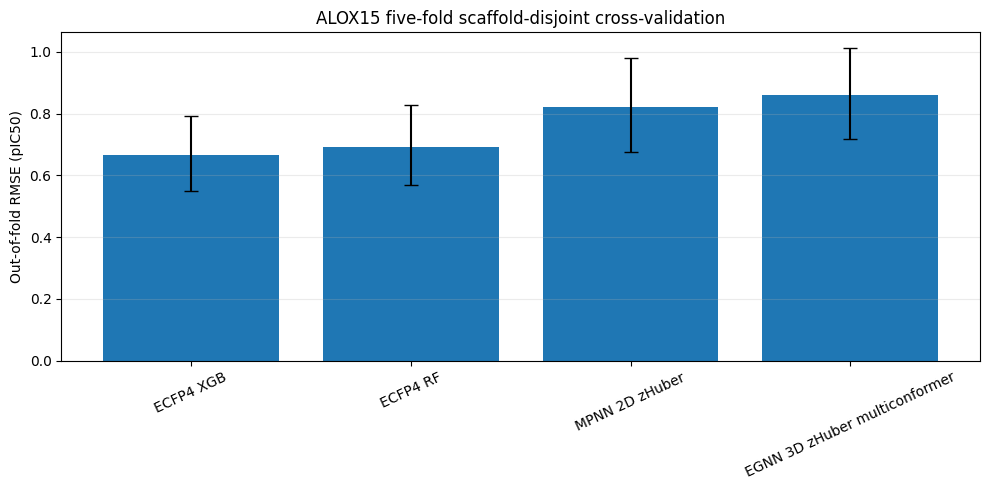


✅ ALOX15 five-fold scaffold cross-validation completed.

Out-of-fold metrics:


,model,molecules,scaffolds,RMSE,MAE,R2,Pearson_r,Spearman_rho
1,ECFP4_XGB,202,82,0.667628,0.490613,0.189608,0.457338,0.383485
0,ECFP4_RF,202,82,0.692600,0.519894,0.127849,0.407030,0.318033
3,MPNN_2D_zHuber,202,82,0.821114,0.648546,-0.225841,-0.092775,-0.100708
2,EGNN_3D_zHuber_multiconformer,202,82,0.861050,0.684067,-0.347980,-0.153419,-0.133988



Scaffold-bootstrap intervals:


,model,molecules,scaffolds,RMSE,MAE,R2,Pearson_r,Spearman_rho,RMSE_ci_2_5,RMSE_ci_97_5,MAE_ci_2_5,MAE_ci_97_5
1,ECFP4_XGB,202,82,0.667628,0.490613,0.189608,0.457338,0.383485,0.550585,0.791177,0.399700,0.600865
0,ECFP4_RF,202,82,0.692600,0.519894,0.127849,0.407030,0.318033,0.570090,0.826780,0.429499,0.627781
3,MPNN_2D_zHuber,202,82,0.821114,0.648546,-0.225841,-0.092775,-0.100708,0.675855,0.981374,0.528222,0.778542
2,EGNN_3D_zHuber_multiconformer,202,82,0.861050,0.684067,-0.347980,-0.153419,-0.133988,0.716449,1.012926,0.576834,0.795444



Mean and standard deviation across folds:


,model,mean_fold_RMSE,std_fold_RMSE,mean_fold_MAE,mean_fold_R2,folds
1,ECFP4_XGB,0.642058,0.169600,0.485771,0.034468,5
0,ECFP4_RF,0.658771,0.203096,0.514507,0.026644,5
3,MPNN_2D_zHuber,0.790984,0.198951,0.639845,-0.432171,5
2,EGNN_3D_zHuber_multiconformer,0.840271,0.161435,0.677571,-0.714980,5



Paired scaffold-bootstrap comparisons:


,reference,proposed,improvement_definition,mean_RMSE_improvement,improvement_ci_2_5,improvement_ci_97_5,probability_proposed_better,paired_molecules,paired_scaffolds
0,ECFP4_RF,MPNN_2D_zHuber,positive favours proposed,-0.126948,-0.217989,-0.034907,0.0012,202,82
1,ECFP4_RF,EGNN_3D_zHuber_multiconformer,positive favours proposed,-0.166722,-0.256568,-0.076441,0.0000,202,82
2,ECFP4_XGB,EGNN_3D_zHuber_multiconformer,positive favours proposed,-0.189753,-0.321435,-0.073344,0.0002,202,82
3,MPNN_2D_zHuber,EGNN_3D_zHuber_multiconformer,positive favours proposed,-0.040492,-0.095390,0.010705,0.0700,202,82


In [41]:
# ============================================================
# ALOX15 FIVE-FOLD SCAFFOLD CROSS-VALIDATION:
# STABILIZED 2D AND 3D NEURAL MODELS
# ============================================================

import gc


CV_NEURAL_SEEDS = (
    13,
    37,
    73,
)

cv_neural_metric_rows = []
cv_neural_prediction_rows = []


for plan in fold_plans:
    fold_number = plan["fold"]

    fold_frame = (
        alo_cv_frame.copy()
    )

    fold_frame["split"] = (
        "unused"
    )

    fold_frame.loc[
        plan["train_indices"],
        "split",
    ] = "train"

    fold_frame.loc[
        plan[
            "validation_indices"
        ],
        "split",
    ] = "val"

    fold_frame.loc[
        plan["test_indices"],
        "split",
    ] = "test"

    assert set(
        fold_frame["split"]
    ) == {
        "train",
        "val",
        "test",
    }

    training_labels = (
        fold_frame.loc[
            fold_frame[
                "split"
            ].eq("train"),
            "label",
        ]
        .astype(float)
        .to_numpy()
    )

    target_mean = float(
        training_labels.mean()
    )

    target_std = float(
        training_labels.std(
            ddof=0
        )
    )

    assert (
        np.isfinite(target_std)
        and target_std > 1e-6
    )

    print()
    print("=" * 72)
    print(
        f"ALOX15 outer fold "
        f"{fold_number}/5"
    )
    print(
        f"Training mean={target_mean:.4f}; "
        f"training SD={target_std:.4f}"
    )
    print("=" * 72)

    molecule_to_scaffold = (
        fold_frame
        .set_index(
            "molecule_id"
        )["scaffold"]
        .to_dict()
    )

    for architecture in (
        "2d",
        "3d",
    ):
        loaders = make_loaders(
            fold_frame,
            architecture=architecture,
        )

        if architecture == "2d":
            canonical_model_name = (
                "MPNN_2D_zHuber"
            )
        else:
            canonical_model_name = (
                "EGNN_3D_zHuber_"
                "multiconformer"
            )

        for seed in CV_NEURAL_SEEDS:
            seed_everything(seed)

            if architecture == "2d":
                model = MPNN2D(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.dropout,
                )

            else:
                model = GeometricMPNN(
                    CONFIG.hidden_dim,
                    CONFIG.num_layers,
                    CONFIG.rbf_dim,
                    CONFIG.dropout,
                    CONFIG.coord_scale,
                )

            run_model_name = (
                f"{canonical_model_name}_"
                f"CVfold{fold_number}"
            )

            (
                trained_model,
                metric_record,
                prediction_frame,
                history_frame,
            ) = train_stabilized_regression_model(
                model=model,
                loaders=loaders,
                task="ALOX15",
                model_name=run_model_name,
                seed=seed,
                target_mean=target_mean,
                target_std=target_std,
            )

            metric_record[
                "canonical_model"
            ] = canonical_model_name

            metric_record[
                "fold"
            ] = fold_number

            cv_neural_metric_rows.append(
                metric_record
            )

            prediction_frame[
                "canonical_model"
            ] = canonical_model_name

            prediction_frame[
                "fold"
            ] = fold_number

            prediction_frame[
                "scaffold"
            ] = (
                prediction_frame[
                    "mol_idx"
                ]
                .map(
                    molecule_to_scaffold
                )
            )

            prediction_frame = (
                prediction_frame.rename(
                    columns={
                        "mol_idx":
                            "molecule_id",
                    }
                )
            )

            cv_neural_prediction_rows.append(
                prediction_frame[
                    [
                        "fold",
                        "canonical_model",
                        "seed",
                        "molecule_id",
                        "scaffold",
                        "y_true",
                        "y_pred",
                    ]
                ]
            )

            # Save progress after every run.
            pd.DataFrame(
                cv_neural_metric_rows
            ).to_csv(
                CV_DIRS["tables"]
                / (
                    "neural_seed_metrics_"
                    "progress.csv"
                ),
                index=False,
            )

            pd.concat(
                cv_neural_prediction_rows,
                ignore_index=True,
            ).to_csv(
                CV_DIRS["tables"]
                / (
                    "neural_seed_predictions_"
                    "progress.csv"
                ),
                index=False,
            )

            print(
                f"fold={fold_number} | "
                f"{canonical_model_name} | "
                f"seed={seed} | "
                f"test RMSE="
                f"{metric_record['RMSE']:.4f}"
            )

            del (
                trained_model,
                model,
                prediction_frame,
                history_frame,
            )

            gc.collect()

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        del loaders
        gc.collect()


cv_neural_metrics = pd.DataFrame(
    cv_neural_metric_rows
)

cv_neural_seed_predictions = (
    pd.concat(
        cv_neural_prediction_rows,
        ignore_index=True,
    )
)

cv_neural_metrics.to_csv(
    CV_DIRS["tables"]
    / "neural_seed_metrics.csv",
    index=False,
)

cv_neural_seed_predictions.to_csv(
    CV_DIRS["tables"]
    / "neural_seed_predictions.csv",
    index=False,
)


# ------------------------------------------------------------
# Average three neural seeds inside each outer fold
# ------------------------------------------------------------

cv_neural_ensemble_predictions = (
    cv_neural_seed_predictions
    .groupby(
        [
            "fold",
            "canonical_model",
            "molecule_id",
            "scaffold",
        ],
        as_index=False,
    )
    .agg(
        y_true=("y_true", "first"),
        y_pred=("y_pred", "mean"),
        seed_sd=("y_pred", "std"),
        number_of_seeds=(
            "seed",
            "nunique",
        ),
    )
)

cv_neural_ensemble_predictions[
    "seed_sd"
] = (
    cv_neural_ensemble_predictions[
        "seed_sd"
    ]
    .fillna(0.0)
)

cv_neural_ensemble_predictions = (
    cv_neural_ensemble_predictions.rename(
        columns={
            "canonical_model":
                "model",
        }
    )
)


# ------------------------------------------------------------
# Combine classical and neural OOF predictions
# ------------------------------------------------------------

cv_all_oof_predictions = pd.concat(
    [
        cv_baseline_predictions[
            [
                "fold",
                "model",
                "molecule_id",
                "scaffold",
                "y_true",
                "y_pred",
            ]
        ],

        cv_neural_ensemble_predictions[
            [
                "fold",
                "model",
                "molecule_id",
                "scaffold",
                "y_true",
                "y_pred",
            ]
        ],
    ],
    ignore_index=True,
)

cv_all_oof_predictions.to_csv(
    CV_DIRS["tables"]
    / "all_model_oof_predictions.csv",
    index=False,
)


# Every molecule must occur exactly once per model.
expected_molecule_count = (
    alo_cv_frame[
        "molecule_id"
    ].nunique()
)

for model_name, frame in (
    cv_all_oof_predictions.groupby(
        "model"
    )
):
    assert (
        frame[
            "molecule_id"
        ].nunique()
        == expected_molecule_count
    )

    assert not frame[
        "molecule_id"
    ].duplicated().any()


# ------------------------------------------------------------
# Aggregate out-of-fold metrics
# ------------------------------------------------------------

oof_metric_rows = []

for model_name, frame in (
    cv_all_oof_predictions.groupby(
        "model"
    )
):
    metrics = regression_metrics(
        frame["y_true"],
        frame["y_pred"],
    )

    oof_metric_rows.append({
        "model": model_name,
        "molecules": int(
            len(frame)
        ),
        "scaffolds": int(
            frame[
                "scaffold"
            ].nunique()
        ),
        **metrics,
    })


cv_oof_metrics = pd.DataFrame(
    oof_metric_rows
)


# ------------------------------------------------------------
# Per-fold metrics
# ------------------------------------------------------------

fold_metric_rows = []

for (
    model_name,
    fold_number,
), frame in cv_all_oof_predictions.groupby(
    [
        "model",
        "fold",
    ]
):
    metrics = regression_metrics(
        frame["y_true"],
        frame["y_pred"],
    )

    fold_metric_rows.append({
        "model": model_name,
        "fold": fold_number,
        "test_molecules": int(
            len(frame)
        ),
        **metrics,
    })


cv_fold_metrics = pd.DataFrame(
    fold_metric_rows
)

cv_fold_summary = (
    cv_fold_metrics
    .groupby(
        "model",
        as_index=False,
    )
    .agg(
        mean_fold_RMSE=(
            "RMSE",
            "mean",
        ),
        std_fold_RMSE=(
            "RMSE",
            "std",
        ),
        mean_fold_MAE=(
            "MAE",
            "mean",
        ),
        mean_fold_R2=(
            "R2",
            "mean",
        ),
        folds=("fold", "nunique"),
    )
)


# ------------------------------------------------------------
# Scaffold-cluster bootstrap
# ------------------------------------------------------------

def scaffold_cluster_bootstrap_metrics(
    frame,
    iterations=5000,
    seed=20260718,
):
    scaffold_values = (
        frame["scaffold"]
        .drop_duplicates()
        .to_numpy()
    )

    groups = {
        scaffold: (
            frame[
                frame[
                    "scaffold"
                ].eq(scaffold)
            ]
        )
        for scaffold in scaffold_values
    }

    rng = np.random.default_rng(
        seed
    )

    bootstrap_rows = []

    for _ in range(iterations):
        sampled_scaffolds = (
            rng.choice(
                scaffold_values,
                size=len(
                    scaffold_values
                ),
                replace=True,
            )
        )

        sampled_frame = pd.concat(
            [
                groups[scaffold]
                for scaffold
                in sampled_scaffolds
            ],
            ignore_index=True,
        )

        bootstrap_rows.append(
            regression_metrics(
                sampled_frame[
                    "y_true"
                ],
                sampled_frame[
                    "y_pred"
                ],
            )
        )

    bootstrap_frame = pd.DataFrame(
        bootstrap_rows
    )

    return {
        "RMSE_ci_2_5": float(
            bootstrap_frame[
                "RMSE"
            ].quantile(0.025)
        ),
        "RMSE_ci_97_5": float(
            bootstrap_frame[
                "RMSE"
            ].quantile(0.975)
        ),
        "MAE_ci_2_5": float(
            bootstrap_frame[
                "MAE"
            ].quantile(0.025)
        ),
        "MAE_ci_97_5": float(
            bootstrap_frame[
                "MAE"
            ].quantile(0.975)
        ),
    }


cv_bootstrap_rows = []

for model_name, frame in (
    cv_all_oof_predictions.groupby(
        "model"
    )
):
    point_metrics = regression_metrics(
        frame["y_true"],
        frame["y_pred"],
    )

    intervals = (
        scaffold_cluster_bootstrap_metrics(
            frame,
            iterations=5000,
            seed=(
                20260718
                + len(
                    cv_bootstrap_rows
                )
            ),
        )
    )

    cv_bootstrap_rows.append({
        "model": model_name,
        "molecules": int(
            len(frame)
        ),
        "scaffolds": int(
            frame[
                "scaffold"
            ].nunique()
        ),
        **point_metrics,
        **intervals,
    })


cv_bootstrap_metrics = pd.DataFrame(
    cv_bootstrap_rows
)


# ------------------------------------------------------------
# Paired scaffold bootstrap
# ------------------------------------------------------------

def paired_scaffold_bootstrap(
    reference_frame,
    proposed_frame,
    iterations=5000,
    seed=20260718,
):
    merged = reference_frame.merge(
        proposed_frame,
        on=[
            "molecule_id",
            "scaffold",
        ],
        suffixes=(
            "_reference",
            "_proposed",
        ),
    )

    assert len(merged) > 0

    assert np.allclose(
        merged["y_true_reference"],
        merged["y_true_proposed"],
    )

    scaffold_values = (
        merged["scaffold"]
        .drop_duplicates()
        .to_numpy()
    )

    groups = {
        scaffold: (
            merged[
                merged[
                    "scaffold"
                ].eq(scaffold)
            ]
        )
        for scaffold in scaffold_values
    }

    rng = np.random.default_rng(
        seed
    )

    improvements = []

    for _ in range(iterations):
        sampled_scaffolds = (
            rng.choice(
                scaffold_values,
                size=len(
                    scaffold_values
                ),
                replace=True,
            )
        )

        sample = pd.concat(
            [
                groups[scaffold]
                for scaffold
                in sampled_scaffolds
            ],
            ignore_index=True,
        )

        reference_rmse = (
            mean_squared_error(
                sample[
                    "y_true_reference"
                ],
                sample[
                    "y_pred_reference"
                ],
            )
            ** 0.5
        )

        proposed_rmse = (
            mean_squared_error(
                sample[
                    "y_true_proposed"
                ],
                sample[
                    "y_pred_proposed"
                ],
            )
            ** 0.5
        )

        improvements.append(
            reference_rmse
            - proposed_rmse
        )

    improvements = np.asarray(
        improvements
    )

    return {
        "mean_RMSE_improvement": float(
            improvements.mean()
        ),
        "improvement_ci_2_5": float(
            np.quantile(
                improvements,
                0.025,
            )
        ),
        "improvement_ci_97_5": float(
            np.quantile(
                improvements,
                0.975,
            )
        ),
        "probability_proposed_better": float(
            np.mean(
                improvements > 0
            )
        ),
        "paired_molecules": int(
            len(merged)
        ),
        "paired_scaffolds": int(
            len(
                scaffold_values
            )
        ),
    }


cv_comparison_pairs = [
    (
        "ECFP4_RF",
        "MPNN_2D_zHuber",
    ),
    (
        "ECFP4_RF",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
    (
        "ECFP4_XGB",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
    (
        "MPNN_2D_zHuber",
        (
            "EGNN_3D_zHuber_"
            "multiconformer"
        ),
    ),
]

cv_paired_rows = []

for (
    reference_name,
    proposed_name,
) in cv_comparison_pairs:
    reference = (
        cv_all_oof_predictions[
            cv_all_oof_predictions[
                "model"
            ].eq(reference_name)
        ]
    )

    proposed = (
        cv_all_oof_predictions[
            cv_all_oof_predictions[
                "model"
            ].eq(proposed_name)
        ]
    )

    result = paired_scaffold_bootstrap(
        reference,
        proposed,
        iterations=5000,
        seed=(
            20260718
            + len(cv_paired_rows)
        ),
    )

    cv_paired_rows.append({
        "reference": reference_name,
        "proposed": proposed_name,
        "improvement_definition": (
            "positive favours proposed"
        ),
        **result,
    })


cv_paired_comparisons = (
    pd.DataFrame(
        cv_paired_rows
    )
)


# ------------------------------------------------------------
# Save all results
# ------------------------------------------------------------

cv_neural_ensemble_predictions.to_csv(
    CV_DIRS["tables"]
    / (
        "neural_ensemble_"
        "oof_predictions.csv"
    ),
    index=False,
)

cv_oof_metrics.to_csv(
    CV_DIRS["tables"]
    / "oof_metrics.csv",
    index=False,
)

cv_fold_metrics.to_csv(
    CV_DIRS["tables"]
    / "fold_metrics.csv",
    index=False,
)

cv_fold_summary.to_csv(
    CV_DIRS["tables"]
    / "fold_summary.csv",
    index=False,
)

cv_bootstrap_metrics.to_csv(
    CV_DIRS["tables"]
    / "scaffold_bootstrap_metrics.csv",
    index=False,
)

cv_paired_comparisons.to_csv(
    CV_DIRS["tables"]
    / (
        "paired_scaffold_"
        "bootstrap_comparisons.csv"
    ),
    index=False,
)


# ------------------------------------------------------------
# Main cross-validation figure
# ------------------------------------------------------------

plot_frame = (
    cv_bootstrap_metrics
    .sort_values("RMSE")
    .reset_index(drop=True)
)

values = (
    plot_frame[
        "RMSE"
    ].to_numpy()
)

lower_error = (
    values
    - plot_frame[
        "RMSE_ci_2_5"
    ].to_numpy()
)

upper_error = (
    plot_frame[
        "RMSE_ci_97_5"
    ].to_numpy()
    - values
)

figure, axis = plt.subplots(
    figsize=(10, 5)
)

axis.bar(
    plot_frame[
        "model"
    ].str.replace(
        "_",
        " ",
        regex=False,
    ),
    values,
    yerr=np.vstack(
        [
            lower_error,
            upper_error,
        ]
    ),
    capsize=5,
)

axis.set_ylabel(
    "Out-of-fold RMSE (pIC50)"
)

axis.set_title(
    (
        "ALOX15 five-fold scaffold-"
        "disjoint cross-validation"
    )
)

axis.tick_params(
    axis="x",
    rotation=25,
)

axis.grid(
    axis="y",
    alpha=0.25,
)

figure.tight_layout()

figure.savefig(
    CV_DIRS["figures"]
    / (
        "ALOX15_five_fold_"
        "scaffold_CV.png"
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


# ------------------------------------------------------------
# Final validation
# ------------------------------------------------------------

assert (
    cv_neural_metrics
    .groupby(
        [
            "fold",
            "canonical_model",
        ]
    )["seed"]
    .nunique()
    .eq(
        len(CV_NEURAL_SEEDS)
    )
    .all()
)

assert (
    cv_fold_summary[
        "folds"
    ]
    .eq(5)
    .all()
)

assert np.isfinite(
    cv_bootstrap_metrics[
        [
            "RMSE",
            "MAE",
            "R2",
        ]
    ].to_numpy()
).all()

assert (
    cv_bootstrap_metrics[
        "RMSE_ci_2_5"
    ]
    <= cv_bootstrap_metrics[
        "RMSE"
    ]
).all()

assert (
    cv_bootstrap_metrics[
        "RMSE"
    ]
    <= cv_bootstrap_metrics[
        "RMSE_ci_97_5"
    ]
).all()


print()
print(
    "✅ ALOX15 five-fold scaffold "
    "cross-validation completed."
)

print(
    "\nOut-of-fold metrics:"
)
display(
    cv_oof_metrics.sort_values(
        "RMSE"
    )
)

print(
    "\nScaffold-bootstrap intervals:"
)
display(
    cv_bootstrap_metrics.sort_values(
        "RMSE"
    )
)

print(
    "\nMean and standard deviation across folds:"
)
display(
    cv_fold_summary.sort_values(
        "mean_fold_RMSE"
    )
)

print(
    "\nPaired scaffold-bootstrap comparisons:"
)
display(
    cv_paired_comparisons
)

In [42]:
# ============================================================
# FINAL EVIDENCE-BASED CANDIDATE SCREENING
#
# Primary ranking models:
#   ALOX15 -> five-fold ECFP4-XGBoost ensemble
#   COX2   -> full-data ECFP4-Random-Forest ensemble
#   ARE    -> full-data ECFP4-XGBoost ensemble
#
# Strict EGNN predictions are retained as secondary
# model-disagreement and uncertainty evidence.
# ============================================================

from pathlib import Path
import gc
import hashlib
import json

import joblib
import numpy as np
import pandas as pd
import torch
import xgboost as xgb

from sklearn.ensemble import RandomForestRegressor
from torch_geometric.loader import DataLoader
from rdkit import DataStructs
from tqdm.auto import tqdm
from IPython.display import display


FINAL_ROOT = STRICT_ROOT / "final_submission"

FINAL_DIRS = {
    "tables": FINAL_ROOT / "tables",
    "figures": FINAL_ROOT / "figures",
    "models": FINAL_ROOT / "models",
    "logs": FINAL_ROOT / "logs",
}

for directory in FINAL_DIRS.values():
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# Recover candidate table
# ------------------------------------------------------------

if (
    "candidates" not in globals()
    or candidates.empty
):
    candidate_paths = [
        BROAD_DIRS["processed"]
        / "candidate_metabolites_standardized.csv",

        BROAD_DIRS["input"]
        / "candidate_metabolites.csv",
    ]

    loaded_candidates = None

    for candidate_path in candidate_paths:
        if candidate_path.exists():
            loaded_candidates = pd.read_csv(
                candidate_path
            )
            break

    if loaded_candidates is None:
        raise FileNotFoundError(
            "The candidate-metabolite table could not be recovered."
        )

    if "standard_smiles" not in loaded_candidates.columns:
        standardized_rows = []

        for _, row in loaded_candidates.iterrows():
            result = standardize_smiles(
                row["smiles"]
            )

            if result:
                standardized_rows.append({
                    **row.to_dict(),
                    **result,
                })

        candidates = pd.DataFrame(
            standardized_rows
        )

    else:
        candidates = loaded_candidates.copy()


required_candidate_columns = {
    "compound_name",
    "standard_smiles",
    "reported_species",
    "source_citation",
    "provenance_tier",
}

missing_columns = (
    required_candidate_columns
    - set(candidates.columns)
)

assert not missing_columns, (
    f"Candidate columns missing: {missing_columns}"
)

candidates = (
    candidates
    .drop_duplicates(
        "standard_smiles"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Candidate ECFP matrix
# ------------------------------------------------------------

candidate_ecfp, candidate_valid = ecfp_matrix(
    candidates[
        "standard_smiles"
    ].tolist()
)

assert candidate_valid.all(), (
    "At least one candidate failed ECFP generation."
)


# ------------------------------------------------------------
# ALOX15:
# reuse the five outer-fold XGBoost models
# ------------------------------------------------------------

alox15_xgb_models = []

for fold_number in range(1, 6):
    model_path = (
        CV_DIRS["models"]
        / (
            "ALOX15_ECFP4_XGB_"
            f"fold{fold_number}.joblib"
        )
    )

    assert model_path.exists(), (
        f"Missing ALOX15 CV model: {model_path}"
    )

    alox15_xgb_models.append(
        joblib.load(model_path)
    )


alox15_prediction_matrix = np.vstack([
    model.predict(candidate_ecfp)
    for model in alox15_xgb_models
])


# ------------------------------------------------------------
# COX2:
# train final RF ensemble on all strict records
#
# Performance was estimated before this refit using the
# locked strict test split.
# ------------------------------------------------------------

cox2_frame = (
    strict_curated[
        strict_curated["task"].eq(
            "COX2"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

cox2_ecfp, cox2_valid = ecfp_matrix(
    cox2_frame[
        "standard_smiles"
    ].tolist()
)

assert cox2_valid.all()

cox2_targets = (
    cox2_frame["label"]
    .astype(float)
    .to_numpy()
)

final_model_seeds = (
    13,
    37,
    73,
    101,
    151,
)

cox2_rf_models = []
cox2_prediction_rows = []

for seed in final_model_seeds:
    model = RandomForestRegressor(
        n_estimators=800,
        max_features="sqrt",
        min_samples_leaf=1,
        n_jobs=CONFIG.graph_jobs,
        random_state=seed,
    )

    model.fit(
        cox2_ecfp,
        cox2_targets,
    )

    model_path = (
        FINAL_DIRS["models"]
        / f"COX2_final_RF_seed{seed}.joblib"
    )

    joblib.dump(
        model,
        model_path,
    )

    cox2_rf_models.append(model)

    cox2_prediction_rows.append(
        model.predict(candidate_ecfp)
    )


cox2_prediction_matrix = np.vstack(
    cox2_prediction_rows
)


# ------------------------------------------------------------
# ARE:
# train final XGBoost ensemble on the complete Tox21 set
# ------------------------------------------------------------

are_frame = (
    strict_curated[
        strict_curated["task"].eq(
            "ARE"
        )
    ]
    .copy()
    .reset_index(drop=True)
)

are_ecfp, are_valid = ecfp_matrix(
    are_frame[
        "standard_smiles"
    ].tolist()
)

assert are_valid.all()

are_targets = (
    are_frame["label"]
    .astype(int)
    .to_numpy()
)

positive_count = max(
    1,
    int(are_targets.sum()),
)

negative_count = max(
    1,
    int(
        len(are_targets)
        - positive_count
    ),
)

are_xgb_models = []
are_prediction_rows = []

for seed in final_model_seeds:
    model = xgb.XGBClassifier(
        n_estimators=800,
        max_depth=6,
        learning_rate=0.04,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        scale_pos_weight=(
            negative_count
            / positive_count
        ),
        n_jobs=CONFIG.graph_jobs,
        random_state=seed,
    )

    model.fit(
        are_ecfp,
        are_targets,
    )

    model_path = (
        FINAL_DIRS["models"]
        / f"ARE_final_XGB_seed{seed}.joblib"
    )

    joblib.dump(
        model,
        model_path,
    )

    are_xgb_models.append(model)

    are_prediction_rows.append(
        model.predict_proba(
            candidate_ecfp
        )[:, 1]
    )


are_prediction_matrix = np.vstack(
    are_prediction_rows
)


# ------------------------------------------------------------
# Strict EGNN predictions for comparison
# ------------------------------------------------------------

def load_stabilized_egnn(
    task,
    seed,
):
    checkpoint_path = (
        STRICT_DIRS["models"]
        / (
            f"{task}_"
            "EGNN_3D_zHuber_"
            "multiconformer_"
            f"seed{seed}.pt"
        )
    )

    assert checkpoint_path.exists(), (
        f"Missing EGNN checkpoint: {checkpoint_path}"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    model = GeometricMPNN(
        CONFIG.hidden_dim,
        CONFIG.num_layers,
        CONFIG.rbf_dim,
        CONFIG.dropout,
        CONFIG.coord_scale,
    )

    model.load_state_dict(
        checkpoint["state_dict"]
    )

    model = (
        model
        .eval()
        .to(DEVICE)
    )

    return (
        model,
        float(checkpoint["target_mean"]),
        float(checkpoint["target_std"]),
    )


egnn_resources = {
    task: [
        load_stabilized_egnn(
            task,
            seed,
        )
        for seed in CONFIG.seeds
    ]
    for task in (
        "ALOX15",
        "COX2",
    )
}


def candidate_egnn_predictions(
    standard_smiles,
    candidate_index,
):
    graph_seed = (
        CONFIG.base_seed
        + int(
            hashlib.sha256(
                standard_smiles.encode()
            ).hexdigest()[:8],
            16,
        )
    )

    graphs = generate_graphs(
        standard_smiles,
        graph_seed,
    )

    if not graphs:
        return None

    for graph in graphs:
        graph.mol_idx = torch.tensor(
            [candidate_index],
            dtype=torch.long,
        )

    loader = DataLoader(
        graphs,
        batch_size=len(graphs),
        shuffle=False,
    )

    batch = next(
        iter(loader)
    ).to(
        DEVICE,
        non_blocking=True,
    )

    task_outputs = {}

    for task, resources in (
        egnn_resources.items()
    ):
        seed_conformer_predictions = []

        for (
            model,
            target_mean,
            target_std,
        ) in resources:
            with (
                torch.no_grad(),
                autocast_context(),
            ):
                normalized_output = (
                    model(batch)
                    .view(-1)
                    .float()
                )

            denormalized_output = (
                normalized_output
                * target_std
                + target_mean
            )

            seed_conformer_predictions.append(
                denormalized_output
                .detach()
                .cpu()
                .numpy()
            )

        matrix = np.vstack(
            seed_conformer_predictions
        )

        task_outputs[task] = {
            "mean": float(
                matrix.mean()
            ),

            "model_sd": float(
                matrix
                .mean(axis=1)
                .std(ddof=1)
            ),

            "conformer_sd": (
                float(
                    matrix
                    .mean(axis=0)
                    .std(ddof=1)
                )
                if matrix.shape[1] > 1
                else 0.0
            ),

            "n_conformers":
                int(matrix.shape[1]),
        }

    return task_outputs


egnn_candidate_outputs = []

for candidate_index, row in tqdm(
    candidates.iterrows(),
    total=len(candidates),
    desc="Strict EGNN candidate inference",
):
    output = candidate_egnn_predictions(
        row["standard_smiles"],
        candidate_index,
    )

    egnn_candidate_outputs.append(
        output
    )


# ------------------------------------------------------------
# Applicability-domain similarity
# ------------------------------------------------------------

task_training_fingerprints = {}

for task in (
    "ALOX15",
    "COX2",
    "ARE",
):
    fingerprints = []

    for smiles in (
        strict_curated.loc[
            strict_curated[
                "task"
            ].eq(task),
            "standard_smiles",
        ]
        .drop_duplicates()
    ):
        fingerprint = rdkit_fp(
            smiles
        )

        if fingerprint is not None:
            fingerprints.append(
                fingerprint
            )

    task_training_fingerprints[
        task
    ] = fingerprints


candidate_rows = []

for candidate_index, row in (
    candidates.iterrows()
):
    record = row.to_dict()

    # Selected-model predictions
    record[
        "ALOX15_selected_prediction_pIC50"
    ] = float(
        alox15_prediction_matrix[
            :,
            candidate_index,
        ].mean()
    )

    record[
        "ALOX15_selected_model_sd"
    ] = float(
        alox15_prediction_matrix[
            :,
            candidate_index,
        ].std(ddof=1)
    )

    record[
        "COX2_selected_prediction_pIC50"
    ] = float(
        cox2_prediction_matrix[
            :,
            candidate_index,
        ].mean()
    )

    record[
        "COX2_selected_model_sd"
    ] = float(
        cox2_prediction_matrix[
            :,
            candidate_index,
        ].std(ddof=1)
    )

    record[
        "ARE_selected_probability"
    ] = float(
        are_prediction_matrix[
            :,
            candidate_index,
        ].mean()
    )

    record[
        "ARE_selected_model_sd"
    ] = float(
        are_prediction_matrix[
            :,
            candidate_index,
        ].std(ddof=1)
    )

    egnn_output = (
        egnn_candidate_outputs[
            candidate_index
        ]
    )

    if egnn_output is not None:
        for task in (
            "ALOX15",
            "COX2",
        ):
            record[
                f"{task}_EGNN_prediction_pIC50"
            ] = egnn_output[
                task
            ]["mean"]

            record[
                f"{task}_EGNN_model_sd"
            ] = egnn_output[
                task
            ]["model_sd"]

            record[
                f"{task}_EGNN_conformer_sd"
            ] = egnn_output[
                task
            ]["conformer_sd"]

            record[
                f"{task}_EGNN_n_conformers"
            ] = egnn_output[
                task
            ]["n_conformers"]

    candidate_fingerprint = rdkit_fp(
        row["standard_smiles"]
    )

    for task in (
        "ALOX15",
        "COX2",
        "ARE",
    ):
        training_fingerprints = (
            task_training_fingerprints[
                task
            ]
        )

        similarity = (
            max(
                DataStructs
                .BulkTanimotoSimilarity(
                    candidate_fingerprint,
                    training_fingerprints,
                )
            )
            if (
                candidate_fingerprint
                is not None
                and training_fingerprints
            )
            else 0.0
        )

        record[
            f"{task}_max_training_Tanimoto"
        ] = float(similarity)

        # Conservative, explicitly reported heuristic.
        record[
            f"{task}_inside_similarity_domain_0_35"
        ] = bool(
            similarity >= 0.35
        )

    record[
        "ALOX15_model_disagreement"
    ] = abs(
        record[
            "ALOX15_selected_prediction_pIC50"
        ]
        - record.get(
            "ALOX15_EGNN_prediction_pIC50",
            np.nan,
        )
    )

    record[
        "COX2_model_disagreement"
    ] = abs(
        record[
            "COX2_selected_prediction_pIC50"
        ]
        - record.get(
            "COX2_EGNN_prediction_pIC50",
            np.nan,
        )
    )

    candidate_rows.append(record)


final_candidate_predictions = pd.DataFrame(
    candidate_rows
)


# ------------------------------------------------------------
# Transparent exploratory ranking
# ------------------------------------------------------------

ranking_columns = {
    "ALOX15":
        "ALOX15_selected_prediction_pIC50",

    "COX2":
        "COX2_selected_prediction_pIC50",

    "ARE":
        "ARE_selected_probability",
}

for endpoint, column in ranking_columns.items():
    final_candidate_predictions[
        f"{endpoint}_candidate_percentile"
    ] = (
        final_candidate_predictions[
            column
        ]
        .rank(
            pct=True,
            method="average",
        )
    )


final_candidate_predictions[
    "exploratory_consensus_score"
] = (
    final_candidate_predictions[
        [
            "ALOX15_candidate_percentile",
            "COX2_candidate_percentile",
            "ARE_candidate_percentile",
        ]
    ]
    .mean(axis=1)
)


final_candidate_predictions[
    "all_three_inside_similarity_domain"
] = (
    final_candidate_predictions[
        [
            "ALOX15_inside_similarity_domain_0_35",
            "COX2_inside_similarity_domain_0_35",
            "ARE_inside_similarity_domain_0_35",
        ]
    ]
    .all(axis=1)
)


final_candidate_predictions = (
    final_candidate_predictions
    .sort_values(
        [
            "exploratory_consensus_score",
            "all_three_inside_similarity_domain",
        ],
        ascending=[
            False,
            False,
        ],
    )
    .reset_index(drop=True)
)

final_candidate_predictions[
    "exploratory_rank"
] = np.arange(
    1,
    len(
        final_candidate_predictions
    ) + 1,
)


assert np.isfinite(
    final_candidate_predictions[
        [
            "ALOX15_selected_prediction_pIC50",
            "COX2_selected_prediction_pIC50",
            "ARE_selected_probability",
            "exploratory_consensus_score",
        ]
    ].to_numpy()
).all()

assert {
    "source_citation",
    "provenance_tier",
    "reported_species",
}.issubset(
    final_candidate_predictions.columns
)


final_candidate_predictions.to_csv(
    FINAL_DIRS["tables"]
    / (
        "final_candidate_predictions_"
        "selected_models.csv"
    ),
    index=False,
)


model_selection_table = pd.DataFrame([
    {
        "endpoint": "ALOX15",
        "selected_model":
            "ECFP4-XGBoost five-fold ensemble",
        "selection_evidence":
            (
                "Lowest five-fold scaffold-disjoint "
                "out-of-fold RMSE"
            ),
        "primary_metric": "RMSE",
        "estimated_value": float(
            cv_oof_metrics.loc[
                cv_oof_metrics[
                    "model"
                ].eq("ECFP4_XGB"),
                "RMSE",
            ].iloc[0]
        ),
    },
    {
        "endpoint": "COX2",
        "selected_model":
            "ECFP4-Random-Forest ensemble",
        "selection_evidence":
            (
                "Lowest strict locked-test RMSE"
            ),
        "primary_metric": "RMSE",
        "estimated_value": float(
            fixed_ensemble_metrics.loc[
                (
                    fixed_ensemble_metrics[
                        "task"
                    ].eq("COX2")
                )
                & (
                    fixed_ensemble_metrics[
                        "model"
                    ].eq("ECFP4_RF")
                ),
                "RMSE",
            ].iloc[0]
        ),
    },
    {
        "endpoint": "ARE",
        "selected_model":
            "ECFP4-XGBoost ensemble",
        "selection_evidence":
            (
                "Highest broad locked-test PR-AUC "
                "among prespecified baselines"
            ),
        "primary_metric": "PR-AUC",
        "estimated_value": float(
            baseline_results.loc[
                (
                    baseline_results[
                        "task"
                    ].eq("ARE")
                )
                & (
                    baseline_results[
                        "model"
                    ].eq("ECFP4_XGB")
                ),
                "PR_AUC",
            ].iloc[0]
        ),
    },
])

model_selection_table.to_csv(
    FINAL_DIRS["tables"]
    / "final_model_selection.csv",
    index=False,
)


print(
    "✅ Final evidence-based candidate "
    "screening completed."
)

display(model_selection_table)

display(
    final_candidate_predictions[
        [
            "exploratory_rank",
            "compound_name",
            "reported_species",
            "ALOX15_selected_prediction_pIC50",
            "COX2_selected_prediction_pIC50",
            "ARE_selected_probability",
            "ALOX15_max_training_Tanimoto",
            "COX2_max_training_Tanimoto",
            "ARE_max_training_Tanimoto",
            "exploratory_consensus_score",
        ]
    ]
)

Strict EGNN candidate inference:   0%|          | 0/8 [00:00<?, ?it/s]

✅ Final evidence-based candidate screening completed.


,endpoint,selected_model,selection_evidence,primary_metric,estimated_value
0,ALOX15,ECFP4-XGBoost five-fold ensemble,Lowest five-fold scaffold-disjoint out-of-fold...,RMSE,0.667628
1,COX2,ECFP4-Random-Forest ensemble,Lowest strict locked-test RMSE,RMSE,0.940178
2,ARE,ECFP4-XGBoost ensemble,Highest broad locked-test PR-AUC among prespec...,PR-AUC,0.295215


,exploratory_rank,compound_name,reported_species,ALOX15_selected_prediction_pIC50,COX2_selected_prediction_pIC50,ARE_selected_probability,ALOX15_max_training_Tanimoto,COX2_max_training_Tanimoto,ARE_max_training_Tanimoto,exploratory_consensus_score
0,1,Quercetin,Lilium lancifolium,5.331795,5.796782,0.890849,0.595238,0.434783,1.000000,0.833333
1,2,Myricetin,Lilium lancifolium,5.296134,5.789659,0.877274,0.454545,0.431818,0.756757,0.666667
2,3,Kaempferol,Lilium lancifolium,5.152572,5.885274,0.851340,0.477273,0.454545,1.000000,0.625000
3,4,Caffeic acid,Lilium lancifolium,5.555333,5.296974,0.501324,0.277778,0.535714,1.000000,0.583333
4,5,Ferulic acid,Lilium lancifolium,5.466610,5.487689,0.368216,0.295455,0.478261,0.647059,0.541667
5,6,p-Coumaric acid,Lilium lancifolium,5.419466,5.402078,0.374802,0.307692,0.481481,0.809524,0.500000
6,7,Gallic acid,Lilium lancifolium,5.318330,5.161736,0.751192,0.214286,0.640000,1.000000,0.458333
7,8,Protocatechualdehyde,Lilium lancifolium,5.248446,4.964652,0.575268,0.322581,1.000000,0.571429,0.291667


In [43]:
# ============================================================
# FINAL SUBMISSION HANDOFF
# ============================================================

from pathlib import Path
import hashlib
import json
import zipfile

import numpy as np
import pandas as pd
from IPython.display import display, FileLink


# ------------------------------------------------------------
# Manuscript-ready numerical summary
# ------------------------------------------------------------

alox_cv_results = (
    cv_bootstrap_metrics
    .copy()
    .sort_values("RMSE")
)

best_alox_model = (
    alox_cv_results.iloc[0]
)

alox_3d_result = (
    alox_cv_results[
        alox_cv_results[
            "model"
        ].eq(
            "EGNN_3D_zHuber_multiconformer"
        )
    ]
    .iloc[0]
)

alox_3d_vs_xgb = (
    cv_paired_comparisons[
        (
            cv_paired_comparisons[
                "reference"
            ].eq("ECFP4_XGB")
        )
        & (
            cv_paired_comparisons[
                "proposed"
            ].eq(
                "EGNN_3D_zHuber_multiconformer"
            )
        )
    ]
    .iloc[0]
)

cox2_fixed_results = (
    fixed_ensemble_metrics[
        fixed_ensemble_metrics[
            "task"
        ].eq("COX2")
    ]
    .sort_values("RMSE")
)

manuscript_summary = {
    "study_status":
        "submission-ready computational experiment",

    "central_result": (
        "Ligand-only 3D geometric learning did not "
        "outperform ECFP4 models under ALOX15 "
        "five-fold scaffold-disjoint validation."
    ),

    "interpretation": (
        "The predictive value of three-dimensional "
        "geometry was endpoint-dependent rather than "
        "universally superior."
    ),

    "ALOX15_molecules":
        int(best_alox_model["molecules"]),

    "ALOX15_scaffolds":
        int(best_alox_model["scaffolds"]),

    "ALOX15_best_model":
        str(best_alox_model["model"]),

    "ALOX15_best_RMSE":
        float(best_alox_model["RMSE"]),

    "ALOX15_best_RMSE_CI": [
        float(
            best_alox_model[
                "RMSE_ci_2_5"
            ]
        ),
        float(
            best_alox_model[
                "RMSE_ci_97_5"
            ]
        ),
    ],

    "ALOX15_3D_RMSE":
        float(alox_3d_result["RMSE"]),

    "ALOX15_3D_RMSE_CI": [
        float(
            alox_3d_result[
                "RMSE_ci_2_5"
            ]
        ),
        float(
            alox_3d_result[
                "RMSE_ci_97_5"
            ]
        ),
    ],

    "ALOX15_3D_vs_XGB_mean_improvement": (
        float(
            alox_3d_vs_xgb[
                "mean_RMSE_improvement"
            ]
        )
    ),

    "ALOX15_3D_vs_XGB_CI": [
        float(
            alox_3d_vs_xgb[
                "improvement_ci_2_5"
            ]
        ),
        float(
            alox_3d_vs_xgb[
                "improvement_ci_97_5"
            ]
        ),
    ],

    "COX2_locked_test_models":
        cox2_fixed_results[
            [
                "model",
                "RMSE",
                "MAE",
                "R2",
            ]
        ].to_dict(
            orient="records"
        ),

    "candidate_count":
        int(
            len(
                final_candidate_predictions
            )
        ),

    "candidate_scope": (
        "Literature-reported metabolites from other "
        "Lilium species; not chemically confirmed in "
        "Lilium mackliniae."
    ),

    "prohibited_claims": [
        (
            "Do not claim that the 3D EGNN "
            "outperformed ECFP4."
        ),
        (
            "Do not describe screened compounds as "
            "confirmed Lilium mackliniae metabolites."
        ),
        (
            "Do not describe predictions as "
            "experimental therapeutic activity."
        ),
    ],
}


summary_path = (
    FINAL_ROOT
    / "manuscript_results_summary.json"
)

summary_path.write_text(
    json.dumps(
        manuscript_summary,
        indent=2,
    ),
    encoding="utf-8",
)


# ------------------------------------------------------------
# Final validation gates
# ------------------------------------------------------------

validation_checks = []


def add_check(
    name,
    condition,
    detail="",
):
    validation_checks.append({
        "check": name,
        "passed": bool(condition),
        "detail": detail,
    })


add_check(
    "Five ALOX15 outer folds completed",
    cv_fold_summary["folds"].eq(5).all(),
)

add_check(
    "Every ALOX15 molecule tested once per model",
    all(
        (
            frame["molecule_id"].nunique()
            == len(alo_cv_frame)
        )
        and not frame[
            "molecule_id"
        ].duplicated().any()
        for _, frame
        in cv_all_oof_predictions.groupby(
            "model"
        )
    ),
)

add_check(
    "ALOX15 scaffold leakage absent",
    (
        outer_test_assignments
        .groupby("scaffold")["fold"]
        .nunique()
        .max()
        == 1
    ),
)

add_check(
    "Scaffold-bootstrap intervals generated",
    (
        cv_bootstrap_metrics[
            "RMSE_ci_2_5"
        ]
        <= cv_bootstrap_metrics[
            "RMSE"
        ]
    ).all()
    and (
        cv_bootstrap_metrics[
            "RMSE"
        ]
        <= cv_bootstrap_metrics[
            "RMSE_ci_97_5"
        ]
    ).all(),
)

add_check(
    "Final model selection documented",
    len(model_selection_table) == 3,
)

add_check(
    "Candidate predictions finite",
    np.isfinite(
        final_candidate_predictions[
            [
                "ALOX15_selected_prediction_pIC50",
                "COX2_selected_prediction_pIC50",
                "ARE_selected_probability",
            ]
        ].to_numpy()
    ).all(),
)

add_check(
    "Candidate provenance retained",
    {
        "reported_species",
        "source_citation",
        "provenance_tier",
    }.issubset(
        final_candidate_predictions.columns
    ),
)

add_check(
    "Applicability-domain similarity retained",
    all(
        (
            f"{task}_max_training_Tanimoto"
            in final_candidate_predictions.columns
        )
        for task in (
            "ALOX15",
            "COX2",
            "ARE",
        )
    ),
)

add_check(
    "Species-specific overclaim prevented",
    not final_candidate_predictions[
        "provenance_tier"
    ]
    .astype(str)
    .str.contains(
        "MACKLINIAE_CONFIRMED",
        case=False,
        na=False,
    )
    .any(),
)

add_check(
    "Central claim matches CV evidence",
    (
        float(
            alox_3d_vs_xgb[
                "improvement_ci_97_5"
            ]
        )
        < 0
    ),
    (
        "Upper confidence bound is below zero; "
        "3D is significantly worse than XGBoost "
        "under the defined improvement direction."
    ),
)


final_validation_report = pd.DataFrame(
    validation_checks
)

final_validation_report.to_csv(
    FINAL_DIRS["tables"]
    / "final_submission_validation.csv",
    index=False,
)

display(final_validation_report)

assert final_validation_report[
    "passed"
].all(), (
    "At least one final submission "
    "validation gate failed."
)


# ------------------------------------------------------------
# Plain-language paper status
# ------------------------------------------------------------

readiness_text = f"""
# Siroi Lily Digital Bioprospecting: Submission Status

## Overall status

The computational experiments are complete and suitable for manuscript
preparation.

## Primary ALOX15 result

Five-fold scaffold-disjoint cross-validation included
{int(best_alox_model['molecules'])} molecules and
{int(best_alox_model['scaffolds'])} scaffolds.

The strongest model was {best_alox_model['model']} with an out-of-fold
RMSE of {best_alox_model['RMSE']:.3f}
(95% scaffold-bootstrap CI
{best_alox_model['RMSE_ci_2_5']:.3f}–{best_alox_model['RMSE_ci_97_5']:.3f}).

The multi-conformer EGNN achieved an RMSE of
{alox_3d_result['RMSE']:.3f}
(95% CI
{alox_3d_result['RMSE_ci_2_5']:.3f}–{alox_3d_result['RMSE_ci_97_5']:.3f}).

Relative to ECFP4-XGBoost, the EGNN RMSE improvement was
{alox_3d_vs_xgb['mean_RMSE_improvement']:.3f}
(95% CI
{alox_3d_vs_xgb['improvement_ci_2_5']:.3f} to
{alox_3d_vs_xgb['improvement_ci_97_5']:.3f}),
where positive values would favour the EGNN.

## Defensible conclusion

Three-dimensional geometric learning was not universally superior to
molecular fingerprints. ECFP4 models generalized better on the strict
ALOX15 scaffold-disjoint benchmark. The COX-2 results indicate that
geometric utility may be endpoint-dependent.

## Candidate limitation

The screened compounds were reported in other Lilium species. They are
not confirmed constituents of Lilium mackliniae and must be described as
transferable, literature-supported candidates only.
""".strip()


readiness_path = (
    FINAL_ROOT
    / "SUBMISSION_READINESS.md"
)

readiness_path.write_text(
    readiness_text,
    encoding="utf-8",
)


# ------------------------------------------------------------
# Build compact handoff
# ------------------------------------------------------------

HANDOFF_DIRECTORY = Path(
    "/content/sirolily_final_handoff"
)

HANDOFF_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_ZIP = (
    HANDOFF_DIRECTORY
    / (
        "Siroi_Lily_Final_"
        "Submission_Handoff.zip"
    )
)


selected_files = []


def add_directory_files(
    directory,
    extensions,
):
    if not directory.exists():
        return

    for path in directory.rglob("*"):
        if (
            path.is_file()
            and path.suffix.lower()
            in extensions
        ):
            selected_files.append(path)


compact_extensions = {
    ".csv",
    ".json",
    ".md",
    ".txt",
    ".png",
    ".svg",
    ".pdf",
    ".yaml",
    ".yml",
}


# Original broad experiment: tables and figures only
add_directory_files(
    BROAD_DIRS["tables"],
    compact_extensions,
)

add_directory_files(
    BROAD_DIRS["figures"],
    compact_extensions,
)

# Strict sensitivity analysis
add_directory_files(
    STRICT_DIRS["tables"],
    compact_extensions,
)

add_directory_files(
    STRICT_DIRS["figures"],
    compact_extensions,
)

add_directory_files(
    STRICT_DIRS["logs"],
    compact_extensions,
)

add_directory_files(
    STRICT_DIRS["splits"],
    compact_extensions,
)

add_directory_files(
    STRICT_DIRS["processed"],
    compact_extensions,
)

# ALOX15 scaffold cross-validation
add_directory_files(
    CV_DIRS["tables"],
    compact_extensions,
)

add_directory_files(
    CV_DIRS["figures"],
    compact_extensions,
)

add_directory_files(
    CV_DIRS["logs"],
    compact_extensions,
)

add_directory_files(
    CV_DIRS["splits"],
    compact_extensions,
)

# Final candidate analysis
add_directory_files(
    FINAL_DIRS["tables"],
    compact_extensions,
)

add_directory_files(
    FINAL_DIRS["figures"],
    compact_extensions,
)

selected_files.extend([
    summary_path,
    readiness_path,
])


# Deduplicate resolved paths
selected_files = sorted({
    path.resolve()
    for path in selected_files
    if path.exists()
})


# ------------------------------------------------------------
# SHA-256 file manifest
# ------------------------------------------------------------

def calculate_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


manifest_rows = []

for path in selected_files:
    manifest_rows.append({
        "absolute_source_path":
            str(path),

        "filename":
            path.name,

        "bytes":
            int(path.stat().st_size),

        "sha256":
            calculate_sha256(path),
    })


manifest_path = (
    FINAL_ROOT
    / "final_handoff_manifest_sha256.csv"
)

pd.DataFrame(
    manifest_rows
).to_csv(
    manifest_path,
    index=False,
)

selected_files.append(
    manifest_path.resolve()
)


# ------------------------------------------------------------
# Write archive
# ------------------------------------------------------------

if FINAL_ZIP.exists():
    FINAL_ZIP.unlink()


with zipfile.ZipFile(
    FINAL_ZIP,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
) as archive:

    for path in selected_files:
        try:
            archive_name = str(
                path.relative_to(
                    BROAD_ROOT.parent
                )
            )

        except ValueError:
            archive_name = (
                "final_submission/"
                + path.name
            )

        archive.write(
            path,
            arcname=archive_name,
        )


print(
    "✅ Final compact submission handoff created."
)

print(
    "Files:",
    len(selected_files),
)

print(
    "Size:",
    round(
        FINAL_ZIP.stat().st_size
        / 1e6,
        2,
    ),
    "MB",
)

print(
    "Path:",
    FINAL_ZIP,
)

display(
    FileLink(
        str(FINAL_ZIP)
    )
)

print(
    "\nAfter downloading, upload this ZIP "
    "to the chat for manuscript writing."
)

,check,passed,detail
0,Five ALOX15 outer folds completed,True,
1,Every ALOX15 molecule tested once per model,True,
2,ALOX15 scaffold leakage absent,True,
3,Scaffold-bootstrap intervals generated,True,
4,Final model selection documented,True,
5,Candidate predictions finite,True,
6,Candidate provenance retained,True,
7,Applicability-domain similarity retained,True,
8,Species-specific overclaim prevented,True,
9,Central claim matches CV evidence,True,Upper confidence bound is below zero; 3D is si...


✅ Final compact submission handoff created.
Files: 269
Size: 7.34 MB
Path: /content/sirolily_final_handoff/Siroi_Lily_Final_Submission_Handoff.zip


/content/sirolily_final_handoff/Siroi_Lily_Final_Submission_Handoff.zip


After downloading, upload this ZIP to the chat for manuscript writing.
